# Taller de IA · El problema del viajante (TSP)
## A* con MST · Hill Climbing vs. Simulated Annealing · Algoritmo genético · RBFS

**Versión del estudiante — enunciado y pseudocódigo, sin implementaciones.**

**Duración propuesta:** dos sesiones. **Modalidad:** parejas. **Entrega:** este mismo cuaderno, completado con las implementaciones propias, pruebas, figuras, resultados y análisis. El docente puede ajustar plazo y modalidad.

**Pregunta central:** ¿qué se gana y qué se pierde al cambiar garantía de optimalidad por rapidez, diversidad o menor consumo de memoria?

Instancias obligatorias: **att48, berlin52, brazil58 y gr48**. Se trabajará también con subinstancias pequeñas para verificar los métodos exactos. Instancias de ampliación: gr17, burma14 y eil51.

Este cuaderno contiene únicamente celdas Markdown. Los bloques etiquetados como `text` son pseudocódigo: no son Python ni MATLAB y no se ejecutan. El estudiante agregará sus propias celdas de código donde se indique.


## 1. Punto de partida y lectura crítica

La página [TSP Solve](https://sites.google.com/view/tsp-solve/homepage) presenta A*, Hill Climbing y RBFS en MATLAB. Este taller amplía el alcance con recocido simulado y un algoritmo genético. Los procedimientos que siguen son una formulación didáctica propia; no constituyen una traducción del código MATLAB.

Antes de programar, revise estas dos diferencias:

1. Intercambiar las posiciones de dos ciudades es **swap**. El movimiento **2-opt** elimina dos aristas y reconecta el ciclo invirtiendo un segmento. No son movimientos equivalentes en general.
2. En TSP, llegar a la misma ciudad por rutas parciales diferentes no significa llegar al mismo estado: importa también el conjunto de ciudades pendientes. Las reglas de descarte deben respetar esta información.

La página reporta resultados no óptimos para algunas ejecuciones de su variante denominada A* de grafo. Eso motiva una auditoría de estados y reglas de descarte; no demuestra que A* correctamente formulado pierda su garantía de optimalidad.

**Actividad de lectura:** identifique qué código del sitio realiza swap y explique qué debería cambiar para implementar 2-opt. Examine qué información necesita la clave de un estado de A*. No use los tiempos publicados como objetivos de rendimiento de su implementación.


## 2. Objetivos y reglas del trabajo

Al finalizar, deberá poder:

- Modelar el TSP como búsqueda de rutas parciales y como optimización de permutaciones completas.
- Construir y justificar una heurística basada en árbol de expansión mínima (MST).
- Implementar A*, RBFS, Hill Climbing, Simulated Annealing y un algoritmo genético con operadores válidos para permutaciones.
- Diseñar experimentos reproducibles y distinguir solución válida, mejor solución observada y optimalidad demostrada.
- Interpretar convergencia, brecha al óptimo, memoria y costo computacional.

**Implementación:** escriba los cinco algoritmos desde cero. Puede usar herramientas para arreglos, gráficas, tablas, lectura de archivos y medición. Se permite `tsplib95` para cargar datos y obtener pesos oficiales. Implemente el MST mediante Prim o Kruskal; no delegue las búsquedas ni la optimización a un solver, SimpleAI, DEAP o una biblioteca equivalente en la comparación principal.

Los nombres sugeridos de componentes e identificadores están en inglés; las explicaciones y conclusiones se entregan en español. Toda ayuda externa deberá declararse. Cada integrante debe poder explicar y modificar su implementación durante la sustentación.


## 3. Banco de problemas TSPLIB

| Instancia | Ciudades | Tipo de pesos | Óptimo oficial del ciclo | Papel en el taller |
|---|---:|---|---:|---|
| att48 | 48 | ATT: distancia pseudoeuclidiana | 10628 | Detectar errores de distancia y redondeo |
| berlin52 | 52 | EUC_2D: distancia euclidiana entera | 7542 | Relacionar rutas con una representación geométrica |
| brazil58 | 58 | EXPLICIT: pesos de una matriz | 25395 | Separar optimización de coordenadas |
| gr48 | 48 | EXPLICIT: pesos de una matriz | 5046 | Comparar dos problemas del mismo tamaño y estructura diferente |
| gr17 · ampliación | 17 | EXPLICIT | 2085 | Exploración exacta intermedia, bajo límites |
| burma14 · ampliación | 14 | GEO | 3323 | Estudiar un tipo de distancia adicional |
| eil51 · ampliación | 51 | EUC_2D | 426 | Generalización de métodos aproximados |

Fuentes: [documentación TSPLIB](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf), [óptimos oficiales](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html) y [repositorio oficial de archivos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/tspindex.html).

Los valores son unidades del problema, no necesariamente kilómetros. Para las cuatro instancias obligatorias use los archivos TSP, no archivos homónimos de VRP. Descomprima los `.tsp.gz` antes de leerlos. El cuaderno proporciona enlaces; no contiene los archivos de datos.

**Descargas:** [att48](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/att48.tsp.gz) · [berlin52](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/berlin52.tsp.gz) · [brazil58](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/brazil58.tsp.gz) · [gr48](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/gr48.tsp.gz).


### 3.1. Preparación y auditoría de los datos

Lea `NAME`, `TYPE`, `DIMENSION`, `EDGE_WEIGHT_TYPE` y, cuando exista, `EDGE_WEIGHT_FORMAT`. Reconstruya una matriz simétrica de costos `D`. No presuponga que la numeración de nodos coincide con las posiciones de una lista: conserve una correspondencia explícita entre identificadores y posiciones.

Se recomienda obtener cada peso mediante la interfaz de `tsplib95`, que distingue pesos explícitos y funciones de distancia. La biblioteca no incluye las instancias. Consulte su [documentación de uso](https://tsplib95.readthedocs.io/en/stable/pages/usage.html).

```text
PROCEDURE LoadInstance(file)
    problem ← leer archivo TSPLIB descomprimido
    nodeIds ← lista ordenada de identificadores reales
    PARA cada par de posiciones i, j
        D[i,j] ← peso oficial entre nodeIds[i] y nodeIds[j]
    verificar dimensión, simetría, diagonal cero y pesos no negativos
    devolver metadatos, nodeIds, D y datos de dibujo disponibles
```

**Entregue:** una ficha por instancia, tres pesos calculados o consultados manualmente y una comprobación automática independiente del costo de una ruta. Si usa un archivo `.opt.tour` oficial disponible, verifique su validez y costo; no lo use como población inicial ni como ruta inicial.

En problemas EXPLICIT, los datos de dibujo, si existen, sirven para visualizar, no para recalcular pesos. Si no hay coordenadas, use una matriz de calor y un dibujo circular de la ruta, etiquetado como disposición esquemática.


In [1]:
!pip install -q tsplib95

### 3.2. Dos reglas de distancia que deben comprender

Para berlin52 (EUC_2D), con $r=\sqrt{(x_i-x_j)^2+(y_i-y_j)^2}$:

$$d(i,j)=\lfloor r+0.5\rfloor.$$

Para att48 (ATT):

$$r=\sqrt{\frac{(x_i-x_j)^2+(y_i-y_j)^2}{10}},\qquad t=\lfloor r+0.5\rfloor,$$

$$d(i,j)=\begin{cases}t+1&\text{si }t<r,\\t&\text{en otro caso.}\end{cases}$$

Para brazil58 y gr48 se utilizan los pesos del archivo, respetando su formato matricial. No reemplace esos pesos por distancias euclidianas. Estas reglas corresponden a la especificación TSPLIB; no aplique el redondeo de empates de un lenguaje sin comprobarlo.

**Ejercicio:** calcule un peso ATT y uno EUC_2D a mano y compárelos con el lector. Explique por qué una ruta aparentemente mejor que el óptimo oficial obliga primero a revisar distancias, cierre del ciclo y validez. La [FAQ oficial](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSPFAQ.html) documenta errores frecuentes de este tipo.


## 4. Modelo común y arquitectura de su solución

Sea $V$ el conjunto de ciudades y $s$ una ciudad inicial fija. Una ruta completa es una permutación $\pi=(s,\pi_1,\ldots,\pi_{n-1})$. El origen no se repite en la representación; el costo incluye el regreso:

$$C(\pi)=\sum_{i=0}^{n-2}d(\pi_i,\pi_{i+1})+d(\pi_{n-1},s).$$

| Componente sugerido | Responsabilidad | Evidencia exigida |
|---|---|---|
| `TSPInstance` | Pesos, metadatos e identificadores | Fichas y auditoría |
| `Tour` | Permutación, validez y costo | Casos de cierre y duplicados |
| `SearchNode` | Estado parcial, costo y reconstrucción | Traza de búsqueda |
| `MSTHeuristic` | MST y conexiones de extremos | Justificación y casos frontera |
| `AStarSolver`, `RBFSSolver` | Búsqueda de rutas parciales | Pruebas exactas pequeñas |
| `HillClimbingSolver`, `AnnealingSolver`, `GeneticSolver` | Optimización de rutas completas | Curvas y repeticiones |
| `ExperimentRunner`, `RunResult` | Presupuestos, semillas y medición | Tablas reproducibles |

Puede seguir esta estructura orientada a objetos o módulos con responsabilidades equivalentes. No duplique la lógica de costo en cada algoritmo.

**Contrato de salida:** instancia, algoritmo, parámetros, semilla, ruta válida o ausencia de ruta, costo, tiempo, memoria máxima, motivo de parada y condición de optimalidad. Una ruta inicial de respaldo se identifica como tal; no cuenta como una ruta descubierta por A* o RBFS.


## 5. Rutas parciales para A* y RBFS

Un nodo conserva `last`, `remaining`, `g`, `parent` y `closed`. `g` mide solamente aristas ya recorridas. `closed` distingue el regreso final al origen.

- Raíz: `last = s`, `remaining = V − {s}`, `g = 0`, `closed = false`.
- Extensión: ir desde `last` a una ciudad pendiente y eliminarla de `remaining`.
- Si no quedan pendientes, generar un único sucesor que regresa a `s`, añade ese costo y marca `closed = true`.
- Meta: `closed = true`. Una ruta que ya visitó todas las ciudades pero aún no regresó no es meta.

```text
PROCEDURE Successors(node)
    SI node.closed: devolver lista vacía
    SI node.remaining está vacío
        devolver único nodo cerrado con g = node.g + D[node.last,s]
    successors ← lista vacía
    PARA cada v en node.remaining
        child.last ← v
        child.remaining ← node.remaining − {v}
        child.g ← node.g + D[node.last,v]
        child.parent ← node; child.closed ← false
        añadir child a successors
    devolver successors
```

**Clave de estado:** `(last, remaining, closed)`, con el mismo origen fijo. Dos nodos con esta clave comparten las mismas continuaciones; puede conservarse el de menor `g`. La ciudad, la profundidad o la cantidad de pendientes por sí solas no identifican el estado.

**Actividad:** construya dos rutas parciales que terminen en la misma ciudad y tengan conjuntos pendientes distintos. Muestre por qué fusionarlas puede eliminar la ruta óptima.


## 6. Heurística MST: definición y demostración

Para una ciudad actual $v$ y pendientes $U$:

$$h(v,U)=\begin{cases}
0&\text{si el ciclo está cerrado},\\
d(v,s)&\text{si }U=\varnothing\text{ y falta cerrar},\\
\operatorname{MST}(U)+\min_{u\in U}d(v,u)+\min_{u\in U}d(u,s)&\text{en otro caso.}
\end{cases}$$

Se define $\operatorname{MST}(\varnothing)=\operatorname{MST}(\{u\})=0$. Para un solo pendiente la fórmula calcula exactamente el costo restante. En la raíz, las dos conexiones mínimas pueden seleccionar la misma ciudad; es una relajación válida aunque dé una cota menos ajustada.

**Idea de admisibilidad:** toda continuación conecta la ciudad actual con el primer pendiente, recorre todos los pendientes y termina conectando el último con el origen. Las aristas internas forman un camino que abarca $U$, cuyo costo es al menos el del MST. Cada arista de conexión cuesta al menos el mínimo correspondiente. La suma no sobreestima el costo restante. No se necesita desigualdad triangular para esta justificación en el TSP simétrico de pesos no negativos.

**Tareas:** redacte la demostración con sus palabras; examine además la desigualdad de consistencia $h(n)\leq c(n,n')+h(n')$ para las transiciones del modelo. A* deberá permitir mejores valores de `g` aunque su análisis de consistencia esté incompleto.

**MST no es una ruta TSP:** no impone grado dos ni produce un ciclo que visite una sola vez cada ciudad.


### 6.1. Pseudocódigo de Prim y de la cota

```text
PROCEDURE MSTCost(U)
    SI |U| ≤ 1: devolver 0
    connected ← {una ciudad de U}; total ← 0
    MIENTRAS connected ≠ U
        (a,b) ← arista de menor peso con a en connected y b en U − connected
        total ← total + D[a,b]
        añadir b a connected
    devolver total

PROCEDURE Heuristic(node)
    SI node.closed: devolver 0
    U ← node.remaining
    SI U está vacío: devolver D[node.last,s]
    devolver MSTCost(U) + mínimo D[node.last,u] para u en U
                       + mínimo D[u,s] para u en U
```

El primer bloque expresa Prim de forma conceptual. Una implementación que vuelve a explorar todas las aristas de corte en cada paso puede costar $O(|U|^3)$. Para obtener $O(|U|^2)$ con matriz densa, mantenga para cada ciudad pendiente su mejor costo de conexión y actualícelo al añadir un vértice.

**Experimento opcional:** almacenar `MSTCost(U)` por conjunto de pendientes. Compare tiempo y memoria con y sin caché. Una caché sin límite puede crecer exponencialmente; no utilice una caché global ilimitada al presentar RBFS como búsqueda de memoria reducida.


### 6.2. Microcaso manual: primero comprender, luego programar

Use esta matriz simétrica de cinco ciudades:

| D | A | B | C | D | E |
|---|---:|---:|---:|---:|---:|
| A | 0 | 4 | 6 | 7 | 3 |
| B | 4 | 0 | 2 | 5 | 6 |
| C | 6 | 2 | 0 | 3 | 4 |
| D | 7 | 5 | 3 | 0 | 2 |
| E | 3 | 6 | 4 | 2 | 0 |

Para el prefijo A → B: $g=4$, $U=\{C,D,E\}$, MST de costo $5$, conexión B → U de costo $2$ y U → A de costo $3$. Así, $h=10$ y $f=g+h=14$.

**Complete sin código:**

1. Calcule $g$, $h$ y $f$ de todos los hijos de la raíz A.
2. Muestre el primer empate de la frontera y proponga una regla determinista para resolverlo.
3. Calcule la cota para un solo pendiente y para ningún pendiente.
4. Trace los primeros cambios de límite de RBFS.
5. Evalúe un swap y un 2-opt sobre una misma ruta; explique la diferencia.

Luego enumere las rutas del microcaso con su propio verificador y úselo como oráculo de las implementaciones.


## 7. A* con MST y control de estados repetidos

Priorice por $f=g+h$. Use una cola de prioridad y un desempate estable. La ruta se reconstruye mediante nodos o registros inmutables de padres.

```text
PROCEDURE AStar(root, budget)
    root.f ← root.g + Heuristic(root)
    open ← cola de prioridad que contiene root
    bestG[Key(root)] ← root.g
    MIENTRAS open no esté vacía
        SI se alcanzó budget: devolver INTERRUPTED, sin certificado
        node ← extraer mínimo f de open
        SI node.g > bestG[Key(node)]: continuar
        SI node.closed: devolver ruta reconstruida, OPTIMAL
        registrar expansión de node
        PARA cada child en Successors(node)
            key ← Key(child)
            SI child.g < bestG.get(key, infinito)
                bestG[key] ← child.g
                child.f ← child.g + Heuristic(child)
                insertar child en open
    devolver EXHAUSTED
```

Aquí `bestG` permite insertar una mejor llegada aunque el estado ya se haya expandido; las entradas desactualizadas de la cola se ignoran. No se usa la profundidad como criterio de dominancia. La optimalidad presupone pesos no negativos, heurística admisible, sucesores completos y ausencia de truncamientos.

**Tareas:** implemente la clave con conjuntos inmutables o máscaras de bits; registre nodos generados, expandidos, entradas obsoletas y tamaño máximo de la frontera. Compare `h = 0` y MST sobre los mismos casos pequeños. Cambie el origen y compruebe que el costo óptimo es invariante.

**Ampliación:** incorpore una ruta factible inicial como cota superior. Justifique cada poda con `g+h` y documente cómo certificará el resultado. No denomine A* exacto a una variante que conserve solamente los mejores K nodos.


## 8. RBFS: búsqueda recursiva del mejor primero

RBFS explora el mejor hijo bajo un límite definido por la siguiente alternativa. Conserva valores respaldados de `f` para decidir cuándo regresar y puede regenerar subárboles. Se utilizará **el mismo modelo de estados y la misma cota MST que A***.

```text
PROCEDURE SolveRBFS(root)
    root.f ← root.g + Heuristic(root)
    devolver RBFS(root, infinito)

PROCEDURE RBFS(node, limit)
    SI se alcanzó el presupuesto global: propagar INTERRUPTED
    SI node.closed: devolver FOUND(ruta), node.f
    children ← Successors(node)
    SI children está vacío: devolver FAILURE, infinito
    PARA cada child en children
        child.f ← máximo(child.g + Heuristic(child), node.f)
    REPETIR
        ordenar children por f con desempate estable
        best ← primer hijo
        SI best.f = infinito O best.f > limit
            devolver FAILURE, best.f
        alternative ← f del segundo hijo, o infinito si no existe
        result, backedF ← RBFS(best, mínimo(limit, alternative))
        SI result es INTERRUPTED: propagar INTERRUPTED
        best.f ← backedF
        SI result es FOUND: devolver result, best.f
```

Guía conceptual: [pseudocódigo oficial AIMA para RBFS](https://github.com/aimacode/aima-pseudocode/blob/master/md/Recursive-Best-First-Search.md). La adaptación añade cierre explícito del ciclo y propagación de interrupciones.


### 8.1. Evidencias específicas para RBFS

**Instrumente:** profundidad máxima, expansiones totales, llamadas, regeneraciones y número máximo de nodos simultáneamente retenidos. Describa cómo identifica una regeneración sin alterar indebidamente la memoria del solver; un registro de auditoría externo también consume memoria y debe declararse.

La versión de árbol evita ciclos porque cada extensión reduce pendientes y el último paso cierra el ciclo. No necesita un conjunto global ilimitado de visitados. En el análisis usual RBFS retiene $O(bd)$ registros de nodo. En TSP, $b$ y $d$ crecen con $n$; además, almacenar conjuntos completos en cada registro añade costo. Menor memoria no implica menor tiempo.

Sin interrupciones, con la cota admisible y el árbol finito correctamente generado, se espera un resultado óptimo. Si vence un presupuesto, informe **interrumpido**, no **fracaso definitivo**. No considere un valor respaldado aislado de `f` como certificado automático de brecha tras una interrupción.

**Explique con una traza:** por qué se usa el máximo al asignar `child.f`, qué representa la segunda alternativa y cómo una rama descartada temporalmente puede reaparecer.


## 9. Vecindad común: 2-opt para TSP simétrico

Una ruta es `route[0..n−1]` con origen fijo en la posición cero. Elija dos aristas no adyacentes `(a,b)` y `(c,d)`, donde:

$$a=route[i],\quad b=route[i+1],\quad c=route[j],\quad d=route[(j+1)\bmod n].$$

Use $0\leq i<j<n$, excluya $j=i+1$ y el par $(i,j)=(0,n-1)$. Invierta el segmento de posiciones $i+1$ a $j$, ambos incluidos. La ciudad inicial permanece fija.

$$\Delta=d(a,c)+d(b,d)-d(a,b)-d(c,d).$$

```text
PROCEDURE TwoOptMove(route, i, j)
    verificar que las aristas elegidas no sean adyacentes
    candidate ← copia de route
    invertir candidate desde i+1 hasta j, incluidos
    devolver candidate
```

Para un ciclo simétrico de $n\geq4$ hay $n(n-3)/2$ pares válidos de aristas. La fórmula de $\Delta$ depende de la simetría; no la traslade sin cambios al TSP asimétrico.

**Pruebas:** verifique que cada movimiento conserva la permutación; compare el delta con la diferencia de costos completos; incluya una arista de cierre. Antes de optimizar, implemente la versión que recalcula todo el costo y úsela para validar la incremental.


## 10. Hill Climbing: descenso de costo con mejor mejora

Se mantendrá el nombre habitual Hill Climbing, aunque se minimice el costo. La variante principal recorre todo el vecindario 2-opt y elige la mejor mejora estricta.

```text
PROCEDURE HillClimbing(initialTour, budget)
    current ← initialTour; registrar costo inicial
    REPETIR
        bestMove ← ninguno; bestDelta ← 0
        PARA cada par válido de aristas de current
            SI se alcanzó budget: devolver current, INTERRUPTED
            delta ← evaluar el movimiento 2-opt
            SI delta < bestDelta
                bestDelta ← delta; bestMove ← par actual
        SI bestMove es ninguno: devolver current, LOCAL_OPTIMUM
        current ← aplicar bestMove a current
        registrar costo y trabajo acumulado
```

Con mejoras estrictas y rutas finitas, termina en un óptimo local del vecindario examinado. Si se interrumpe una exploración, no se ha demostrado optimalidad local. No aceptar empates evita recorridos indefinidos entre soluciones de igual costo.

**Variantes requeridas:** una ejecución con mejor mejora y una versión con reinicios aleatorios que conserva la mejor ruta global. Los reinicios comparten el presupuesto de la ejecución. Compare además primera mejora en una subinstancia; no mezcle sus resultados con la variante principal.

**Pregunta:** ¿una ruta sin cruces visibles necesariamente es óptima? Discuta el caso geométrico y el de una matriz explícita.


## 11. Simulated Annealing: aceptar temporalmente empeoramientos

Con $\Delta=C(candidate)-C(current)$, acepte siempre una mejora y un empate; para $\Delta>0$, acepte con probabilidad:

$$p=\exp(-\Delta/T),\qquad T>0.$$

La ruta actual y la mejor ruta observada son objetos distintos. Devuelva la mejor observada, pues la actual puede haber empeorado.

```text
PROCEDURE SimulatedAnnealing(initialTour, T0, Tmin, alpha, steps, budget)
    current ← initialTour; best ← copia de current; T ← T0
    MIENTRAS T > Tmin Y quede presupuesto
        REPETIR hasta steps propuestas o hasta agotar presupuesto
            elegir uniformemente un par válido de aristas
            delta ← evaluar ese movimiento 2-opt
            SI delta ≤ 0 O Uniform(0,1) < exp(−delta/T)
                current ← aplicar movimiento
                SI C(current) < C(best): best ← copia de current
            registrar costo actual, mejor costo, T y aceptación
        T ← alpha × T
    devolver best y motivo de parada
```

Use $0<\alpha<1$ y $T_{min}>0$. Calibre $T_0$ con deltas positivos de movimientos de prueba y una aceptación inicial deseada $p_0$: $T_0=-\operatorname{mediana}(\Delta^+)/\ln(p_0)$. Si no hay deltas positivos, explique su alternativa. Declare y contabilice el trabajo de calibración.

**Diseño:** compare $\alpha\in\{0.90,0.97,0.995\}$ y $p_0\in\{0.5,0.8\}$ en datos de calibración pequeños; fije la configuración antes de la evaluación principal. El recocido geométrico finito no garantiza encontrar el óptimo global.


### 11.1. Comparación controlada HC vs. SA

Para cada instancia y semilla use **la misma ruta inicial** y la misma vecindad. Asigne generadores aleatorios independientes a inicialización y a decisiones de cada algoritmo. Esto evita que cambios de implementación alteren inadvertidamente las rutas iniciales.

Presente dos comparaciones:

1. HC con una sola ruta vs. SA: el efecto de aceptar empeoramientos.
2. HC con reinicios vs. SA: uso de un presupuesto global compartido.

Grafique el mejor costo acumulado frente al número de movimientos evaluados y, por separado, frente al tiempo. Incluya una curva de costo actual de SA y su temperatura. Extender una curva constante tras la parada solo se permite si se identifica como conservación del resultado, no como evaluaciones ejecutadas.

**Preguntas:** ¿SA mejora siempre a HC? ¿Qué ocurre con temperatura inicial demasiado baja? ¿Cómo afecta el enfriamiento a la aceptación? ¿Una mejora final compensa necesariamente el trabajo adicional?


## 12. Algoritmo genético para permutaciones

Cada cromosoma contiene todas las ciudades excepto el origen fijo. La decodificación antepone el origen y cierra implícitamente el ciclo. Use torneo por costo mínimo, cruce de orden OX, mutación por inversión y elitismo explícito.

```text
PROCEDURE GeneticAlgorithm(populationSize, eliteCount, pc, pm, budget)
    population ← populationSize permutaciones aleatorias válidas
    evaluar población y registrar best
    MIENTRAS quede presupuesto para la generación acordada
        nextPopulation ← copias de eliteCount mejores individuos
        MIENTRAS nextPopulation no esté completa
            parent1, parent2 ← torneos por menor costo
            SI Uniform(0,1) < pc
                children ← OX(parent1,parent2) y OX(parent2,parent1)
            EN OTRO CASO: children ← copias de los padres
            PARA cada child requerido
                SI Uniform(0,1) < pm: invertir un segmento de child
                verificar permutación, evaluar y añadir child
        population ← nextPopulation
        actualizar best y registrar diversidad
    devolver best y motivo de parada
```

No aplique cruce de un punto convencional a permutaciones: puede duplicar ciudades y omitir otras. `pm` es probabilidad de mutar un individuo, no cada gen. Defina tamaños de torneo, población y élite, políticas de duplicados y desempates.

Configuraciones de calibración sugeridas: población 40 u 80, torneo de tamaño 3, una o dos élites, $p_c=0.9$ y $p_m\in\{0.1,0.3\}$. Son puntos de partida, no parámetros universalmente óptimos.


### 12.1. Cruce OX y diversidad

```text
PROCEDURE OX(parent1, parent2)
    elegir posiciones left ≤ right dentro del cromosoma
    child ← posiciones vacías
    copiar parent1[left..right] en las mismas posiciones de child
    positions ← posiciones vacías de child recorridas circularmente desde right+1
    genes ← parent2 recorrido circularmente desde right+1
    PARA cada gene en genes
        SI gene aún no está en child
            colocar gene en la siguiente posición de positions
    devolver child
```

**Actividad manual:** complete OX para `parent1 = [B,C,D,E,F,G]`, `parent2 = [E,B,G,C,F,D]` y segmento de posiciones 2 a 4 contando desde 1. Trace orden de lectura, ciudades omitidas y posiciones rellenadas.

**Actividad experimental:** mida proporción de individuos únicos y, opcionalmente, diversidad de aristas. Para contar ciclos equivalentes, rote al origen y elija una representación canónica entre una ruta y su reversa; explique cómo evita alterar la evaluación.

**Ampliación separada:** aplique 2-opt a los descendientes y denomine esa variante algoritmo memético. Cuente su trabajo adicional y compárela aparte del GA básico. No atribuya automáticamente al cruce la mejora producida por la búsqueda local.


## 13. Validación antes de las instancias completas

Agregue sus propias celdas con pruebas para:

| Elemento | Caso exigido | Resultado que debe verificarse |
|---|---|---|
| Ruta | Ciudad duplicada u omitida | Se rechaza como inválida |
| Costo | Ruta completa con cierre | Coincide con suma independiente |
| MST | Cero, uno y varios pendientes | Casos frontera y árbol válido |
| Heurística | Prefijos de un caso de 6–8 ciudades | $h$ no supera el residual óptimo enumerado |
| A* | Microcaso y subinstancias pequeñas | Mismo costo que enumeración exhaustiva |
| A* | Dos conjuntos pendientes distintos | No se fusionan por ciudad final |
| RBFS | Un hijo, empate, límite y agotamiento | Retroceso y terminación correctos |
| HC | Vecindario completo sin mejora | Óptimo local verificado |
| SA | Mejor ruta distinta de la actual | Se conserva la mejor observada |
| OX e inversión | Múltiples semillas y cortes frontera | Toda ciudad aparece exactamente una vez |
| Presupuesto | Interrupción forzada | Motivo correcto y ruta válida o ausencia explícita |

Para validar $h$, enumere **continuaciones de cada prefijo**, no solo ciclos desde la raíz. No confunda el costo total óptimo con el costo restante de un nodo.

El oráculo exhaustivo solo se usa en casos pequeños para pruebas. Un resultado igual al óptimo publicado tiene brecha cero frente a la referencia; eso no convierte un algoritmo aproximado en uno con garantía general.


## 14. Protocolo experimental: dos escalas

### Escala A · Comparación de los cinco algoritmos

De cada instancia obligatoria seleccione determinísticamente los primeros $k$ identificadores ordenados, con $k\in\{6,8,10,12\}$. Conserve los pesos originales del subproblema inducido. Registre el listado de nodos, no solo el tamaño. No imponga que esos nodos aparezcan consecutivos en la ruta del problema completo.

- A* y RBFS: una ejecución por caso y origen fijo; repita tres veces para tiempos si el costo lo permite. Una prueba extra con otro origen verifica invariancia del costo.
- Métodos aproximados: diez semillas, de 0 a 9, por caso. Compare sus costos con el óptimo del **subproblema** solo si se certificó mediante A* o RBFS, o mediante enumeración para los tamaños menores.
- Límite propuesto de exactos: 30 segundos, 100000 expansiones o 256 MiB de memoria incremental, lo que ocurra primero. Informe cómo se mide y con qué frecuencia se revisa la memoria.

### Escala B · att48, berlin52, brazil58 y gr48 completas

- HC de una ruta, HC con reinicios, SA y GA: diez semillas por instancia; hasta 30000 evaluaciones de candidatos y un límite adicional de 30 segundos por ejecución.
- A* y RBFS: **un ensayo diagnóstico por instancia**, con los mismos límites de exactos. No se exige que encuentren ruta ni demuestren optimalidad.
- Registre límites efectivos y causas de parada. Puede ajustar los valores por capacidad del equipo, antes de ejecutar la comparación final y aplicándolos de forma uniforme.

**Importante:** el óptimo de una subinstancia no es el óptimo oficial de la instancia completa. Una selección de doce ciudades de att48 no se compara con 10628.


### 14.1. Qué significa presupuesto comparable

Una evaluación local consiste en decidir el costo de un movimiento candidato, aunque se utilice delta. En GA cuente cada cromosoma cuyo costo se calcula, incluida la población inicial; si utiliza caché, registre también candidatos consultados y aciertos. Los individuos élite con costo conservado no requieren reevaluación. No exceda el presupuesto para completar una generación.

En A* y RBFS, expansión, generación de sucesores y cálculo de MST son operaciones distintas. **No equipare una expansión de A* con una evaluación de una ruta de GA.** Use tiempo y memoria para comparar familias, y contadores específicos para explicar el trabajo. El presupuesto de evaluaciones aproxima un esfuerzo común entre métodos locales; no asegura idéntico costo por operación.

Registre costo y tiempo de precarga de datos por separado. Registre toda inicialización y calibración del solver; mantenga las gráficas fuera de la región cronometrada. Para HC frente a SA, conservar una misma ruta inicial no implica excluir su costo sin documentarlo.

Declare CPU, sistema operativo, entorno Jupyter o Colab, versiones de dependencias y medición de memoria. Distinga memoria del proceso completo de memoria adicional atribuible al solver. Si la herramienta solo mide asignaciones de un lenguaje, indíquelo.

**Prueba de reproducibilidad:** reinicie el kernel y ejecute todas sus celdas en orden con los datos locales. Los gráficos deben provenir de los registros; no escriba resultados manuales como si fueran mediciones.


## 15. Métricas y resultados que debe entregar

Para las instancias completas con óptimo oficial $C^*$:

$$\operatorname{gap}(\%)=100\frac{C-C^*}{C^*}.$$

Un gap negativo requiere detenerse y auditar datos, ruta y costo. Para un caso sin referencia certificada, use `N/A`; no reemplace $C^*$ por la mejor ruta del grupo y la llame óptimo.

| Campo por ejecución | Descripción |
|---|---|
| `instance`, `subset`, `algorithm`, `seed`, `parameters` | Identificación completa |
| `tour`, `cost`, `gap_percent` | Resultado y comparación con referencia |
| `elapsed_seconds`, `peak_memory` | Recursos y método de medición |
| `candidate_evaluations` | Trabajo de HC, SA y GA |
| `expanded`, `generated`, `mst_calls` | Trabajo de A* y RBFS |
| `frontier_peak`, `regenerations` | Frontera de A* y recomputación de RBFS |
| `stop_reason`, `optimality_status` | Finalización, límite o evidencia de optimalidad |

**Resumen por instancia y algoritmo:** mejor costo, mediana, media y desviación estándar del costo y gap; mediana del tiempo; tasa de coincidencia con el óptimo de referencia; número de ejecuciones válidas. No agregue los costos crudos de instancias distintas: use gap para comparar calidad entre ellas.

Sin ruta, deje costo y gap como `N/A` e informe cuántas ejecuciones fueron censuradas por límites. Un promedio calculado solo sobre búsquedas que terminaron puede ocultar dificultad; indique siempre su denominador.


### 15.1. Plantillas de tablas

**Complete una tabla de este tipo por instancia:**

| Método | Repeticiones válidas/previstas | Mejor costo | Gap mediano % | Tiempo mediano s | Memoria máxima | Motivo predominante |
|---|---|---|---|---|---|---|
| A* + MST | — | — | — | — | — | — |
| RBFS + MST | — | — | — | — | — | — |
| HC una ruta | — | — | — | — | — | — |
| HC reinicios | — | — | — | — | — | — |
| SA | — | — | — | — | — | — |
| GA básico | — | — | — | — | — | — |

**Para las subinstancias:**

| Instancia | Nodos seleccionados | k | Óptimo certificado | Expansiones A* | Expansiones RBFS | Memoria A* | Memoria RBFS |
|---|---|---|---|---|---|---|---|
| — | — | — | — | — | — | — | — |

No hay resultados precargados: todas las cifras experimentales deben obtenerse con sus implementaciones.


### 15.2. Visualizaciones obligatorias

1. Rutas inicial y final de cada instancia. Si solo hay matriz, utilice dibujo esquemático y matriz de calor; no sugiera que la disposición circular representa geografía real.
2. Mejor costo acumulado frente a evaluaciones para HC, SA y GA, mostrando mediana y dispersión entre semillas.
3. Gap por algoritmo e instancia mediante cajas o puntos individuales.
4. Tiempo y memoria frente al tamaño de subinstancia para A* y RBFS, identificando ejecuciones interrumpidas.
5. Temperatura, costo actual y tasa de aceptación de empeoramientos de SA; defina el tamaño de la ventana de aceptación.
6. Mejor y costo mediano de población, junto con diversidad por generación del GA.

**Animación didáctica:** construya una animación breve de mejoras de una ruta de berlin52, o una secuencia de cuadros incrustada en el cuaderno si el entorno no permite animación. Muestre algoritmo, costo y trabajo acumulado. No genere una figura dentro de cada evaluación durante el cronometraje.


## 16. Discusión: responda con evidencia

1. ¿Por qué A* y RBFS trabajan con rutas parciales mientras HC, SA y GA trabajan con rutas completas?
2. ¿Por qué el MST da una cota y no una solución? ¿Qué información pierde la relajación?
3. ¿Qué sucede si A* cierra estados usando solamente la última ciudad?
4. ¿Por qué devolver el primer nodo con pendientes vacíos, sin cobrar el retorno, puede dar una respuesta incorrecta?
5. ¿En qué casos RBFS redujo memoria y aumentó recomputación? Muestre números y una traza.
6. ¿Qué diferencias encontró entre att48 y gr48, ambas con 48 ciudades?
7. ¿Cuánto aportaron los reinicios frente a aceptar movimientos peores? Analice distribución, no solo la mejor ejecución.
8. ¿Qué signos de convergencia prematura observó en el GA? ¿Cómo se relacionan con la diversidad?
9. ¿Cambió el ranking al comparar tiempo en lugar de evaluaciones?
10. Si dispone de dos segundos para devolver una ruta, ¿qué elegiría según sus datos? ¿Y si necesita demostrar optimalidad?
11. ¿Qué afirmaciones de complejidad o garantía de la página de referencia requieren matices? Distinga propiedades del algoritmo de particularidades de una implementación.
12. ¿Qué conclusión no puede sostener por falta de repeticiones, límites de recursos o selección de datos?

Cada conclusión debe citar una tabla, figura, prueba o traza del cuaderno. Una afirmación como “GA es mejor” sin presupuesto, instancia y dispersión es insuficiente.


## 17. Plan de trabajo y evaluación

| Etapa propuesta | Producto verificable |
|---|---|
| Días 1–2 | Fichas TSPLIB, contrato de ruta y microcaso manual |
| Días 3–5 | MST, A* y RBFS validados en casos pequeños |
| Días 6–8 | Vecindad, HC, SA y GA validados |
| Días 9–11 | Calibración separada y experimentos congelados |
| Días 12–14 | Figuras, discusión, ejecución completa y sustentación |

| Criterio | Peso |
|---|---:|
| Modelo, distancias oficiales y auditoría | 15 % |
| A* + MST: formulación, pruebas y trazas | 15 % |
| RBFS: límites, respaldo de f y medición | 15 % |
| HC vs. SA: operadores y comparación controlada | 15 % |
| GA: permutaciones, OX, mutación y diversidad | 15 % |
| Protocolo, reproducibilidad y análisis de resultados | 15 % |
| Claridad, visualizaciones y sustentación | 10 % |

Las búsquedas exactas que no terminan en las instancias completas **no se penalizan** si son correctas, respetan el protocolo y documentan sus límites. Encontrar una ruta barata no sustituye la corrección ni la calidad experimental.


## 18. Espacios de desarrollo del estudiante

Agregue sus propias celdas de código y Markdown debajo de cada apartado. Mantenga visibles enunciados y pseudocódigos.

### A. Integrantes, entorno y decisiones

*Complete integrantes, equipo, versiones, presupuestos, políticas de desempate y ayuda externa utilizada.*

**Integrantes:** Santiago Valencia León (código 1032797866) y Juan Manuel Galvis.

**Cómo está organizado nuestro desarrollo.** Dejamos intacto el enunciado (secciones 1 a 17) y desarrollamos todo aquí, en los apartados A a H. Cada apartado empieza con la idea en palabras simples, luego el código y al final lo que encontramos. El código va en inglés y las explicaciones en español.

| Apartado | Qué hay | Secciones del enunciado |
|---|---|---|
| A | Entorno, utilidades comunes, presupuestos y decisiones | 2, 4, 14.1 |
| B | Lectura de TSPLIB, fichas, pesos a mano y costo de rutas | 3, 3.1, 3.2 |
| C | Lectura crítica de TSP Solve, modelo de búsqueda, MST, microcaso manual | 1, 5, 6, 6.1, 6.2 |
| D | A* y RBFS: implementación, trazas, validación e interrupciones | 7, 8, 8.1, 13 |
| E | 2-opt, Hill Climbing y Simulated Annealing | 9, 10, 11 |
| F | Algoritmo genético: OX, inversión, diversidad | 12, 12.1 |
| G | Protocolo, calibración, escalas A y B, tablas, gráficas y animación | 11.1, 14, 15 |
| H | Las 12 preguntas, conclusiones, referencias y bitácora | 16 |

In [2]:
import collections
import heapq
import itertools
import math
import multiprocessing as mp
import os
import platform
import random
import statistics
import sys
import time
import tracemalloc
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tsplib95
from IPython.display import Image, display

DATA = Path("data")
INF = math.inf
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def parallel_map(func, jobs, processes=None):
    """Run func(*job) for every job; fork workers when the platform allows it, same results either way."""
    jobs = list(jobs)
    try:
        ctx = mp.get_context("fork")
    except ValueError:
        return [func(*job) for job in jobs]
    with ctx.Pool(processes) as pool:
        return pool.starmap(func, jobs, chunksize=1)


def cpu_name():
    try:
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or "unknown"


env = {
    "CPU": f"{cpu_name()} ({os.cpu_count()} hilos)",
    "Sistema operativo": platform.platform(),
    "Python": sys.version.split()[0],
    "Entorno": "Jupyter (kernel local, .venv)",
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "tsplib95": tsplib95.__version__,
}
display(pd.Series(env, name="valor").to_frame())

,valor
CPU,AMD Ryzen AI 9 365 w/ Radeon 880M (20 hilos)
Sistema operativo,Linux-7.2.10-arch1-1-x86_64-with-glibc2.44
Python,3.14.8
Entorno,"Jupyter (kernel local, .venv)"
numpy,2.5.4
pandas,3.0.6
matplotlib,3.11.2
tsplib95,0.7.1


### A.1 Presupuestos, medición y contrato de salida

Todas las ejecuciones pasan por las mismas dos piezas:

- **`Meter`** mide tiempo y memoria y corta la ejecución cuando se acaba el presupuesto. El tiempo es `time.perf_counter` y no incluye la carga de datos ni las gráficas. La memoria es la **memoria adicional del solver**: el pico de `tracemalloc` menos lo que ya estaba asignado al empezar. `tracemalloc` solo ve las asignaciones de Python, no la memoria total del proceso; esa la reportamos aparte (al final de G). Se revisa cada 256 expansiones (A*, RBFS) o cada 1024 evaluaciones (HC, SA, GA). Medir con `tracemalloc` hace todo más lento; en G medimos cuánto.
- **`RunResult`** es el contrato de salida de la sección 4: instancia, algoritmo, parámetros, semilla, ruta o ausencia de ruta, costo, gap, tiempo, memoria, contadores, motivo de parada y estado de optimalidad.

Motivos de parada que usamos: `GOAL` (A*/RBFS cerraron un ciclo), `EXHAUSTED`, `LOCAL_OPTIMUM` (HC), `TMIN` (SA se enfrió), y las interrupciones `TIME`, `EXPANSIONS`, `MEMORY`, `EVALUATIONS`. Estados de optimalidad: `OPTIMAL` (solo A* y RBFS terminados), `NOT_CERTIFIED` (hay ruta pero no prueba) y `NO_TOUR`.

In [3]:
EXACT_BUDGET = dict(seconds=30.0, expansions=100_000, memory_mib=256.0)
INTERRUPTIONS = {"TIME", "EXPANSIONS", "MEMORY", "EVALUATIONS"}


class Interrupted(Exception):
    def __init__(self, reason):
        super().__init__(reason)
        self.reason = reason


class Meter:
    """Wall time plus the solver's extra Python memory (tracemalloc peak over the starting baseline)."""

    def __init__(self, seconds=INF, expansions=None, evaluations=None, memory_mib=None):
        self.seconds, self.expansions, self.evaluations, self.memory_mib = seconds, expansions, evaluations, memory_mib
        self._own_tracing = not tracemalloc.is_tracing()
        if self._own_tracing:
            tracemalloc.start()
        tracemalloc.reset_peak()
        self.base = tracemalloc.get_traced_memory()[0]
        self.t0 = time.perf_counter()

    def elapsed(self):
        return time.perf_counter() - self.t0

    def peak_mib(self):
        return max(0, tracemalloc.get_traced_memory()[1] - self.base) / 2**20

    def check_search(self, expanded):
        if self.expansions is not None and expanded >= self.expansions:
            raise Interrupted("EXPANSIONS")
        if self.elapsed() >= self.seconds:
            raise Interrupted("TIME")
        if self.memory_mib is not None and expanded % 256 == 0 and self.peak_mib() >= self.memory_mib:
            raise Interrupted("MEMORY")

    def out_of_evaluations(self, evaluations, needed=1):
        """True when `needed` more evaluations would exceed the budget, or time ran out (checked every 1024)."""
        if self.evaluations is not None and evaluations + needed > self.evaluations:
            self.reason = "EVALUATIONS"
            return True
        if evaluations % 1024 == 0 and self.elapsed() >= self.seconds:
            self.reason = "TIME"
            return True
        return False

    def finish(self):
        elapsed, peak = self.elapsed(), self.peak_mib()
        if self._own_tracing:
            tracemalloc.stop()
        return elapsed, peak


@dataclass
class RunResult:
    instance: str
    subset: str
    algorithm: str
    seed: object
    parameters: dict
    tour: object
    cost: object
    gap_percent: object
    elapsed_seconds: float
    peak_memory_mib: float
    stop_reason: str
    optimality_status: str
    candidate_evaluations: object = None
    expanded: object = None
    generated: object = None
    mst_calls: object = None
    frontier_peak: object = None
    stale: object = None
    regenerations: object = None
    calls: object = None
    max_depth: object = None
    history: list = field(default_factory=list, repr=False)
    extra: dict = field(default_factory=dict, repr=False)

    def row(self):
        d = {k: v for k, v in self.__dict__.items() if k not in ("history", "extra", "tour")}
        d["parameters"] = ", ".join(f"{k}={v}" for k, v in self.parameters.items())
        return d


def gap_percent(cost, reference):
    if cost is None or reference is None:
        return None
    return 100.0 * (cost - reference) / reference

### B. Datos y verificación del costo

*Agregue lectura de instancias, fichas y pruebas de rutas.*

Los archivos están en la carpeta `data/`. El script `data/download.sh` los vuelve a descargar del repositorio oficial de TSPLIB y los descomprime. Bajamos las 4 instancias obligatorias, las 3 de ampliación y las rutas óptimas oficiales (`.opt.tour`) que existen: att48, berlin52, gr48 y eil51. brazil58 no tiene `.opt.tour` publicado.

**Idea de la lectura.** `tsplib95` sabe interpretar cada tipo de peso (ATT, EUC_2D, GEO, matrices EXPLICIT en distintos formatos). Le pedimos cada peso con `get_weight` y armamos una matriz `D` de posiciones `0..n-1`. La lista `node_ids` guarda qué identificador real de TSPLIB hay en cada posición, así nunca suponemos que "nodo 1 = posición 1". Por convención, el origen fijo es la posición 0, que es el identificador más pequeño.

In [4]:
OPTIMA = {"att48": 10628, "berlin52": 7542, "brazil58": 25395, "gr48": 5046,
          "gr17": 2085, "burma14": 3323, "eil51": 426}
MANDATORY = ["att48", "berlin52", "brazil58", "gr48"]


@dataclass
class TSPInstance:
    name: str
    weight_type: str
    weight_format: object
    node_ids: list
    D: np.ndarray
    coords: object = None          # array (n, 2) for drawing, or None
    optimum: object = None         # official optimum of the full cycle, if known
    subset: str = "full"
    comment: str = ""

    def __post_init__(self):
        self.n = len(self.node_ids)
        self.W = self.D.tolist()   # plain lists: faster than numpy for scalar lookups in the solvers

    def subproblem(self, k):
        """First k identifiers in sorted order with the original weights (induced subproblem)."""
        coords = None if self.coords is None else self.coords[:k]
        return TSPInstance(self.name, self.weight_type, self.weight_format, self.node_ids[:k],
                           self.D[:k, :k].copy(), coords, None, f"k={k}", self.comment)


def load_instance(name):
    problem = tsplib95.load(DATA / f"{name}.tsp")
    lib_ids = sorted(problem.get_nodes())
    # tsplib95 numbers EXPLICIT matrices from 0, while TSPLIB files (and .opt.tour) number cities from 1
    ids = [i + 1 for i in lib_ids] if lib_ids[0] == 0 else lib_ids
    D = np.array([[problem.get_weight(a, b) if a != b else 0 for b in lib_ids] for a in lib_ids], dtype=np.int64)
    assert D.shape == (problem.dimension, problem.dimension), "dimension mismatch"
    assert (D == D.T).all(), "matrix is not symmetric"
    assert (np.diag(D) == 0).all() and (D >= 0).all(), "bad diagonal or negative weight"
    assert ((D + np.eye(len(ids), dtype=np.int64)) > 0).all(), "two different cities at distance 0"
    coords = None
    if problem.node_coords:
        coords = np.array([problem.node_coords[i] for i in lib_ids], dtype=float)
    elif problem.display_data:
        coords = np.array([problem.display_data[i] for i in lib_ids], dtype=float)
    inst = TSPInstance(name, problem.edge_weight_type, problem.edge_weight_format or None, ids, D,
                       coords, OPTIMA.get(name), "full", problem.comment or "")
    inst.lib_ids = lib_ids
    return inst


INSTANCES = {name: load_instance(name) for name in MANDATORY + ["gr17", "burma14", "eil51"]}

cards = pd.DataFrame([{
    "instancia": inst.name, "ciudades": inst.n, "EDGE_WEIGHT_TYPE": inst.weight_type,
    "EDGE_WEIGHT_FORMAT": inst.weight_format or "-", "coordenadas": "sí" if inst.coords is not None else "no",
    "peso mín": int(inst.D[inst.D > 0].min()), "peso máx": int(inst.D.max()),
    "óptimo oficial": inst.optimum, "comentario": inst.comment,
} for inst in INSTANCES.values()])
cards

,instancia,ciudades,EDGE_WEIGHT_TYPE,EDGE_WEIGHT_FORMAT,coordenadas,peso mín,peso máx,óptimo oficial,comentario
0,att48,48,ATT,-,sí,42,2662,10628,48 capitals of the US (Padberg/Rinaldi)
1,berlin52,52,EUC_2D,-,sí,15,1716,7542,52 locations in Berlin (Groetschel)
2,brazil58,58,EXPLICIT,UPPER_ROW,no,72,8700,25395,58 cities in Brazil (Ferreira)
3,gr48,48,EXPLICIT,LOWER_DIAG_ROW,no,21,1083,5046,48-city problem (Groetschel)
4,gr17,17,EXPLICIT,LOWER_DIAG_ROW,no,27,745,2085,17-city problem (Groetschel)
5,burma14,14,GEO,FUNCTION,sí,19,1261,3323,14-Staedte in Burma (Zaw Win)
6,eil51,51,EUC_2D,-,sí,2,86,426,51-city problem (Christofides/Eilon)


**Una trampa de numeración que encontramos.** En las instancias EXPLICIT (gr48, brazil58, gr17), `tsplib95` numera las ciudades **desde 0**. En los archivos de TSPLIB y en los `.opt.tour`, en cambio, se numeran **desde 1**. Al principio pedimos `get_weight(1, 2)` en gr48 esperando el peso entre las ciudades 1 y 2 (593) y obtuvimos 258, que es el peso entre las ciudades **2 y 3**. Con la ruta oficial el error salta enseguida: `trace_tours` falla porque la ciudad 48 "no existe". Es justo lo que advierte la sección 3.1. Por eso el lector guarda dos listas: `node_ids`, con los identificadores oficiales de TSPLIB, y `lib_ids`, con los que usa la biblioteca.

**Fichas.** Las 4 obligatorias pasan la auditoría del lector: dimensión correcta, matriz simétrica, diagonal cero, sin pesos negativos y sin dos ciudades distintas a distancia 0. brazil58 y gr48 **no traen coordenadas**: solo la matriz. Por eso las dibujamos con un esquema circular y una matriz de calor (más abajo).

Un detalle que encontramos en burma14 (tipo GEO): la fórmula GEO de TSPLIB da **1, no 0**, para la distancia de una ciudad a sí misma, por el `+ 1.0` del final de la fórmula. Por eso el lector pone la diagonal en 0 a mano. La diagonal nunca se usa en una ruta, pero sin esto la auditoría de "diagonal cero" fallaría.

### B.1 Pesos a mano (ejercicio de la sección 3.2)

**ATT, att48, ciudades 1 y 2.** Coordenadas $(6734, 1453)$ y $(2233, 10)$.

$$\Delta x = 4501,\quad \Delta y = 1443,\quad \Delta x^2 + \Delta y^2 = 20\,259\,001 + 2\,082\,249 = 22\,341\,250$$

$$r = \sqrt{22\,341\,250 / 10} = \sqrt{2\,234\,125} \approx 1494.699,\qquad t = \lfloor 1494.699 + 0.5 \rfloor = 1495$$

Como $t = 1495$ **no** es menor que $r = 1494.699$, entonces $d = t = 1495$.

**EUC_2D, berlin52, ciudades 1 y 2.** Coordenadas $(565, 575)$ y $(25, 185)$.

$$r = \sqrt{540^2 + 390^2} = \sqrt{291\,600 + 152\,100} = \sqrt{443\,700} \approx 666.108,\qquad d = \lfloor 666.108 + 0.5 \rfloor = 666$$

**EXPLICIT, gr48, ciudades 1 y 2.** El formato es `LOWER_DIAG_ROW`: el archivo da la mitad de abajo de la matriz, fila por fila, con la diagonal incluida. La fila 1 es solo `0`. La fila 2 es `593 0`. Por lo tanto $d(1,2) = 593$, sin ninguna fórmula: no se calcula nada a partir de coordenadas.

**ATT, att48, ciudades 1 y 5,** donde sí se suma el 1. Coordenadas $(6734, 1453)$ y $(3082, 1644)$: $r = \sqrt{(3652^2 + 191^2)/10} = \sqrt{1\,337\,358.5} \approx 1156.442$, $t = \lfloor 1156.942 \rfloor = 1156$. Como $1156 < 1156.442$, $d = t + 1 = 1157$. En resumen, ATT es un **techo**: el +1 aparece cuando el redondeo baja, es decir, cuando la parte decimal de $r$ es menor que 0.5. En el par 1 y 2 la parte decimal era 0.699, el redondeo subió y no hubo +1.

La celda de abajo comprueba estos valores contra el lector. Además:

- compara la matriz completa contra nuestra propia implementación de las fórmulas ATT y EUC_2D;
- para gr48 y brazil58, la compara contra un lector propio de los formatos `LOWER_DIAG_ROW` y `UPPER_ROW`, que no usa `tsplib95`.

In [5]:
def att_distance(p, q):
    r = math.sqrt(((p[0] - q[0]) ** 2 + (p[1] - q[1]) ** 2) / 10.0)
    t = int(math.floor(r + 0.5))
    return t + 1 if t < r else t


def euc2d_distance(p, q):
    return int(math.floor(math.sqrt((p[0] - q[0]) ** 2 + (p[1] - q[1]) ** 2) + 0.5))


att, berlin, gr48 = INSTANCES["att48"], INSTANCES["berlin52"], INSTANCES["gr48"]
hand = pd.DataFrame([
    ("att48", "1-2", "ATT", 1495, att.D[0, 1]),
    ("att48", "1-5", "ATT", 1157, att.D[0, 4]),
    ("berlin52", "1-2", "EUC_2D", 666, berlin.D[0, 1]),
    ("gr48", "1-2", "EXPLICIT", 593, gr48.D[0, 1]),
], columns=["instancia", "par", "regla", "a mano", "lector"])
display(hand)
assert (hand["a mano"] == hand["lector"]).all()

for inst, formula in [(att, att_distance), (berlin, euc2d_distance), (INSTANCES["eil51"], euc2d_distance)]:
    mine = np.array([[formula(p, q) if i != j else 0 for j, q in enumerate(inst.coords)]
                     for i, p in enumerate(inst.coords)])
    assert (mine == inst.D).all(), inst.name
    print(f"{inst.name}: nuestra fórmula coincide con tsplib95 en los {inst.n * inst.n} pesos")


def parse_explicit(name):
    """Own reader for the two EXPLICIT formats we use; independent from tsplib95."""
    text = (DATA / f"{name}.tsp").read_text()
    header, _, body = text.partition("EDGE_WEIGHT_SECTION")
    n = int(header.split("DIMENSION")[1].split(":")[1].split()[0])
    fmt = header.split("EDGE_WEIGHT_FORMAT")[1].split(":")[1].split()[0]
    nums = iter(int(x) for x in body.replace("EOF", "").split())
    M = np.zeros((n, n), dtype=np.int64)
    for i in range(n):
        cols = range(i + 1) if fmt == "LOWER_DIAG_ROW" else range(i + 1, n)
        for j in cols:
            M[i, j] = M[j, i] = next(nums)
    assert next(nums, None) is None, "numbers left over"
    return M


for name in ["gr48", "brazil58", "gr17"]:
    assert (parse_explicit(name) == INSTANCES[name].D).all(), name
    print(f"{name}: nuestro lector de {INSTANCES[name].weight_format} coincide con tsplib95")

# When does ATT add the +1?  Count it over all pairs of att48.
plus_one = sum(1 for i in range(att.n) for j in range(i + 1, att.n)
               if att_distance(att.coords[i], att.coords[j]) != math.floor(math.sqrt(
                   ((att.coords[i] - att.coords[j]) ** 2).sum() / 10) + 0.5))
print(f"att48: el +1 de ATT se aplica en {plus_one} de {att.n * (att.n - 1) // 2} pares")

naive = sum(math.sqrt(((att.coords[i] - att.coords[j]) ** 2).sum()) for i in range(att.n) for j in range(i + 1, att.n))
print(f"att48 con distancia euclidiana común (sin /10) sería unas {naive / att.D[np.triu_indices(att.n, 1)].sum():.2f} veces más grande")

,instancia,par,regla,a mano,lector
0,att48,1-2,ATT,1495,1495
1,att48,1-5,ATT,1157,1157
2,berlin52,1-2,EUC_2D,666,666
3,gr48,1-2,EXPLICIT,593,593


att48: nuestra fórmula coincide con tsplib95 en los 2304 pesos
berlin52: nuestra fórmula coincide con tsplib95 en los 2704 pesos
eil51: nuestra fórmula coincide con tsplib95 en los 2601 pesos
gr48: nuestro lector de LOWER_DIAG_ROW coincide con tsplib95
brazil58: nuestro lector de UPPER_ROW coincide con tsplib95
gr17: nuestro lector de LOWER_DIAG_ROW coincide con tsplib95
att48: el +1 de ATT se aplica en 588 de 1128 pares
att48 con distancia euclidiana común (sin /10) sería unas 3.16 veces más grande


### B.2 Costo de una ruta y verificación independiente

Una ruta es una lista de **posiciones** que empieza en el origen (posición 0) y no lo repite al final: el regreso se suma aparte. `tour_cost` es la **única** función de costo del cuaderno; todos los algoritmos la usan (o usan un delta que se valida contra ella).

Para verificarla de forma independiente usamos `problem.trace_tours` de `tsplib95`. Esa función recibe identificadores reales y calcula el costo con su propio código, sin pasar por nuestra matriz.

In [6]:
def is_valid_tour(tour, n, start=0):
    return tour is not None and len(tour) == n and tour[0] == start and sorted(tour) == list(range(n))


def tour_cost(W, tour):
    total = W[tour[-1]][tour[0]]       # closing edge back to the origin
    for a, b in zip(tour, tour[1:]):
        total += W[a][b]
    return total


def read_opt_tour(inst):
    path = DATA / f"{inst.name}.opt.tour"
    if not path.exists():
        return None
    ids = tsplib95.load(path).tours[0]
    pos = {node: i for i, node in enumerate(inst.node_ids)}
    tour = [pos[node] for node in ids]
    k = tour.index(0)
    return tour[k:] + tour[:k]          # rotate so the fixed origin is first


rng = random.Random(2026)
rows = []
for name in MANDATORY + ["eil51"]:
    inst = INSTANCES[name]
    problem = tsplib95.load(DATA / f"{name}.tsp")
    opt = read_opt_tour(inst)
    if opt is not None:
        assert is_valid_tour(opt, inst.n)
        independent = problem.trace_tours([[inst.lib_ids[p] for p in opt]])[0]
        rows.append((name, ".opt.tour oficial", tour_cost(inst.W, opt), independent, inst.optimum))
    for t in range(3):
        tour = [0] + rng.sample(range(1, inst.n), inst.n - 1)
        independent = problem.trace_tours([[inst.lib_ids[p] for p in tour]])[0]
        rows.append((name, f"aleatoria {t + 1}", tour_cost(inst.W, tour), independent, None))
check = pd.DataFrame(rows, columns=["instancia", "ruta", "tour_cost", "tsplib95.trace_tours", "óptimo oficial"])
assert (check["tour_cost"] == check["tsplib95.trace_tours"]).all()
display(check)

,instancia,ruta,tour_cost,tsplib95.trace_tours,óptimo oficial
0,att48,.opt.tour oficial,10628,10628,10628.0
1,att48,aleatoria 1,45920,45920,NaN
2,att48,aleatoria 2,49620,49620,NaN
3,att48,aleatoria 3,50614,50614,NaN
4,berlin52,.opt.tour oficial,7542,7542,7542.0
5,berlin52,aleatoria 1,28145,28145,NaN
6,berlin52,aleatoria 2,28519,28519,NaN
7,berlin52,aleatoria 3,31995,31995,NaN
8,brazil58,aleatoria 1,116277,116277,NaN
9,brazil58,aleatoria 2,122919,122919,NaN


**Lo que encontramos (B.2):**

- Nuestro costo coincide con el de `tsplib95` en todas las rutas.
- Las rutas `.opt.tour` dan exactamente el óptimo oficial: **10628, 7542 y 5046**. Eso confirma tres cosas: los pesos son los oficiales, el ciclo se cierra bien y no hay errores de redondeo.
- Las rutas oficiales solo se usan aquí, como prueba. Nunca como ruta inicial ni como población inicial.

**¿Por qué una ruta "mejor que el óptimo" obliga a revisar todo antes de celebrar?** El óptimo oficial está demostrado, así que nadie puede bajarlo. Si un algoritmo da menos, el error es nuestro. Hay tres sospechosos:

1. **La distancia está mal.** Por ejemplo, usar en att48 la euclidiana común: según la celda de arriba, da distancias unas 3 veces más grandes. Otro ejemplo es redondear con `round()` de Python, que redondea los empates al par.
2. **Falta el cierre del ciclo.** Si no se suma el regreso al origen, el "costo" es el de un camino abierto y siempre sale más barato.
3. **La ruta no es válida.** Si repite una ciudad u omite otra, es más corta que cualquier ciclo válido.

Por eso nuestro protocolo detiene todo si un gap sale negativo (lo comprobamos en G).

### B.3 Pruebas de la ruta (tabla de la sección 13)

In [7]:
inst = INSTANCES["berlin52"]
good = list(range(inst.n))
assert is_valid_tour(good, inst.n)
assert not is_valid_tour(good[:-1] + [5], inst.n), "duplicated city must be rejected"
assert not is_valid_tour(good[:-1], inst.n), "missing city must be rejected"
assert not is_valid_tour(good[1:] + [0], inst.n), "tour must start at the origin"
# closing edge: the cost of 0-1-2 equals the sum of its three edges, including 2 -> 0
tiny = INSTANCES["gr17"]
assert tour_cost(tiny.W, [0, 1, 2]) == tiny.W[0][1] + tiny.W[1][2] + tiny.W[2][0]
# rotating or reversing a cycle does not change its cost
t = [0] + random.Random(1).sample(range(1, tiny.n), tiny.n - 1)
assert tour_cost(tiny.W, t) == tour_cost(tiny.W, [t[0]] + t[1:][::-1])
print("pruebas de ruta y costo: OK")

pruebas de ruta y costo: OK


### B.4 Cómo se ven las instancias

att48 y berlin52 tienen coordenadas y se dibujan en el plano. brazil58 y gr48 solo tienen matriz: se muestran con una **matriz de calor**. Sus rutas se dibujan más adelante en una **disposición circular esquemática**, que no representa la geografía real.

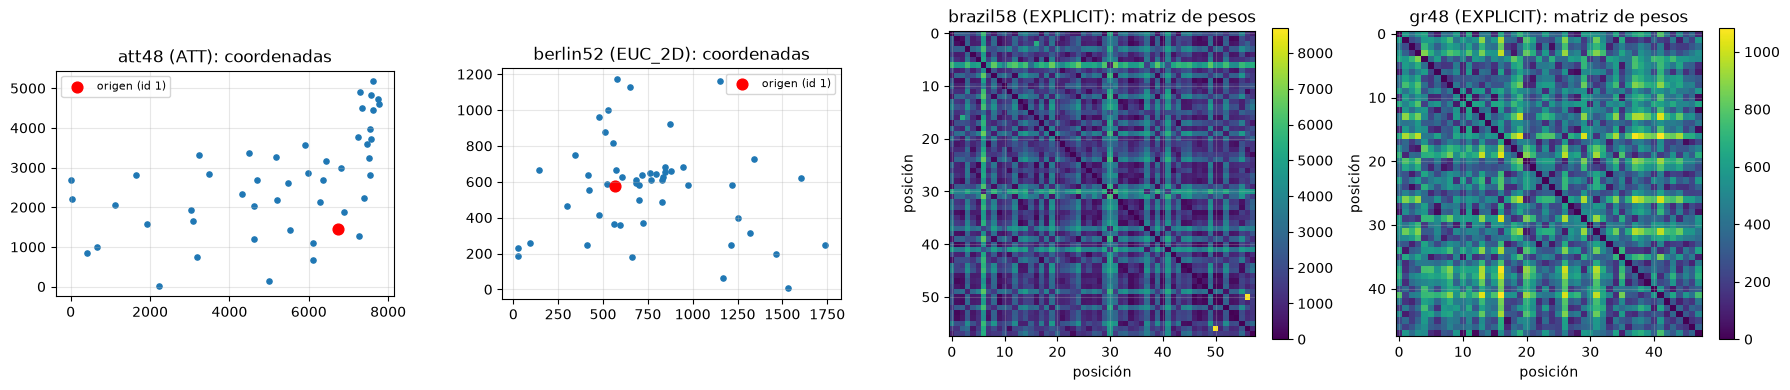

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, name in zip(axes[:2], ["att48", "berlin52"]):
    inst = INSTANCES[name]
    ax.scatter(inst.coords[:, 0], inst.coords[:, 1], s=14)
    ax.scatter(*inst.coords[0], s=60, c="red", label="origen (id %d)" % inst.node_ids[0])
    ax.set_title(f"{name} ({inst.weight_type}): coordenadas")
    ax.set_aspect("equal")
    ax.legend(fontsize=8)
for ax, name in zip(axes[2:], ["brazil58", "gr48"]):
    inst = INSTANCES[name]
    im = ax.imshow(inst.D, cmap="viridis")
    ax.set_title(f"{name} ({inst.weight_type}): matriz de pesos")
    ax.set_xlabel("posición")
    ax.set_ylabel("posición")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

### C. Modelo de búsqueda, MST y microcaso

*Agregue desarrollo manual, componentes y prueba de admisibilidad.*

### C.1 Lectura crítica de TSP Solve (actividad de la sección 1)

Leímos el código MATLAB de las tres páginas: A*, RBFS y Hill Climbing. Encontramos lo siguiente.

**1. El "2-opt" del Hill Climbing es un swap.** La función `getNextSolution` hace:

```matlab
tempNode = newTour(p1);
newTour(p1) = curState.node(p2);
newTour(p2) = tempNode;
```

Eso **intercambia las ciudades** de las posiciones `p1` y `p2`. El comentario y el texto lo llaman "2-opt neighbours", pero no lo es. Un swap de posiciones no adyacentes cambia **4 aristas**; un 2-opt cambia exactamente **2**. Para que fuera 2-opt habría que invertir el tramo entre las dos aristas, por ejemplo con `newTour(p1+1:p2) = flip(newTour(p1+1:p2))`, y excluir los pares de aristas adyacentes (en E.1 lo comprobamos con código). Además, el ciclo acepta mejoras **dentro** del mismo recorrido del vecindario. Es decir, no es "mejor mejora" sino una mezcla de primera mejora con barrido completo.

**2. La clave de estado del A* "de grafo" es solo la ciudad.** Las listas `open` y `closed` se buscan con `ismember(nodelist(i).name, {closed.name})`: dos rutas parciales que terminan en la misma ciudad se tratan como **el mismo estado**, aunque les falten ciudades distintas. Después deciden con reglas de costo y **profundidad** (`s.depth > s_inClosed.depth`), que tampoco identifican el estado. Con esa regla se pueden descartar prefijos de la ruta óptima. Por eso la página reporta el óptimo solo desde 8 de los 48 orígenes: el resto da entre 10648 y 10795. **La clave correcta es `(última ciudad, conjunto de pendientes, cerrado)`**, la de la sección 5. En D.4 lo mostramos con datos: fusionando por ciudad y profundidad, nuestro A* también pierde el óptimo.

**3. Otros detalles del código:**

- En la versión de árbol y en RBFS, la `f` es `node.cost = node.h_n + node.g_n - node.depth`: le **resta la profundidad**. Eso ya no es $g+h$. Además, `isGoal` devuelve `solution.cost = node.cost`, así que el costo reportado queda corrido en $n-1$.
- En RBFS, `suc = nodelist(i); suc.cost = max(...)` modifica una **copia**: en MATLAB las estructuras se copian por valor. Por eso el `max` con la `f` del padre nunca se guarda en `nodelist`.
- La sección de código "A* (tree search)" en realidad llama a `RBFS(...)`: es una copia del código de RBFS.

**Qué debería tener la clave de un estado de A\*:** la ciudad actual, el **conjunto** de ciudades pendientes y si el ciclo ya se cerró, con el origen fijo. Dos nodos con la misma clave tienen exactamente las mismas continuaciones posibles. Por eso, entre ellos, basta quedarse con el de menor $g$. Esa es la única fusión segura.

No usamos los tiempos publicados como meta: son de otro lenguaje, otra máquina y otro código.

### C.2 Modelo de búsqueda: rutas parciales (sección 5)

Un nodo guarda `last`, `remaining`, `g`, `closed`, `parent` y `depth`. Las ciudades pendientes se guardan como una **máscara de bits**: el bit $v$ vale 1 si la ciudad $v$ falta. Así la clave `(last, remaining, closed)` es inmutable y se puede usar en un diccionario. Los sucesores se generan en orden creciente de posición. Eso hace que todo sea determinista.

In [9]:
@dataclass(frozen=True, slots=True)
class SearchNode:
    last: int
    remaining: int        # bitmask over positions still to visit
    g: int
    closed: bool
    parent: object
    depth: int


def bits(mask):
    """Positions set in mask, in increasing order (deterministic successor order)."""
    while mask:
        low = mask & -mask
        yield low.bit_length() - 1
        mask ^= low


def root_node(n, start=0):
    return SearchNode(start, ((1 << n) - 1) & ~(1 << start), 0, False, None, 0)


def successors(W, node, start=0, close_cycle=True):
    if node.closed:
        return []
    if node.remaining == 0:
        if not close_cycle:
            return []
        return [SearchNode(start, 0, node.g + W[node.last][start], True, node, node.depth + 1)]
    return [SearchNode(v, node.remaining & ~(1 << v), node.g + W[node.last][v], False, node, node.depth + 1)
            for v in bits(node.remaining)]


def state_key(node):
    return (node.last, node.remaining, node.closed)


def reconstruct(node):
    path = []
    while node is not None:
        path.append(node.last)
        node = node.parent
    path.reverse()
    return path[:-1] if len(path) > 1 and path[-1] == path[0] else path   # drop the closing return

### C.3 Prim en $O(|U|^2)$ y la cota MST (secciones 6 y 6.1)

`prim` guarda, para cada ciudad que todavía no está en el árbol, su conexión más barata al árbol. En cada paso agrega la más barata y actualiza las demás con una sola pasada. Son $|U|$ pasos de $O(|U|)$, o sea $O(|U|^2)$, como pide 6.1.

`MSTHeuristic` aplica la fórmula de la sección 6 y cuenta las llamadas al MST. La opción `use_cache` guarda el MST de cada conjunto de pendientes; es el experimento opcional de 6.1 y solo la usamos en D.6. Con `kind="zero"` la heurística vale siempre 0, y A* se vuelve búsqueda de costo uniforme.

In [10]:
def prim(W, nodes):
    """MST of the complete graph on `nodes` with O(k^2) Prim: keep each outside node's cheapest link."""
    nodes = list(nodes)
    if len(nodes) <= 1:
        return 0, []
    best = {v: (W[nodes[0]][v], nodes[0]) for v in nodes[1:]}
    total, edges = 0, []
    while best:
        v = min(best, key=lambda u: best[u][0])
        cost, parent = best.pop(v)
        total += cost
        edges.append((parent, v))
        for u in best:
            if W[v][u] < best[u][0]:
                best[u] = (W[v][u], v)
    return total, edges


class MSTHeuristic:
    """h(v, U) of section 6. kind='zero' gives h = 0 (uniform-cost search) with the same interface."""

    def __init__(self, W, start=0, kind="mst", close_cycle=True, use_cache=False):
        self.W, self.start, self.kind, self.close_cycle = W, start, kind, close_cycle
        self.cache = {} if use_cache else None
        self.mst_calls = 0
        self.cache_hits = 0

    def mst(self, mask):
        if self.cache is not None and mask in self.cache:
            self.cache_hits += 1
            return self.cache[mask]
        self.mst_calls += 1
        value = prim(self.W, bits(mask))[0]
        if self.cache is not None:
            self.cache[mask] = value
        return value

    def __call__(self, node):
        if node.closed or self.kind == "zero":
            return 0
        W, s = self.W, self.start
        if node.remaining == 0:
            return W[node.last][s] if self.close_cycle else 0
        U = list(bits(node.remaining))
        h = self.mst(node.remaining) + min(W[node.last][u] for u in U)
        if self.close_cycle:
            h += min(W[u][s] for u in U)
        return h

### C.4 Por qué la cota MST es admisible (con nuestras palabras)

Estamos en la ciudad $v$, nos faltan las ciudades $U$ y el origen es $s$. Tomemos **cualquier** forma de terminar el ciclo: $v \to u_1 \to u_2 \to \dots \to u_m \to s$, donde $u_1, \dots, u_m$ son las ciudades de $U$ en algún orden. Su costo tiene tres partes:

1. **La primera arista** $v \to u_1$. Como $u_1$ está en $U$, cuesta al menos $\min_{u\in U} d(v,u)$.
2. **El camino interno** $u_1 \to \dots \to u_m$. Es un camino que toca todas las ciudades de $U$ sin ciclos; un camino así es un **árbol** que conecta todo $U$. El MST es el árbol más barato que conecta $U$, así que este camino cuesta al menos $\operatorname{MST}(U)$.
3. **La última arista** $u_m \to s$. Cuesta al menos $\min_{u\in U} d(u,s)$.

Sumando: cualquier continuación cuesta al menos $h(v,U)$. Entonces $h$ **nunca sobreestima** lo que falta: es admisible.

Casos frontera:

- Si queda un solo pendiente $u$: $\operatorname{MST}=0$ y $h = d(v,u) + d(u,s)$, que es **exactamente** lo que falta.
- Si no queda ninguno pero falta cerrar: $h = d(v,s)$, también exacto.
- Si el ciclo está cerrado: $h=0$.

No usamos la desigualdad triangular en ningún paso. Solo usamos que los pesos no son negativos (un camino es un árbol válido) y que el TSP es simétrico (la arista $u_m \to s$ pesa lo mismo que $s \to u_m$).

En la raíz los dos mínimos pueden escoger **la misma ciudad**. Por ejemplo, en el microcaso los dos escogen E. Ninguna ruta real usa dos veces la ciudad más cercana al origen como primera y última, así que la cota queda floja, pero sigue siendo válida.

**Consistencia.** Vamos un paso más allá: también es consistente. Sea $n'$ el hijo que va de $v$ a $u \in U$, con $U' = U - \{u\}$ y costo de paso $c = d(v,u)$. Hay que ver que $h(v,U) \le d(v,u) + h(u,U')$, comparando término a término:

- $\operatorname{MST}(U) \le \operatorname{MST}(U') + \min_{w\in U'} d(u,w)$. Al MST de $U'$ le pegamos $u$ con su arista más barata y obtenemos un árbol que conecta $U$. El MST de $U$ no puede ser más caro que ese árbol.
- $\min_{w\in U} d(v,w) \le d(v,u)$, porque $u \in U$.
- $\min_{w\in U} d(w,s) \le \min_{w\in U'} d(w,s)$, porque $U' \subseteq U$: tomar el mínimo sobre más ciudades nunca da más.

Al sumar las tres desigualdades sale $h(n) \le c + h(n')$. Para el último paso ($U'=\varnothing$) y para el cierre, la cota es exacta y la igualdad se cumple. Abajo lo comprobamos además con código en todas las transiciones de casos pequeños.

Aun así, nuestro A* **no depende** de la consistencia: permite reabrir un estado si llega con mejor $g$ (`bestG`), como pide la sección 7.

**Un MST no es una ruta.** El MST no exige grado 2: una ciudad puede tener 3 ramas o más. Tampoco cierra un ciclo. En el microcaso, el MST de $\{B,C,D,E\}$ es $B{-}C$, $C{-}D$, $D{-}E$ y cuesta 7. Pero ninguna ruta puede "recorrerlo" gratis: para pasar de una rama a otra hay que volver por aristas ya usadas, y eso cuesta. Eso es lo que la relajación pierde: el **orden** y la obligación de **entrar y salir** de cada ciudad una sola vez.

### C.5 Microcaso manual (sección 6.2)

Lo resolvimos primero a mano. La celda de código de más abajo solo **verifica** estas cuentas.

Matriz: A-B 4, A-C 6, A-D 7, A-E 3, B-C 2, B-D 5, B-E 6, C-D 3, C-E 4, D-E 2. Origen A.

**Raíz.** $U=\{B,C,D,E\}$. El MST es B-C (2), D-E (2) y C-D (3), y cuesta 7. Conexión desde A: $\min = 3$ (E). Regreso a A: $\min = 3$ (E otra vez). $h = 7+3+3 = 13$, $f = 13$.

**1. Hijos de la raíz:**

| Hijo | $g$ | $U$ | MST de $U$ | conexión desde el hijo | regreso a A | $h$ | $f$ |
|---|---:|---|---|---:|---:|---:|---:|
| A→B | 4 | C, D, E | C-D 3 + D-E 2 = 5 | B-C = 2 | E-A = 3 | 10 | **14** |
| A→C | 6 | B, D, E | D-E 2 + B-D 5 = 7 | C-B = 2 | E-A = 3 | 12 | 18 |
| A→D | 7 | B, C, E | B-C 2 + C-E 4 = 6 | D-E = 2 | E-A = 3 | 11 | 18 |
| A→E | 3 | B, C, D | B-C 2 + C-D 3 = 5 | E-D = 2 | B-A = 4 | 11 | **14** |

**2. Primer empate y regla de desempate.** El primer empate aparece ya en la frontera inicial: A→B y A→E tienen $f = 14$. Nuestra regla, que usan A* y RBFS, es:

1. menor $f$;
2. si empatan, el nodo **más profundo**, porque está más cerca de cerrar un ciclo;
3. si siguen empatados, el que se generó primero (orden creciente de ciudad).

Como A→B y A→E tienen la misma profundidad, gana **A→B** por orden de generación. Al expandir A→B aparecen sus hijos:

| Hijo de A→B | $g$ | $U$ | $h$ | $f$ |
|---|---:|---|---:|---:|
| A→B→C | 6 | D, E | MST 2 + C-D 3 + E-A 3 = 8 | **14** |
| A→B→D | 9 | C, E | MST 4 + D-E 2 + E-A 3 = 9 | 18 |
| A→B→E | 10 | C, D | MST 3 + E-D 2 + C-A 6 = 11 | 21 |

Ahora empatan A→E ($f=14$, profundidad 1) y A→B→C ($f=14$, profundidad 2). Gana A→B→C por ser más profundo. Siguiendo así, A* expande A, AB, ABC, ABCD y ABCDE, y saca el nodo cerrado con **costo 14**.

**3. Cota con un pendiente y sin pendientes.**

- Prefijo A→B→C→D ($g=9$), $U=\{E\}$: $h = 0 + d(D,E) + d(E,A) = 2+3 = 5$. Es exactamente lo que falta: $f = 14$.
- Prefijo A→B→C→D→E ($g=11$), sin pendientes pero sin cerrar: $h = d(E,A) = 3$, $f = 14$.
- Al cerrar: $g = 14$, $h = 0$.

**4. Primeros cambios de límite en RBFS.** Se llama RBFS(A, límite $=\infty$). Los hijos quedan con $f$ = máx($g+h$, 13): B 14, E 14, C 18, D 18.

- El mejor es B (14). La alternativa es E (14), así que se baja a B con límite $\min(\infty, 14) = 14$.
- En B, los hijos son C 14, D 18, E 21. El mejor es C (14) y la alternativa 18; el nuevo límite es $\min(14, 18) = 14$.
- En A→B→C, los hijos son D 14 y E 19. Para A→B→C→E: $g = 10$, $h = 0 + d(E,D) + d(D,A) = 2 + 7 = 9$, $f = 19$. Se baja a D con límite 14.
- Luego A→B→C→D→E (14) y el cierre (14 ≤ 14): **encontrado**.

El límite pasa de $\infty$ a 14 y se queda ahí. RBFS **nunca retrocede** en el microcaso porque la cota es exacta en el camino óptimo. Si en algún momento la $f$ hubiera subido por encima de 14, RBFS habría guardado ese valor en B y habría vuelto a E. En D.3 mostramos una traza de 6 ciudades donde sí retrocede.

**5. Swap contra 2-opt sobre la misma ruta** A-B-C-D-E-A (costo 14):

- **2-opt** con $i=0$, $j=2$: quita A-B y C-D, pone A-C y B-D, invierte el tramo B C. Queda **A-C-B-D-E**, con $\Delta = 6+5-4-3 = +4$, o sea 18.
- **Swap** de las posiciones 1 y 3 (B y D): queda **A-D-C-B-E**, con costo $7+3+2+6+3 = 21$. Si se mira bien, eso es invertir el tramo B C D, es decir, el 2-opt con $i=0$, $j=3$: $\Delta = d(A,D)+d(B,E)-d(A,B)-d(D,E) = 7+6-4-2 = +7$.

En un ciclo de 5 ciudades **todo swap coincide con algún 2-opt**. Las dos ciudades intercambiadas quedan a distancia 1 o 2 en el ciclo, contando por cualquiera de los dos lados, y así el swap equivale a invertir el tramo entre ellas. Con 6 ciudades o más ya no pasa: un swap de posiciones lejanas cambia **4** aristas y un 2-opt siempre cambia **2**. En E.1 lo comprobamos enumerando todos los swaps.

In [11]:
MICRO = np.array([[0, 4, 6, 7, 3],
                  [4, 0, 2, 5, 6],
                  [6, 2, 0, 3, 4],
                  [7, 5, 3, 0, 2],
                  [3, 6, 4, 2, 0]])
micro = TSPInstance("micro", "EXPLICIT", "FULL_MATRIX", list("ABCDE"), MICRO)
LET = "ABCDE"
name_of = lambda path: "-".join(LET[p] for p in path)

H = MSTHeuristic(micro.W)
root = root_node(5)
assert H(root) == 13
rows = []
for child in successors(micro.W, root):
    rows.append((name_of(reconstruct(child)), child.g, H(child), child.g + H(child)))
    for grandchild in (successors(micro.W, child) if child.last == 1 else []):
        rows.append((name_of(reconstruct(grandchild)), grandchild.g, H(grandchild), grandchild.g + H(grandchild)))
table = pd.DataFrame(rows, columns=["prefijo", "g", "h", "f"])
display(table)
assert table.set_index("prefijo")["f"].to_dict() == {"A-B": 14, "A-B-C": 14, "A-B-D": 18, "A-B-E": 21,
                                                     "A-C": 18, "A-D": 18, "A-E": 14}
# one pending and no pending
n_abcd = successors(micro.W, successors(micro.W, successors(micro.W, root)[0])[0])[0]
assert name_of(reconstruct(n_abcd)) == "A-B-C-D" and H(n_abcd) == 5
n_abcde = successors(micro.W, n_abcd)[0]
assert H(n_abcde) == 3 and H(successors(micro.W, n_abcde)[0]) == 0
print("microcaso: g, h y f de la tabla manual verificados")

,prefijo,g,h,f
0,A-B,4,10,14
1,A-B-C,6,8,14
2,A-B-D,9,9,18
3,A-B-E,10,11,21
4,A-C,6,12,18
5,A-D,7,11,18
6,A-E,3,11,14


microcaso: g, h y f de la tabla manual verificados


### C.6 Oráculos exactos para pruebas pequeñas

Para probar A* y RBFS necesitamos saber la respuesta correcta por otro camino. Usamos dos oráculos independientes de la búsqueda:

- **`brute_force`**: prueba todas las permutaciones, $(k-1)!$ rutas. Se usa hasta $k=10$, que son 362 880 rutas.
- **`held_karp`**: programación dinámica sobre subconjuntos, $O(k^2 2^k)$. Calcula el óptimo de un modo completamente distinto y llega hasta $k=12$ en poco tiempo.

Solo se usan para probar, nunca dentro de la comparación.

In [12]:
def brute_force(inst, start=0):
    others = [v for v in range(inst.n) if v != start]
    best_cost, best_tour = INF, None
    for perm in itertools.permutations(others):
        tour = [start, *perm]
        c = tour_cost(inst.W, tour)
        if c < best_cost:
            best_cost, best_tour = c, tour
    return best_cost, best_tour


def held_karp(inst, start=0):
    W, n = inst.W, inst.n
    others = [v for v in range(n) if v != start]
    best = {(1 << v, v): W[start][v] for v in others}
    for size in range(2, n):
        for subset in itertools.combinations(others, size):
            mask = sum(1 << v for v in subset)
            for v in subset:
                prev = mask & ~(1 << v)
                best[(mask, v)] = min(best[(prev, u)] + W[u][v] for u in subset if u != v)
    full = sum(1 << v for v in others)
    return min(best[(full, v)] + W[v][start] for v in others)


cost, tour = brute_force(micro)
assert cost == 14 == held_karp(micro)
print("microcaso: óptimo", cost, "con la ruta", name_of(tour), "(y su reversa A-E-D-C-B)")

microcaso: óptimo 14 con la ruta A-B-C-D-E (y su reversa A-E-D-C-B)


### C.7 Dos rutas parciales que terminan en la misma ciudad (actividad de la sección 5)

Tomamos el subproblema de att48 con 6 ciudades. Comparamos dos prefijos que terminan en la misma ciudad y tienen la misma profundidad, pero distintas ciudades pendientes. Una regla que los fusione por "ciudad" (o por "ciudad y profundidad", como la de TSP Solve) conserva el de menor $g$ y tira el otro.

La celda busca un par así donde el prefijo descartado es el **único** que lleva al óptimo.

In [13]:
def all_prefixes(inst, start=0):
    stack, out = [root_node(inst.n, start)], []
    while stack:
        node = stack.pop()
        out.append(node)
        if node.remaining:
            stack.extend(successors(inst.W, node, start))
    return out


def best_completion(inst, node, start=0):
    rest = list(bits(node.remaining))
    if not rest:
        return inst.W[node.last][start]
    return min(sum(inst.W[a][b] for a, b in zip((node.last, *perm), perm)) + inst.W[perm[-1]][start]
               for perm in itertools.permutations(rest))


sub6 = INSTANCES["att48"].subproblem(6)
optimum6 = brute_force(sub6)[0]
example = None
prefixes = [p for p in all_prefixes(sub6) if 0 < p.depth < 5]
for a, b in itertools.combinations(prefixes, 2):
    if a.last == b.last and a.depth == b.depth and a.remaining != b.remaining:
        keep, drop = (a, b) if a.g <= b.g else (b, a)
        if drop.g + best_completion(sub6, drop) == optimum6 < keep.g + best_completion(sub6, keep):
            example = keep, drop
            break
ids = sub6.node_ids
for label, node in zip(["se conserva (menor g)", "se descarta"], example):
    print(f"{label:22s}: ruta {[ids[p] for p in reconstruct(node)]}, g = {node.g}, "
          f"faltan {[ids[p] for p in bits(node.remaining)]}, "
          f"mejor ciclo posible = {node.g + best_completion(sub6, node)}")
print("óptimo del subproblema:", optimum6)

se conserva (menor g) : ruta [1, 3, 5], g = 1159, faltan [2, 4, 6], mejor ciclo posible = 5879
se descarta           : ruta [1, 6, 5], g = 2676, faltan [2, 3, 4], mejor ciclo posible = 5715
óptimo del subproblema: 5715


**Lo que encontramos (C.7):** los dos prefijos terminan en la ciudad 5 y están a la misma profundidad. El conservado es más barato **hasta ahora**, pero le quedan por visitar ciudades que lo obligan a terminar caro. Al descartado le faltan otras ciudades, justo las que permiten cerrar el ciclo óptimo. Fusionarlos por ciudad tira el prefijo bueno, y el óptimo se vuelve **inalcanzable**: ningún otro nodo puede completarlo. Por eso la clave tiene que incluir el conjunto de pendientes.

### C.8 Pruebas del MST y de la heurística (tabla de la sección 13)

- **MST:** casos de 0, 1 y 2 pendientes; para conjuntos más grandes comparamos contra un Kruskal propio con unión-búsqueda y verificamos que Prim devuelve un árbol válido: $|U|-1$ aristas, que conectan todo y que suman el costo reportado.
- **Heurística admisible:** para **todos** los prefijos de dos subproblemas de 8 ciudades (uno EUC_2D y uno EXPLICIT), enumeramos todas las continuaciones posibles y verificamos que $h$ no supera el costo restante óptimo. Es el residual de cada prefijo, no el óptimo total.
- **Consistencia:** en esos mismos árboles revisamos $h(n) \le c(n,n') + h(n')$ en cada transición.

In [14]:
def kruskal(W, nodes):
    nodes = list(nodes)
    parent = {v: v for v in nodes}

    def find(v):
        while parent[v] != v:
            parent[v] = parent[parent[v]]
            v = parent[v]
        return v

    total = 0
    for w, a, b in sorted((W[a][b], a, b) for a, b in itertools.combinations(nodes, 2)):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[ra] = rb
            total += w
    return total


def is_spanning_tree(nodes, edges):
    nodes = set(nodes)
    if len(edges) != len(nodes) - 1:
        return False
    reached, frontier = {next(iter(nodes))}, [next(iter(nodes))]
    while frontier:
        v = frontier.pop()
        for a, b in edges:
            for x, y in ((a, b), (b, a)):
                if x == v and y not in reached:
                    reached.add(y)
                    frontier.append(y)
    return reached == nodes


W = INSTANCES["berlin52"].W
assert prim(W, []) == (0, []) and prim(W, [7]) == (0, [])
assert prim(W, [3, 9]) == (W[3][9], [(3, 9)])
rng = random.Random(7)
for _ in range(300):
    nodes = rng.sample(range(52), rng.randint(2, 20))
    total, edges = prim(W, nodes)
    assert is_spanning_tree(nodes, edges) and total == sum(W[a][b] for a, b in edges) == kruskal(W, nodes)
print("MST: 0, 1 y 2 nodos OK; 300 conjuntos aleatorios iguales a Kruskal y con árbol válido")

for name in ["berlin52", "gr48"]:
    sub = INSTANCES[name].subproblem(8)
    H = MSTHeuristic(sub.W)
    nodes = all_prefixes(sub)
    ratios, violations_h, violations_c = [], 0, 0
    for node in nodes:
        residual = best_completion(sub, node)
        h = H(node)
        violations_h += h > residual
        if residual > 0:
            ratios.append(h / residual)
        for child in successors(sub.W, node):
            violations_c += h > (child.g - node.g) + H(child)
    closing = [c for nd in nodes if nd.remaining == 0 for c in successors(sub.W, nd)]
    assert all(H(c) == 0 for c in closing)
    assert violations_h == 0 and violations_c == 0
    print(f"{name} k=8: {len(nodes)} prefijos, h <= residual en todos; consistencia en todas las transiciones; "
          f"h/residual medio = {np.mean(ratios):.3f} (mínimo {min(ratios):.3f})")

MST: 0, 1 y 2 nodos OK; 300 conjuntos aleatorios iguales a Kruskal y con árbol válido
berlin52 k=8: 13700 prefijos, h <= residual en todos; consistencia en todas las transiciones; h/residual medio = 0.977 (mínimo 0.763)


gr48 k=8: 13700 prefijos, h <= residual en todos; consistencia en todas las transiciones; h/residual medio = 0.974 (mínimo 0.640)


**Lo que encontramos (C.8):**

- La cota nunca falla y es consistente en todas las transiciones.
- El promedio de $h$/residual sale muy alto (0.97) porque la mayoría de los 13 700 prefijos son profundos, y ahí la cota es casi exacta: con 1 o 0 pendientes es exacta.
- Lo importante es el **mínimo**: 0.76 en berlin52 y 0.64 en gr48. Cerca de la raíz, la cota deja sin contar entre una cuarta y una tercera parte de lo que falta. Ahí la relajación pierde más, porque el MST no exige grado 2 y los dos mínimos pueden ser la misma ciudad.
- Ese hueco cerca de la raíz es el que hace crecer la búsqueda cuando $n$ aumenta.

### D. A* y RBFS

*Agregue implementaciones, trazas, validación exacta y pruebas de interrupción.*

### D.1 A* con MST (sección 7)

Seguimos el pseudocódigo de la sección 7 casi línea por línea:

- La frontera es un montículo (`heapq`) con entradas `(f, -profundidad, contador, nodo)`. Así el desempate es el de C.5: menor $f$, luego el más profundo, luego el que se generó primero. El contador hace que nunca se comparen dos nodos directamente.
- `bestG` guarda el mejor $g$ conocido por **clave de estado** `(last, remaining, closed)`. Si llega un hijo con mejor $g$, se inserta aunque el estado ya se haya expandido. Las entradas viejas de la cola se saltan al sacarlas y se cuentan como `stale`.
- La meta se prueba **al sacar** el nodo de la cola, no al generarlo. Eso es lo que garantiza optimalidad con una $h$ admisible.
- Contamos expansiones, nodos generados, entradas obsoletas, llamadas al MST y el tamaño máximo de la frontera.

El parámetro `key_mode` existe solo para la demostración de D.5: `"last_city"` y `"city_depth"` son las reglas de fusión **incorrectas** (la segunda es la de TSP Solve). `close_cycle=False` es la meta incorrecta de la pregunta 4 (aceptar el primer nodo sin pendientes sin cobrar el regreso). Con los valores por defecto, el algoritmo es el correcto y el único que reporta `OPTIMAL`.

In [15]:
def astar(inst, budget=EXACT_BUDGET, h_kind="mst", start=0, use_cache=False, close_cycle=True,
          key_mode="state", trace=None):
    """A* over partial routes. key_mode 'last_city' and 'city_depth' are wrong merge rules, kept for the demo."""
    W, n = inst.W, inst.n
    meter = Meter(**budget)
    H = MSTHeuristic(W, start, h_kind, close_cycle, use_cache)
    key = {"state": state_key,
           "last_city": lambda nd: (nd.last, nd.closed),
           "city_depth": lambda nd: (nd.last, nd.depth, nd.closed)}[key_mode]
    root = root_node(n, start)
    tie = itertools.count()
    open_heap = [(H(root), 0, next(tie), root)]
    best_g = {key(root): 0}
    expanded = generated = stale = 0
    frontier_peak = 1
    goal, reason = None, "EXHAUSTED"
    try:
        while open_heap:
            meter.check_search(expanded)
            f, _, _, node = heapq.heappop(open_heap)
            if node.g > best_g[key(node)]:
                stale += 1
                continue
            if node.closed or (not close_cycle and node.remaining == 0):
                goal, reason = node, "GOAL"
                break
            expanded += 1
            children = successors(W, node, start, close_cycle)
            if trace is not None:
                trace.append({"step": expanded, "expanded": reconstruct(node), "g": node.g, "f": f,
                              "frontier_before": len(open_heap) + 1})
            for child in children:
                generated += 1
                k = key(child)
                if child.g < best_g.get(k, INF):
                    best_g[k] = child.g
                    heapq.heappush(open_heap, (child.g + H(child), -child.depth, next(tie), child))
            frontier_peak = max(frontier_peak, len(open_heap))
    except Interrupted as stop:
        reason = stop.reason
    elapsed, peak = meter.finish()
    tour = reconstruct(goal) if goal is not None else None
    cost = tour_cost(W, tour) if tour is not None else None
    exact = reason == "GOAL" and key_mode == "state" and close_cycle
    return RunResult(inst.name, inst.subset, "A* + MST" if h_kind == "mst" else "A* (h=0)", None,
                     dict(h=h_kind, start=start, cache=use_cache, key=key_mode, close_cycle=close_cycle),
                     tour, cost, gap_percent(cost, inst.optimum), elapsed, peak, reason,
                     "OPTIMAL" if exact else ("NO_TOUR" if tour is None else "NOT_CERTIFIED"),
                     expanded=expanded, generated=generated, mst_calls=H.mst_calls, frontier_peak=frontier_peak,
                     stale=stale, extra=dict(cache_hits=H.cache_hits, path_cost=goal.g if goal else None))

### D.2 RBFS (secciones 8 y 8.1)

Es el pseudocódigo de la sección 8 con el mismo modelo de estados y la misma cota MST que A*:

- Cada hijo recibe $f = \max(g + h,\ f_{padre})$, donde $f_{padre}$ es el valor **respaldado** con que se llamó al padre.
- Se baja al mejor hijo con límite $\min(\text{límite}, \text{segunda mejor } f)$. Al volver, el hijo guarda el $f$ respaldado que devolvió la llamada (`best[0] = ...`); por eso cada hijo es una lista mutable `[f, nodo]` y no una copia.
- El orden es estable (`sort` de Python): los empates conservan el orden de generación. Es el mismo desempate de A* salvo la profundidad, que entre hermanos siempre es igual.
- Las interrupciones son excepciones (`Interrupted`) que atraviesan toda la recursión: no se confunden con un fracaso.

**Instrumentación (8.1).** Contamos expansiones, llamadas, profundidad máxima y `retained_peak`: el máximo de registros `[f, nodo]` vivos a la vez en toda la pila de recursión. Ese es el $O(bd)$ de la teoría. Las **regeneraciones** se miden con un registro externo de auditoría (`audit=True`): un conjunto con la clave de cada estado ya expandido; si vuelve a aparecer, es una regeneración. Ese conjunto crece sin límite, así que **sí altera la memoria**. Por eso las corridas que miden memoria y tiempo van con `audit=False`, y el conteo de regeneraciones sale de una corrida aparte.

In [16]:
def rbfs(inst, budget=EXACT_BUDGET, h_kind="mst", start=0, audit=False, trace=None):
    """Recursive best-first search with backed-up f values (section 8). audit=True counts regenerations."""
    W, n = inst.W, inst.n
    meter = Meter(**budget)
    H = MSTHeuristic(W, start, h_kind)
    st = dict(expanded=0, generated=0, calls=0, max_depth=0, retained=1, retained_peak=1, regenerations=0)
    seen = set() if audit else None    # external audit record; it costs memory, so it is off when measuring

    def search(node, f_node, limit):
        st["calls"] += 1
        st["max_depth"] = max(st["max_depth"], node.depth)
        meter.check_search(st["expanded"])
        if node.closed:
            return node, f_node
        children = successors(W, node, start)
        st["expanded"] += 1
        st["generated"] += len(children)
        if audit:
            k = state_key(node)
            if k in seen:
                st["regenerations"] += 1
            else:
                seen.add(k)
        if not children:
            return None, INF
        entries = [[max(c.g + H(c), f_node), c] for c in children]
        st["retained"] += len(entries)
        st["retained_peak"] = max(st["retained_peak"], st["retained"])
        try:
            while True:
                entries.sort(key=lambda e: e[0])          # stable: ties keep successor order
                best = entries[0]
                if best[0] == INF or best[0] > limit:
                    return None, best[0]
                alternative = entries[1][0] if len(entries) > 1 else INF
                if trace is not None:
                    trace.append({"call": st["calls"], "node": reconstruct(node), "limit": limit,
                                  "best": reconstruct(best[1]), "best_f": best[0], "alternative": alternative})
                result, best[0] = search(best[1], best[0], min(limit, alternative))
                if result is not None:
                    return result, best[0]
        finally:
            st["retained"] -= len(entries)

    root = root_node(n, start)
    goal, reason = None, "EXHAUSTED"
    try:
        goal, _ = search(root, H(root), INF)
        reason = "GOAL" if goal is not None else "EXHAUSTED"
    except Interrupted as stop:
        reason = stop.reason
    except RecursionError:
        reason = "RECURSION"
    elapsed, peak = meter.finish()
    tour = reconstruct(goal) if goal is not None else None
    cost = tour_cost(W, tour) if tour is not None else None
    return RunResult(inst.name, inst.subset, "RBFS + MST" if h_kind == "mst" else "RBFS (h=0)", None,
                     dict(h=h_kind, start=start, audit=audit), tour, cost, gap_percent(cost, inst.optimum),
                     elapsed, peak, reason, "OPTIMAL" if reason == "GOAL" else "NO_TOUR",
                     expanded=st["expanded"], generated=st["generated"], mst_calls=H.mst_calls,
                     frontier_peak=st["retained_peak"], regenerations=st["regenerations"] if audit else None,
                     calls=st["calls"], max_depth=st["max_depth"])

### D.3 Trazas

Primero el microcaso de C.5, para comparar con lo que hicimos a mano. Después una subinstancia de 6 ciudades donde RBFS **sí retrocede**.

In [17]:
trace_a, trace_r = [], []
res_a = astar(micro, trace=trace_a)
res_r = rbfs(micro, trace=trace_r)
show = lambda rows, cols: pd.DataFrame(rows).assign(**{c: lambda d, c=c: d[c].map(name_of) for c in cols})
print("A* en el microcaso:")
display(show(trace_a, ["expanded"]))
print("RBFS en el microcaso:")
display(show(trace_r, ["node", "best"]))
assert [name_of(t["expanded"]) for t in trace_a] == ["A", "A-B", "A-B-C", "A-B-C-D", "A-B-C-D-E"]
assert res_a.cost == res_r.cost == 14 and res_a.optimality_status == res_r.optimality_status == "OPTIMAL"
assert [t["limit"] for t in trace_r] == [INF, 14, 14, 14, 14]

A* en el microcaso:


,step,expanded,g,f,frontier_before
0,1,A,0,13,1
1,2,A-B,4,14,4
2,3,A-B-C,6,14,6
3,4,A-B-C-D,9,14,7
4,5,A-B-C-D-E,11,14,7


RBFS en el microcaso:


,call,node,limit,best,best_f,alternative
0,1,A,inf,A-B,14,14.0
1,2,A-B,14.0,A-B-C,14,18.0
2,3,A-B-C,14.0,A-B-C-D,14,19.0
3,4,A-B-C-D,14.0,A-B-C-D-E,14,inf
4,5,A-B-C-D-E,14.0,A-B-C-D-E,14,inf


In [18]:
base = INSTANCES["berlin52"]
pos6 = list(range(22, 28))
case6 = TSPInstance("berlin52", base.weight_type, None, [base.node_ids[p] for p in pos6],
                    base.D[np.ix_(pos6, pos6)].copy(), base.coords[pos6], None, "ids 23-28")
ids6 = case6.node_ids
label6 = lambda path: "-".join(str(ids6[p]) for p in path)
trace6 = []
res6 = rbfs(case6, trace=trace6, audit=True)
t6 = pd.DataFrame(trace6)
for c in ["node", "best"]:
    t6[c] = t6[c].map(label6)
display(t6)
backtracks = sum(1 for a, b in zip(trace6, trace6[1:]) if len(b["node"]) <= len(a["node"]))
print(f"costo {res6.cost} (fuerza bruta {brute_force(case6)[0]}), llamadas {res6.calls}, "
      f"expansiones {res6.expanded}, regeneraciones {res6.regenerations}, retrocesos {backtracks}")
assert res6.cost == brute_force(case6)[0] and backtracks > 0 and res6.regenerations > 0
H6 = MSTHeuristic(case6.W)
reentry_f = trace6[2]["best_f"]       # backed-up f of 23-24 when the root goes back to it
print(f"hijos de 23-24 al volver a entrar (f respaldado del padre = {reentry_f}):")
for c in successors(case6.W, successors(case6.W, root_node(6))[0]):
    print(f"  {label6(reconstruct(c))}: g+h = {c.g + H6(c)}, f asignado = max(g+h, {reentry_f}) = "
          f"{max(c.g + H6(c), reentry_f)}")

,call,node,limit,best,best_f,alternative
0,1,23,inf,23-24,1646,1789.0
1,2,23,inf,23-25,1789,1878.0
2,3,23,inf,23-24,1878,1878.0
3,4,23-24,1878.0,23-24-25,1878,2036.0
4,5,23-24-25,1878.0,23-24-25-28,1878,1977.0
5,6,23-24-25-28,1878.0,23-24-25-28-27,1878,2019.0
6,7,23-24-25-28-27,1878.0,23-24-25-28-27-26,1878,inf
7,8,23-24-25-28-27-26,1878.0,23-24-25-28-27-26,1878,inf


costo 1878 (fuerza bruta 1878), llamadas 9, expansiones 8, regeneraciones 1, retrocesos 2
hijos de 23-24 al volver a entrar (f respaldado del padre = 1878):
  23-24-25: g+h = 1878, f asignado = max(g+h, 1878) = 1878
  23-24-26: g+h = 2036, f asignado = max(g+h, 1878) = 2036
  23-24-27: g+h = 2108, f asignado = max(g+h, 1878) = 2108
  23-24-28: g+h = 2054, f asignado = max(g+h, 1878) = 2054


**Lo que encontramos (D.3):**

- **Microcaso.** A* expande A, A-B, A-B-C, A-B-C-D y A-B-C-D-E y devuelve 14, igual que a mano en C.5. RBFS sigue el mismo camino: el límite pasa de $\infty$ a 14 y no cambia. La alternativa de la raíz es 14 porque A-E empata con A-B.
- **Caso de 6 ciudades (berlin52, ids 23 a 28).** Aquí sí hay retroceso. Paso a paso:
  1. En la raíz, 23-24 es el mejor ($f=1646$) y la alternativa es 23-25 (1789). RBFS baja a 23-24 con límite 1789.
  2. Dentro de 23-24, el mejor hijo ya vale 1878 > 1789. La llamada **falla** y devuelve 1878: ese es el valor respaldado. La raíz lo guarda en 23-24. La rama no se borra, solo queda "en espera" con un $f$ más alto.
  3. Ahora el mejor es 23-25 (1789), y la alternativa es 1878. Baja a 23-25, que también falla y vuelve con un valor de al menos 1878.
  4. La raíz vuelve a ordenar: 23-24 (1878) empata con 23-26 (1878) y gana 23-24 por orden. **La rama descartada en el paso 2 reaparece**, y RBFS la expande de nuevo: esa es la regeneración que cuenta la auditoría (1). Desde ahí llega a la ruta de costo 1878, igual que la fuerza bruta.
- **La segunda alternativa** es el $f$ del mejor "plan B". Mientras la rama actual no pase de ese valor, conviene seguir en ella. Cuando lo pasa, se vuelve al plan B. Por eso el límite de cada llamada es $\min(\text{límite}, \text{alternativa})$.
- **Por qué el máximo.** El $f$ respaldado de un nodo resume lo que ya se supo de su subárbol. Al volver a entrar en 23-24 se sabe que nada debajo cuesta menos de 1878. El máximo pasa ese conocimiento a los hijos: ninguno puede figurar con un $f$ menor que el del padre. Si no se hiciera, un hijo con $g+h$ bajo parecería más barato de lo que ya sabemos que es, y RBFS volvería a bajar por él una y otra vez. En esta traza el máximo no cambia ningún número porque el 1878 venía justo del mejor nieto (23-24-25 tiene $g+h=1878$). Con una cota consistente como la nuestra, el máximo solo importa cuando el valor respaldado viene de varios niveles más abajo.

### D.4 Validación exacta y pruebas de la sección 7

Para cada instancia obligatoria y $k \in \{6, 8, 10, 12\}$ corremos A* (MST y $h=0$), A* con **otro origen** (la última posición) y RBFS, y comparamos contra el oráculo: fuerza bruta hasta $k=10$ y Held-Karp en $k=12$. Las corridas son independientes, así que se reparten entre núcleos con `parallel_map`; cada una mide su propio tiempo.

In [19]:
def exact_check(name, k):
    sub = INSTANCES[name].subproblem(k)
    oracle = brute_force(sub)[0] if k <= 10 else held_karp(sub)
    a, a0, a_other, r = astar(sub), astar(sub, h_kind="zero"), astar(sub, start=k - 1), rbfs(sub)
    for res in (a, a0, a_other):
        assert res.stop_reason == "GOAL" and is_valid_tour(res.tour, k, res.parameters["start"])
    assert a.cost == a0.cost == a_other.cost == oracle, (name, k)
    if r.stop_reason == "GOAL":
        assert r.cost == oracle and is_valid_tour(r.tour, k)
    return {"instancia": name, "k": k, "oráculo": oracle, "A* MST": a.cost, "A* h=0": a0.cost,
            "A* otro origen": a_other.cost, "RBFS": r.cost if r.cost is not None else "N/A",
            "RBFS parada": r.stop_reason, "exp. A* MST": a.expanded, "exp. A* h=0": a0.expanded,
            "exp. RBFS": r.expanded, "MST calls A*": a.mst_calls, "obsoletas A*": a.stale,
            "frontera máx A*": a.frontier_peak, "s A*": round(a.elapsed_seconds, 3),
            "s RBFS": round(r.elapsed_seconds, 2)}


exact = pd.DataFrame(parallel_map(exact_check, [(nm, k) for nm in MANDATORY for k in (6, 8, 10, 12)]))
display(exact)
print("A* (MST, h=0 y otro origen) coincide con el oráculo en los 16 casos;",
      f"RBFS terminó en {(exact['RBFS parada'] == 'GOAL').sum()} de 16 y coincide en todos los que terminó")

,instancia,k,oráculo,A* MST,A* h=0,A* otro origen,RBFS,RBFS parada,exp. A* MST,exp. A* h=0,exp. RBFS,MST calls A*,obsoletas A*,frontera máx A*,s A*,s RBFS
0,att48,6,5715,5715,5715,5715,5715,GOAL,22,81,39,53,0,33,0.003,0.00
1,att48,8,5919,5919,5919,5919,5919,GOAL,59,449,364,203,2,144,0.012,0.04
2,att48,10,6178,6178,6178,6178,6178,GOAL,170,2305,2898,729,6,555,0.032,0.42
3,att48,12,6209,6209,6209,6209,6209,GOAL,376,11264,32375,1701,31,1296,0.079,8.68
4,berlin52,6,2315,2315,2315,2315,2315,GOAL,27,81,64,57,0,32,0.003,0.00
5,berlin52,8,2551,2551,2551,2551,2551,GOAL,40,449,110,134,0,97,0.007,0.02
6,berlin52,10,2826,2826,2826,2826,2826,GOAL,62,2305,712,271,0,212,0.012,0.08
7,berlin52,12,4056,4056,4056,4056,4056,GOAL,437,11265,80651,1989,25,1529,0.092,16.15
8,brazil58,6,9025,9025,9025,9025,9025,GOAL,14,81,25,39,0,28,0.004,0.00
9,brazil58,8,17321,17321,17321,17321,17321,GOAL,223,449,57598,415,32,165,0.015,3.31


A* (MST, h=0 y otro origen) coincide con el oráculo en los 16 casos; RBFS terminó en 14 de 16 y coincide en todos los que terminó


**Lo que encontramos (D.4):**

- **A\* es exacto en los 16 casos.** Con MST, con $h=0$ y desde otro origen da el mismo costo que el oráculo. Cambiar el origen no cambia el óptimo, como debe ser: un ciclo es el mismo empiece donde empiece.
- **La cota MST ahorra mucho trabajo.** Con $h=0$ (costo uniforme), A* expande casi todos los estados posibles: unos 11 260 en $k=12$, sin importar la instancia. Con MST, en $k=12$, expande 376 en att48, 437 en berlin52 y 38 en gr48, entre 25 y 300 veces menos. brazil58 es la más difícil: 4478 expansiones, solo 2.5 veces menos que con $h=0$, y es la que más entradas obsoletas genera (1233), porque muchos estados se alcanzan primero por un camino caro y luego por uno mejor.
- **RBFS es exacto cuando termina**, pero se vuelve muy costoso. En $k=12$ hace 32 375 expansiones en att48 y 80 651 en berlin52, contra 376 y 437 de A*. En brazil58 se corta por el límite de 100 000 expansiones ya en $k=10$: lo reportamos como **interrumpido** (`N/A`), no como fracaso. La diferencia viene de las regeneraciones: RBFS no recuerda los estados, así que vuelve a expandir los mismos subárboles muchas veces (lo medimos con la auditoría en G).
- Los tiempos de esta tabla se midieron con varios casos corriendo en paralelo; los tiempos para comparar salen de G, con repeticiones.

### D.5 Reglas de fusión y de meta incorrectas (actividad de la sección 5 y preguntas 3 y 4)

Corremos el mismo A* cambiando solo la clave de fusión o la meta, y comparamos con el óptimo certificado:

- `last_city`: fusiona por ciudad final (pregunta 3).
- `city_depth`: fusiona por ciudad y profundidad, como TSP Solve.
- `close_cycle=False`: la meta es "no quedan pendientes" y la cota no cobra el regreso (pregunta 4).

In [20]:
rows = []
for name, k in [("att48", 6), ("att48", 8), ("brazil58", 10), ("gr48", 10), ("berlin52", 10)]:
    sub = INSTANCES[name].subproblem(k)
    opt = astar(sub).cost
    by_city, by_depth, no_return = (astar(sub, key_mode="last_city"), astar(sub, key_mode="city_depth"),
                                    astar(sub, close_cycle=False))
    rows.append({"instancia": name, "k": k, "óptimo": opt,
                 "last_city": by_city.cost if by_city.cost is not None else f"sin ruta ({by_city.stop_reason})",
                 "city_depth": by_depth.cost, "estado city_depth": by_depth.optimality_status,
                 "sin regreso: camino": no_return.extra["path_cost"], "sin regreso: ciclo": no_return.cost})
merge = pd.DataFrame(rows)
display(merge)
assert all(c != "OPTIMAL" for c in merge["estado city_depth"])
assert (merge["city_depth"] >= merge["óptimo"]).all() and (merge["sin regreso: ciclo"] >= merge["óptimo"]).all()

,instancia,k,óptimo,last_city,city_depth,estado city_depth,sin regreso: camino,sin regreso: ciclo
0,att48,6,5715,sin ruta (EXHAUSTED),5879,NOT_CERTIFIED,4151,6163
1,att48,8,5919,sin ruta (EXHAUSTED),6083,NOT_CERTIFIED,4355,6367
2,brazil58,10,17652,sin ruta (EXHAUSTED),19108,NOT_CERTIFIED,12501,18503
3,gr48,10,2431,sin ruta (EXHAUSTED),2486,NOT_CERTIFIED,2004,2570
4,berlin52,10,2826,sin ruta (EXHAUSTED),2826,NOT_CERTIFIED,2160,2826


**Lo que encontramos (D.5):**

- **Fusionar por la última ciudad (pregunta 3) no da ninguna ruta.** En los 5 casos A* termina con `EXHAUSTED`. El primer prefijo que llega a cada ciudad es el directo desde el origen, y casi siempre es el más barato. Cualquier prefijo más largo que termine en esa ciudad tiene $g$ mayor y se descarta. Así ningún prefijo pasa de unos pocos niveles y nunca se cierra un ciclo.
- **Fusionar por ciudad y profundidad (la regla de TSP Solve) da rutas, pero no óptimas:** 5879 contra 5715 en att48 $k=6$ (es el par de C.7), 6083 contra 5919, 19 108 contra 17 652 y 2486 contra 2431. En berlin52 $k=10$ salió justo el óptimo, 2826, pero por suerte: la regla no lo garantiza, y por eso el estado es `NOT_CERTIFIED` aunque el número coincida. Esto explica lo que reporta la página: óptimo solo desde algunos orígenes.
- **Aceptar como meta "sin pendientes" sin cobrar el regreso (pregunta 4)** devuelve el mejor **camino** abierto, no el mejor ciclo. En att48 $k=6$ el camino cuesta 4151; al cerrarlo, el ciclo cuesta 6163, un 7.8 % peor que el óptimo 5715. El camino más barato puede terminar lejos del origen, y el regreso se paga después. Otra vez, en berlin52 $k=10$ coincidió por suerte.

### D.6 Pruebas de interrupción y casos de RBFS (tabla de la sección 13)

- **Presupuesto:** forzamos cada límite (expansiones, tiempo y memoria) en una subinstancia de 12 ciudades. Debe salir el motivo correcto, sin ruta y con estado `NO_TOUR`, nunca un "fracaso" ni una ruta inventada.
- **RBFS, un hijo:** con 2 ciudades cada nodo tiene un único hijo; la alternativa es $\infty$.
- **RBFS, empate:** en la raíz del microcaso B y E empatan en 14; gana B (orden de generación) y la alternativa es 14.
- **RBFS, límite:** en la traza de 6 ciudades hay llamadas que devuelven fracaso porque el mejor hijo supera el límite, y después la rama se retoma.
- **Agotamiento:** una instancia sin ciclo posible (todas las aristas de una ciudad con peso infinito). A* y RBFS deben terminar con `EXHAUSTED` y sin ruta.

In [21]:
sub12 = INSTANCES["brazil58"].subproblem(12)
for solver in (astar, rbfs):
    for limit, expected in [(dict(expansions=5), "EXPANSIONS"), (dict(seconds=1e-6), "TIME"),
                            (dict(memory_mib=1e-4), "MEMORY")]:
        res = solver(sub12, budget=limit)
        assert res.stop_reason == expected and res.tour is None and res.optimality_status == "NO_TOUR", res
        assert res.stop_reason in INTERRUPTIONS
print("interrupciones forzadas: motivo correcto, sin ruta y sin certificado (A* y RBFS)")

two = TSPInstance("two", "EXPLICIT", None, [1, 2], np.array([[0, 5], [5, 0]]))
tr = []
res = rbfs(two, trace=tr)
assert res.cost == 10 and all(t["alternative"] == INF for t in tr)
assert trace_r[0]["best"] == [0, 1] and trace_r[0]["best_f"] == 14 and trace_r[0]["alternative"] == 14
# a call that fails (best f above its limit) returns before tracing; it shows up as a node visited again later
revisited = [label6(t["node"]) for i, t in enumerate(trace6) if any(u["node"] == t["node"] for u in trace6[:i])]
assert revisited
print("RBFS: un hijo, empate y retroceso verificados; nodos que se retoman en la traza de 6:", sorted(set(revisited)))

blocked = TSPInstance("blocked", "EXPLICIT", None, [1, 2, 3, 4], np.zeros((4, 4)))
blocked.W = [[0, 1, 1, INF], [1, 0, 1, INF], [1, 1, 0, INF], [INF, INF, INF, 0]]
for solver in (astar, rbfs):
    res = solver(blocked)
    assert res.stop_reason == "EXHAUSTED" and res.tour is None, res
print("agotamiento: A* y RBFS terminan con EXHAUSTED y sin ruta")

interrupciones forzadas: motivo correcto, sin ruta y sin certificado (A* y RBFS)
RBFS: un hijo, empate y retroceso verificados; nodos que se retoman en la traza de 6: ['23']
agotamiento: A* y RBFS terminan con EXHAUSTED y sin ruta


### D.7 Experimento opcional de 6.1: caché del MST

En A*, el mismo conjunto de pendientes aparece en varios estados: un estado es (ciudad, pendientes), y cada conjunto puede terminar en cualquiera de sus vecinos. Guardar `MST(U)` por conjunto evita repetir Prim. Medimos tiempo, memoria y llamadas con y sin caché en $k=12$. La caché **no** se usa en RBFS: crece con cada conjunto distinto y contradice la idea de memoria reducida (lo advierte 6.1).

In [22]:
def cache_run(name, use_cache):
    sub = INSTANCES[name].subproblem(12)
    best = min((astar(sub, use_cache=use_cache) for _ in range(3)), key=lambda r: r.elapsed_seconds)
    return {"instancia": name, "caché": use_cache, "s (mejor de 3)": round(best.elapsed_seconds, 4),
            "memoria MiB": round(best.peak_memory_mib, 2), "llamadas a Prim": best.mst_calls,
            "aciertos de caché": best.extra["cache_hits"], "costo": best.cost}


cache = pd.DataFrame([cache_run(nm, c) for nm in MANDATORY for c in (False, True)])
display(cache)
assert cache.groupby("instancia")["costo"].nunique().eq(1).all()

,instancia,caché,s (mejor de 3),memoria MiB,llamadas a Prim,aciertos de caché,costo
0,att48,False,0.0478,0.41,1701,0,6209
1,att48,True,0.0367,0.47,914,787,6209
2,berlin52,False,0.0565,0.45,1989,0,4056
3,berlin52,True,0.0394,0.51,927,1062,4056
4,brazil58,False,0.2721,2.08,9501,0,18372
5,brazil58,True,0.1953,2.22,2042,7459,18372
6,gr48,False,0.0061,0.05,238,0,2446
7,gr48,True,0.0056,0.06,205,33,2446


**Lo que encontramos (D.7):** la caché no cambia el resultado y reduce las llamadas a Prim: a la mitad en att48 y berlin52, y casi a la quinta parte en brazil58, que es donde más se repiten conjuntos. El tiempo baja menos (entre un 15 % y un 30 %; en gr48 casi no cambia), porque aun con caché cada estado calcula sus dos mínimos de conexión. La memoria sube un poco. En $k=12$ todo es pequeño, pero el número de conjuntos distintos crece como $2^k$, así que en instancias grandes una caché sin límite se come la memoria. Por eso la dejamos apagada en la comparación principal.

### D.8 Ampliación: gr17 y burma14 completas

Las dos instancias de ampliación son lo bastante pequeñas para probar los exactos sobre la instancia **completa** y compararlos con el óptimo oficial (2085 y 3323), con el mismo presupuesto de exactos.

In [23]:
ext = []
for name in ["burma14", "gr17"]:
    for solver in (astar, rbfs):
        res = solver(INSTANCES[name])
        ext.append({"instancia": name, "algoritmo": res.algorithm, "costo": res.cost if res.cost else "N/A",
                    "óptimo oficial": INSTANCES[name].optimum, "parada": res.stop_reason,
                    "estado": res.optimality_status, "expansiones": res.expanded,
                    "s": round(res.elapsed_seconds, 2), "MiB": round(res.peak_memory_mib, 1)})
        if res.stop_reason == "GOAL":
            assert res.cost == INSTANCES[name].optimum and res.gap_percent == 0
display(pd.DataFrame(ext))

,instancia,algoritmo,costo,óptimo oficial,parada,estado,expansiones,s,MiB
0,burma14,A* + MST,3323,3323,GOAL,OPTIMAL,2500,0.43,4.7
1,burma14,RBFS + MST,N/A,3323,EXPANSIONS,NO_TOUR,100000,24.76,0.0
2,gr17,A* + MST,2085,2085,GOAL,OPTIMAL,21355,5.16,35.6
3,gr17,RBFS + MST,N/A,2085,TIME,NO_TOUR,60763,30.00,0.0


**Lo que encontramos (D.8):** A* certifica el óptimo oficial de las dos instancias completas: 3323 en burma14 y 2085 en gr17, dentro del presupuesto de exactos. gr17 ya necesita unas 21 000 expansiones y unos 35 MiB. RBFS no termina ninguna de las dos: en burma14 se acaban las 100 000 expansiones y en gr17 los 30 segundos. Su memoria apenas se nota (redondea a 0.0 MiB), pero el tiempo se va en regenerar. Es la cara práctica de la frase de 8.1: menor memoria no implica menor tiempo.

**Resumen de D.** El A* bien formulado (clave completa, meta al sacar el nodo cerrado, reapertura con `bestG`) es exacto en todos los casos que probamos. Las dos reglas de fusión de la sección 5 y la meta sin regreso de la pregunta 4 dan respuestas incorrectas. RBFS es exacto cuando termina, usa muy poca memoria y paga con recomputación.

### E. Vecindad, HC y SA

*Agregue operadores, validación del delta y comparación controlada.*

### E.1 Vecindad 2-opt y swap (sección 9)

Una ruta es una lista `route[0..n-1]` con el origen en la posición 0. Un movimiento 2-opt `(i, j)` quita las aristas `(route[i], route[i+1])` y `(route[j], route[(j+1) mod n])`, e invierte el tramo de posiciones $i+1$ a $j$. Como $i \ge 0$, el tramo nunca incluye la posición 0 y el origen no se mueve.

- `two_opt_pairs(n)` lista los pares válidos: $0 \le i < j < n$, sin $j = i+1$ (aristas que se tocan) y sin $(0, n-1)$ (las dos aristas comparten el origen). Deben ser $n(n-3)/2$.
- `two_opt_delta` calcula $\Delta = d(a,c) + d(b,d) - d(a,b) - d(c,d)$ en $O(1)$. Cuando $j = n-1$, la arista $(c, d)$ es la de **cierre**, de vuelta al origen.
- `swap_move` intercambia dos ciudades. Lo usamos solo para la comparación con 2-opt; ningún algoritmo lo usa.

Antes de usar el delta lo validamos contra la versión lenta, que recalcula todo el costo con `tour_cost`.

In [24]:
def two_opt_pairs(n):
    return [(i, j) for i in range(n - 1) for j in range(i + 2, n) if not (i == 0 and j == n - 1)]


def two_opt_delta(W, route, i, j):
    n = len(route)
    a, b, c, d = route[i], route[i + 1], route[j], route[(j + 1) % n]
    return W[a][c] + W[b][d] - W[a][b] - W[c][d]


def two_opt_move(route, i, j):
    assert j > i + 1 and not (i == 0 and j == len(route) - 1), "adjacent edges"
    return route[:i + 1] + route[i + 1:j + 1][::-1] + route[j + 1:]


def swap_move(route, p, q):
    out = route[:]
    out[p], out[q] = out[q], out[p]
    return out


def random_tour(n, rng):
    return [0] + rng.sample(range(1, n), n - 1)


def initial_tour(inst, seed):
    """Shared initial tour for (instance, seed): its own RNG, separate from every algorithm's RNG (section 11.1)."""
    return random_tour(inst.n, random.Random(f"{inst.name}-{inst.subset}-init-{seed}"))


def edge_set(route):
    return {frozenset(e) for e in zip(route, route[1:] + route[:1])}


for n in range(4, 60):
    assert len(two_opt_pairs(n)) == n * (n - 3) // 2
rng = random.Random(3)
checked = 0
for name in MANDATORY:
    inst = INSTANCES[name]
    for _ in range(3):
        route = random_tour(inst.n, rng)
        base_cost = tour_cost(inst.W, route)
        for i, j in two_opt_pairs(inst.n):
            moved = two_opt_move(route, i, j)
            assert is_valid_tour(moved, inst.n)
            assert tour_cost(inst.W, moved) - base_cost == two_opt_delta(inst.W, route, i, j)
            assert len(edge_set(route) - edge_set(moved)) == 2
            checked += 1
print(f"2-opt: n(n-3)/2 pares para n = 4..59; {checked} movimientos con permutación válida, "
      "exactamente 2 aristas cambiadas y delta igual al recálculo completo (incluye la arista de cierre)")

for n in (5, 6, 8):
    route = list(range(n))
    opt_sets = [edge_set(two_opt_move(route, i, j)) for i, j in two_opt_pairs(n)]
    changed = collections.Counter()
    for p, q in itertools.combinations(range(1, n), 2):
        moved = swap_move(route, p, q)
        changed[(len(edge_set(route) - edge_set(moved)), edge_set(moved) in opt_sets)] += 1
    print(f"n={n}: swaps por (aristas cambiadas, coincide con algún 2-opt) -> {dict(changed)}")

2-opt: n(n-3)/2 pares para n = 4..59; 15087 movimientos con permutación válida, exactamente 2 aristas cambiadas y delta igual al recálculo completo (incluye la arista de cierre)
n=5: swaps por (aristas cambiadas, coincide con algún 2-opt) -> {(2, True): 6}
n=6: swaps por (aristas cambiadas, coincide con algún 2-opt) -> {(2, True): 8, (4, False): 2}
n=8: swaps por (aristas cambiadas, coincide con algún 2-opt) -> {(2, True): 12, (4, False): 9}


**Lo que encontramos (E.1):** el delta coincide con el recálculo completo en todos los movimientos probados, incluidos los que tocan la arista de cierre, y cada 2-opt cambia exactamente 2 aristas. Con 5 ciudades **todo** swap coincide con algún 2-opt, como vimos a mano en C.5. Desde 6 ciudades aparecen swaps que cambian 4 aristas y no son ningún 2-opt. Los swaps de ciudades vecinas en el ciclo sí equivalen a un 2-opt de un tramo de 2.

### E.2 Hill Climbing (sección 10)

`hill_climbing` recorre **todo** el vecindario 2-opt, se queda con la mejor mejora estricta y la aplica. Para cuando ningún movimiento mejora (`LOCAL_OPTIMUM`) o cuando se acaba el presupuesto (`EVALUATIONS` o `TIME`). Si se corta a mitad de un recorrido, **no** reporta óptimo local.

- **Evaluaciones.** Cada delta calculado cuenta 1. Calcular el costo de una ruta completa (la inicial o la de un reinicio) también cuenta 1. Revisamos el presupuesto **antes** de cada evaluación, así que nunca se pasa.
- **Reinicios** (`restarts=True`): al llegar a un óptimo local, empieza desde una ruta aleatoria nueva y conserva la mejor global. Los reinicios comparten el mismo presupuesto.
- **Primera mejora** (`first_improvement=True`): recorre los pares en un orden aleatorio y aplica la primera que mejore. Solo la usamos en el experimento aparte de E.3.
- `history` guarda `(evaluaciones, segundos, mejor costo)` cada vez que mejora el mejor. `snapshots` (opcional) guarda la ruta en cada mejora, para la animación de G; no se usa al medir.

In [25]:
def hill_climbing(inst, initial, budget, rng, restarts=False, first_improvement=False, snapshots=None):
    W, n = inst.W, inst.n
    pairs = two_opt_pairs(n)
    meter = Meter(seconds=budget["seconds"], evaluations=budget["evaluations"])
    current = initial[:]
    cost = tour_cost(W, current)
    evals, local_optima, reason = 1, 0, None
    best, best_cost = current[:], cost
    history = [(evals, meter.elapsed(), best_cost)]
    while reason is None:
        if first_improvement:
            rng.shuffle(pairs)
        best_delta, best_move = 0, None
        for i, j in pairs:
            if meter.out_of_evaluations(evals):
                reason = meter.reason
                break
            evals += 1
            delta = two_opt_delta(W, current, i, j)
            if delta < best_delta:
                best_delta, best_move = delta, (i, j)
                if first_improvement:
                    break
        if reason is not None:
            break
        if best_move is None:
            local_optima += 1
            if not restarts:
                reason = "LOCAL_OPTIMUM"
                break
            if meter.out_of_evaluations(evals):
                reason = meter.reason
                break
            evals += 1                                  # a restart computes the cost of a new random tour
            current = random_tour(n, rng)
            cost = tour_cost(W, current)
        else:
            current = two_opt_move(current, *best_move)
            cost += best_delta
        if cost < best_cost:
            best, best_cost = current[:], cost
            history.append((evals, meter.elapsed(), best_cost))
            if snapshots is not None:
                snapshots.append((evals, best[:], best_cost))
    elapsed, peak = meter.finish()
    assert is_valid_tour(best, n) and tour_cost(W, best) == best_cost
    name = "HC primera mejora" if first_improvement else ("HC reinicios" if restarts else "HC una ruta")
    return RunResult(inst.name, inst.subset, name, None, dict(budget=budget["evaluations"], restarts=restarts,
                     first_improvement=first_improvement), best, best_cost, gap_percent(best_cost, inst.optimum),
                     elapsed, peak, reason, "NOT_CERTIFIED", candidate_evaluations=evals, history=history,
                     extra=dict(local_optima=local_optima, initial_cost=tour_cost(W, initial)))

**Prueba del óptimo local (tabla de la sección 13).** Dejamos que HC llegue a `LOCAL_OPTIMUM` en las cuatro instancias y después, **por fuera del algoritmo**, aplicamos cada uno de los $n(n-3)/2$ movimientos a la ruta final y recalculamos el costo completo. Ninguno debe mejorar.

Aprovechamos para contar **cruces** en las rutas de att48 y berlin52 (las que tienen coordenadas): dos aristas del dibujo que se cortan. Esto sirve para la pregunta de la sección 10.

In [26]:
def segments_cross(p1, p2, p3, p4):
    orient = lambda a, b, c: np.sign((b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0]))
    return (orient(p1, p2, p3) * orient(p1, p2, p4) < 0) and (orient(p3, p4, p1) * orient(p3, p4, p2) < 0)


def count_crossings(coords, route):
    edges = list(zip(route, route[1:] + route[:1]))
    return sum(segments_cross(coords[a], coords[b], coords[c], coords[d])
               for (a, b), (c, d) in itertools.combinations(edges, 2) if len({a, b, c, d}) == 4)


BIG = dict(evaluations=10**7, seconds=120.0)
rows = []
for name in MANDATORY:
    inst = INSTANCES[name]
    res = hill_climbing(inst, initial_tour(inst, 0), BIG, random.Random(0))
    assert res.stop_reason == "LOCAL_OPTIMUM"
    improving = sum(tour_cost(inst.W, two_opt_move(res.tour, i, j)) < res.cost for i, j in two_opt_pairs(inst.n))
    assert improving == 0
    rows.append({"instancia": name, "costo inicial": res.extra["initial_cost"], "costo final": res.cost,
                 "gap %": round(res.gap_percent, 2), "evaluaciones": res.candidate_evaluations,
                 "movimientos que mejoran (recálculo completo)": improving,
                 "cruces": count_crossings(inst.coords, res.tour) if inst.coords is not None else "sin coordenadas"})
display(pd.DataFrame(rows))

,instancia,costo inicial,costo final,gap %,evaluaciones,movimientos que mejoran (recálculo completo),cruces
0,att48,53064,11187,5.26,50761,0,0
1,berlin52,30191,8113,7.57,59879,0,0
2,brazil58,122089,27056,6.54,98891,0,sin coordenadas
3,gr48,21980,5283,4.70,49681,0,sin coordenadas


**Lo que encontramos (E.2):**

- En las cuatro instancias HC termina en un óptimo local **verificado**: con el recálculo completo, ningún 2-opt mejora la ruta final.
- **Llegar al primer óptimo local cuesta más de 30 000 evaluaciones** (ver la columna de evaluaciones) desde una ruta aleatoria. Cada pasada completa del vecindario son más de 1000 evaluaciones, y hacen falta decenas de mejoras. Con el presupuesto de 30 000 de la sección 14, HC se cortaría antes de terminar su primer descenso. Esto lo usamos en G para fijar el presupuesto.
- **¿Sin cruces es óptima?** No. Las rutas finales de att48 y berlin52 no tienen ningún cruce, y aun así su gap es mayor que 0. En el plano, si dos aristas se cruzan, el 2-opt que las descruza siempre baja el costo (por la desigualdad triangular), así que un óptimo local de 2-opt no tiene cruces. Pero eso es una condición necesaria, no suficiente: hay muchas rutas sin cruces y solo una es la óptima. En una **matriz explícita** (brazil58, gr48) ni siquiera existe la idea de "cruce": no hay geometría, y el dibujo circular esquemático tiene cruces que no significan nada.

### E.3 Primera mejora contra mejor mejora (experimento aparte)

Lo corremos en las subinstancias de 20 ciudades de las cuatro instancias, 10 semillas, desde la misma ruta inicial, hasta llegar al óptimo local. No se mezcla con la comparación principal.

In [27]:
rows = []
for name in MANDATORY:
    sub = INSTANCES[name].subproblem(20)
    for seed in range(10):
        start = initial_tour(sub, seed)
        for first in (False, True):
            res = hill_climbing(sub, start, BIG, random.Random(f"{name}-fi-{seed}"), first_improvement=first)
            assert res.stop_reason == "LOCAL_OPTIMUM"
            rows.append({"instancia": name, "seed": seed, "variante": res.algorithm, "costo": res.cost,
                         "evaluaciones": res.candidate_evaluations})
fi = pd.DataFrame(rows)
display(fi.groupby(["instancia", "variante"]).agg(costo_mediano=("costo", "median"), costo_mejor=("costo", "min"),
                                                  evaluaciones_medianas=("evaluaciones", "median")))

costo_mediano  costo_mejor  evaluaciones_medianas
instancia variante                                                            
att48     HC primera mejora         7379.0         7298                  584.5
          HC una ruta               7298.0         7271                 2891.0
berlin52  HC primera mejora         5366.5         5278                  701.0
          HC una ruta               5366.5         5270                 2721.0
brazil58  HC primera mejora        21275.5        20776                  674.5
          HC una ruta              21287.5        20776                 2551.0
gr48      HC primera mejora         3596.0         3441                  604.0
          HC una ruta               3609.5         3441                 2636.0

**Lo que encontramos (E.3):** en 20 ciudades, las dos variantes llegan a óptimos locales de calidad parecida: las medianas casi coinciden y la mejor de las 10 semillas es la misma o muy cercana. La diferencia es el trabajo: primera mejora llega con unas **4 veces menos evaluaciones**, porque no recorre todo el vecindario antes de moverse. Con 20 ciudades no hay una diferencia clara de calidad; para afirmarlo en las instancias completas haría falta medirlo allá, y no lo mezclamos con la comparación principal, que usa mejor mejora como pide la sección 10.

### E.4 Simulated Annealing (sección 11)

`simulated_annealing` sigue el pseudocódigo de la sección 11 con la misma vecindad 2-opt:

- **Calibración de $T_0$.** Desde la ruta inicial evaluamos 100 movimientos al azar (cuentan en el presupuesto) y tomamos la mediana de los deltas positivos: $T_0 = -\operatorname{mediana}(\Delta^+)/\ln(p_0)$. Así, al principio un empeoramiento típico se acepta con probabilidad $p_0$. Si ninguno de los 100 deltas es positivo (la ruta ya es muy buena), usamos la mediana de $|\Delta|$ de los deltas distintos de cero, y si todos son cero, $T_0 = 1$. Lo dejamos registrado en `extra`.
- **Enfriamiento.** $T_{min} = 10^{-3}\,T_0$ y $T \leftarrow \alpha T$. El número de niveles es $L = \lceil \ln(10^{-3}) / \ln \alpha \rceil$, y cada nivel recibe `steps` = (presupuesto restante) // $L$ propuestas. Así cualquier $\alpha$ usa todo el presupuesto y termina justo al enfriarse (`TMIN`); si no, para por presupuesto.
- **Aceptación.** $\Delta \le 0$ siempre se acepta (mejoras y empates). Si $\Delta > 0$, se acepta con probabilidad $e^{-\Delta/T}$.
- **Mejor contra actual.** `current` y `best` son listas distintas. Se devuelve `best`.
- **Registro por nivel** (la ventana de aceptación es **un nivel de temperatura**): $T$, costo actual, mejor costo y tasa de aceptación de empeoramientos = aceptados con $\Delta > 0$ / propuestos con $\Delta > 0$.

In [28]:
def simulated_annealing(inst, initial, budget, rng, alpha, p0, tmin_ratio=1e-3, calibration_samples=100):
    W, n = inst.W, inst.n
    pairs = two_opt_pairs(n)
    meter = Meter(seconds=budget["seconds"], evaluations=budget["evaluations"])
    current = initial[:]
    cost = tour_cost(W, current)
    evals = 1
    best, best_cost = current[:], cost
    history = [(evals, meter.elapsed(), best_cost)]
    samples = []
    for _ in range(calibration_samples):
        if meter.out_of_evaluations(evals):
            break
        evals += 1
        samples.append(two_opt_delta(W, current, *pairs[rng.randrange(len(pairs))]))
    positive = [d for d in samples if d > 0]
    if positive:
        t0, t0_rule = -statistics.median(positive) / math.log(p0), "median positive delta"
    else:
        nonzero = [abs(d) for d in samples if d != 0]
        t0, t0_rule = (statistics.median(nonzero), "median |delta| (no positive deltas)") if nonzero else (1.0, "T0 = 1")
    levels = math.ceil(math.log(tmin_ratio) / math.log(alpha))
    steps = max(1, (budget["evaluations"] - evals) // levels)
    T, reason, level_log = t0, "TMIN", []
    for level in range(levels):
        worse_proposed = worse_accepted = 0
        for _ in range(steps):
            if meter.out_of_evaluations(evals):
                reason = meter.reason
                break
            evals += 1
            i, j = pairs[rng.randrange(len(pairs))]
            delta = two_opt_delta(W, current, i, j)
            if delta > 0:
                worse_proposed += 1
            if delta <= 0 or rng.random() < math.exp(-delta / T):
                current = two_opt_move(current, i, j)
                cost += delta
                worse_accepted += delta > 0
                if cost < best_cost:
                    best, best_cost = current[:], cost
                    history.append((evals, meter.elapsed(), best_cost))
        level_log.append({"level": level, "evals": evals, "T": T, "current": cost, "best": best_cost,
                          "worse_acceptance": worse_accepted / worse_proposed if worse_proposed else None})
        if reason != "TMIN":
            break
        T *= alpha
    elapsed, peak = meter.finish()
    assert is_valid_tour(best, n) and tour_cost(W, best) == best_cost and tour_cost(W, current) == cost
    return RunResult(inst.name, inst.subset, "SA", None, dict(alpha=alpha, p0=p0, tmin_ratio=tmin_ratio,
                     budget=budget["evaluations"], levels=levels, steps=steps), best, best_cost,
                     gap_percent(best_cost, inst.optimum), elapsed, peak, reason, "NOT_CERTIFIED",
                     candidate_evaluations=evals, history=history,
                     extra=dict(T0=t0, T0_rule=t0_rule, calibration_evals=len(samples), final_current=cost,
                                levels=level_log, initial_cost=tour_cost(W, initial)))

**Pruebas de SA (tabla de la sección 13).**

- **Mejor distinta de la actual:** con $p_0 = 0.8$ y un enfriamiento que se detiene todavía caliente ($T_{min} = T_0/2$), la ruta actual termina peor que la mejor observada; debe devolverse la mejor.
- El presupuesto nunca se excede, la ruta devuelta es una permutación válida y su costo coincide con `tour_cost`.
- Sin deltas positivos, se usa la regla de respaldo para $T_0$: lo probamos empezando desde el óptimo local de E.2, donde ningún 2-opt mejora pero casi todos empeoran, y desde una instancia con todos los pesos iguales, donde todos los deltas son 0.

In [29]:
inst = INSTANCES["berlin52"]
differs = 0
for seed in range(5):
    res = simulated_annealing(inst, initial_tour(inst, seed), dict(evaluations=3000, seconds=30), random.Random(seed),
                              alpha=0.9, p0=0.8, tmin_ratio=0.5)     # stops while still hot
    assert res.candidate_evaluations <= 3000 and is_valid_tour(res.tour, inst.n)
    assert res.cost == min(h[2] for h in res.history) <= res.extra["final_current"]
    differs += res.extra["final_current"] > res.cost
assert differs > 0
print(f"SA: en {differs} de 5 corridas cortas la actual terminó peor que la mejor; siempre se devolvió la mejor")

flat = TSPInstance("flat", "EXPLICIT", None, list(range(1, 9)), np.ones((8, 8), dtype=np.int64) - np.eye(8, dtype=np.int64))
res = simulated_annealing(flat, list(range(8)), dict(evaluations=500, seconds=5), random.Random(0), alpha=0.9, p0=0.5)
assert res.extra["T0_rule"] == "T0 = 1" and res.cost == 8
print("SA con todos los deltas en 0: regla de respaldo", res.extra["T0_rule"])

res = simulated_annealing(inst, hill_climbing(inst, initial_tour(inst, 0), BIG, random.Random(0)).tour,
                          dict(evaluations=5000, seconds=30), random.Random(1), alpha=0.9, p0=0.5)
print("SA desde un óptimo local: regla", res.extra["T0_rule"], f"T0 = {res.extra['T0']:.1f}")
demo = pd.DataFrame(simulated_annealing(inst, initial_tour(inst, 0), dict(evaluations=200_000, seconds=30),
                                        random.Random(0), alpha=0.97, p0=0.5).extra["levels"])
display(demo.iloc[::25])

SA: en 5 de 5 corridas cortas la actual terminó peor que la mejor; siempre se devolvió la mejor
SA con todos los deltas en 0: regla de respaldo T0 = 1
SA desde un óptimo local: regla median positive delta T0 = 1162.8


,level,evals,T,current,best,worse_acceptance
0,0,981,302.965959,20567,18026,0.378029
25,25,22981,141.477439,13666,11932,0.134860
50,50,44981,66.066385,9906,9209,0.030733
75,75,66981,30.851331,8443,8029,0.016166
100,100,88981,14.406791,7589,7542,0.002275
125,125,110981,6.727607,7548,7542,0.001136
150,150,132981,3.141622,7543,7542,0.001136
175,175,154981,1.467058,7543,7542,0.001138
200,200,176981,0.685079,7542,7542,0.000000
225,225,198981,0.319915,7542,7542,0.000000


**Lo que encontramos (E.4):**

- La mejor ruta y la actual sí se separan: si la corrida termina caliente, la actual queda peor y el algoritmo devuelve la mejor. Con el enfriamiento completo ($T_{min} = 10^{-3} T_0$) casi siempre terminan iguales, porque al final SA se comporta como un descenso.
- Desde un óptimo local de 2-opt **todos** los deltas de prueba son mayores o iguales a cero, pero hay positivos, así que la regla principal funciona: un óptimo local no deja $T_0$ sin definir. La regla de respaldo solo se activa en casos degenerados como la matriz de pesos iguales.
- En la corrida de ejemplo (berlin52, $\alpha = 0.97$, $p_0 = 0.5$) se ve el comportamiento esperado: al principio la temperatura es alta, se acepta cerca del 40 % de los empeoramientos (un poco menos que $p_0$, porque $p_0$ se calibró con la mediana y la mitad de los empeoramientos son más grandes) y la ruta actual sube y baja. Al enfriarse, la tasa de aceptación cae casi a 0, y la actual y la mejor se juntan. En esta corrida SA llegó a 7542, el óptimo oficial de berlin52. Es una sola semilla: la distribución está en G.

### F. Algoritmo genético

*Agregue OX manual, operadores, pruebas de permutación y diversidad.*

### F.1 OX a mano (actividad de 12.1)

`parent1 = [B,C,D,E,F,G]`, `parent2 = [E,B,G,C,F,D]`, segmento de posiciones 2 a 4 contando desde 1.

1. **Copiar el segmento de parent1** en las mismas posiciones: posiciones 2, 3 y 4 reciben C, D, E. Hijo: `[_, C, D, E, _, _]`.
2. **Posiciones vacías**, recorridas circularmente desde la siguiente al segmento (la 5): **5, 6, 1**.
3. **Orden de lectura de parent2**, circular desde la posición 5: F (pos. 5), D (6), E (1), B (2), G (3), C (4).
4. **Ciudades omitidas** porque ya están en el hijo: D, E y C.
5. **Se rellenan** en orden las que quedan, F, B y G, en las posiciones 5, 6 y 1.

Resultado: **`[G, C, D, E, F, B]`**. Cada ciudad aparece una sola vez. El hijo conserva el **tramo** C-D-E de parent1 y el **orden relativo** F, B, G de parent2.

In [30]:
def ox(p1, p2, left, right):
    """Order crossover: keep p1[left..right], fill the rest circularly from right+1 in p2's circular order."""
    m = len(p1)
    child = [None] * m
    child[left:right + 1] = p1[left:right + 1]
    used = set(p1[left:right + 1])
    genes = [g for g in p2[right + 1:] + p2[:right + 1] if g not in used]
    for pos, gene in zip(list(range(right + 1, m)) + list(range(left)), genes):
        child[pos] = gene
    return child


def random_cut(m, rng):
    return tuple(sorted((rng.randrange(m), rng.randrange(m))))       # left == right allowed


def inversion_mutation(chrom, rng):
    i, j = random_cut(len(chrom), rng)
    return chrom[:i] + chrom[i:j + 1][::-1] + chrom[j + 1:]


def tournament(costs, rng, size=3):
    """Index of the cheapest of `size` individuals sampled without replacement; ties go to the first sampled."""
    sample = rng.sample(range(len(costs)), size)
    return min(sample, key=lambda k: costs[k])


p1, p2 = list("BCDEFG"), list("EBGCFD")
child = ox(p1, p2, 1, 3)
print("parent1:", p1, " parent2:", p2, " segmento: posiciones 2..4")
print("lectura de parent2 desde la posición 5:", p2[4:] + p2[:4])
print("omitidas:", [g for g in p2[4:] + p2[:4] if g in p1[1:4]], " hijo:", child)
assert child == list("GCDEFB")

rng = random.Random(11)
for m in (1, 2, 5, 47, 57):
    for _ in range(2000):
        a, b = rng.sample(range(1, m + 1), m), rng.sample(range(1, m + 1), m)
        left, right = random_cut(m, rng)
        for kid in (ox(a, b, left, right), ox(b, a, left, right), inversion_mutation(a, rng)):
            assert sorted(kid) == list(range(1, m + 1))
    for left, right in [(0, 0), (0, m - 1), (m - 1, m - 1), (m // 2, m // 2)]:
        assert sorted(ox(a, b, left, right)) == list(range(1, m + 1))
    assert ox(a, b, 0, m - 1) == a                      # the whole segment: the child is parent1
print("OX e inversión: 30 000 hijos con semillas distintas y cortes frontera, todos permutaciones válidas")

costs = [5, 3, 3, 9]
picks = collections.Counter(tournament(costs, random.Random(s)) for s in range(500))
assert set(picks) <= {1, 2} and all(costs[k] == 3 for k in picks)
r = random.Random(4)
sample = random.Random(4).sample(range(4), 3)
assert tournament(costs, r) == min(sample, key=lambda k: costs[k])
print("torneo: siempre gana un costo mínimo; en empate gana el primero muestreado")

a, b = [1, 2, 3, 4, 5, 6], [6, 5, 4, 3, 2, 1]
one_point = a[:3] + b[3:]
print("cruce de un punto convencional:", one_point, "-> repite", sorted({g for g in one_point if one_point.count(g) > 1}),
      "y omite", sorted(set(a) - set(one_point)))

parent1: ['B', 'C', 'D', 'E', 'F', 'G']  parent2: ['E', 'B', 'G', 'C', 'F', 'D']  segmento: posiciones 2..4
lectura de parent2 desde la posición 5: ['F', 'D', 'E', 'B', 'G', 'C']
omitidas: ['D', 'E', 'C']  hijo: ['G', 'C', 'D', 'E', 'F', 'B']
OX e inversión: 30 000 hijos con semillas distintas y cortes frontera, todos permutaciones válidas
torneo: siempre gana un costo mínimo; en empate gana el primero muestreado
cruce de un punto convencional: [1, 2, 3, 3, 2, 1] -> repite [1, 2, 3] y omite [4, 5, 6]


### F.2 GA básico (sección 12)

Decisiones:

- **Cromosoma:** las $n-1$ ciudades sin el origen. Para evaluar se antepone el origen y `tour_cost` cierra el ciclo.
- **Población inicial:** permutaciones aleatorias del generador del GA (no se usa la ruta inicial compartida de HC y SA, ni ninguna ruta `.opt.tour`).
- **Selección:** torneo de 3 sin reemplazo; en empate gana el primero muestreado.
- **Cruce:** con probabilidad $p_c$, `OX(p1, p2)` y `OX(p2, p1)` con los **mismos** cortes; si no, copias de los padres.
- **Mutación:** con probabilidad $p_m$ **por individuo**, inversión de un tramo al azar. Es lo mismo que un 2-opt aplicado sin mirar el costo: el GA lo usa para diversificar, no para mejorar.
- **Elitismo:** las `elite` mejores pasan copiadas con su costo guardado, sin reevaluarse.
- **Duplicados:** se permiten y se miden (no los eliminamos).
- **Presupuesto:** la población inicial cuenta $N$ evaluaciones y cada generación $N - \text{elite}$. Una generación solo empieza si cabe completa (14.1).
- **Diversidad por generación:** fracción de individuos **únicos**, contando una ruta y su reversa como la misma: forma canónica `min(c, c[::-1])` del cromosoma; como el origen está fijo, no hace falta rotar. Y **aristas distintas** en toda la población dividido por $n$: vale 1 si todos son iguales. La forma canónica solo se usa para contar; la evaluación usa el cromosoma tal cual.

In [31]:
def genetic_algorithm(inst, budget, rng, pop_size, elite, pc, pm, tsize=3):
    W, n = inst.W, inst.n
    meter = Meter(seconds=budget["seconds"], evaluations=budget["evaluations"])
    evaluate = lambda chrom: tour_cost(W, [0] + chrom)
    pop = [rng.sample(range(1, n), n - 1) for _ in range(pop_size)]
    costs = [evaluate(c) for c in pop]
    evals = pop_size
    best_k = min(range(pop_size), key=lambda k: costs[k])
    best, best_cost = pop[best_k][:], costs[best_k]
    history, gen_log = [(evals, meter.elapsed(), best_cost)], []

    def log(gen):
        canon = {min(tuple(c), tuple(c[::-1])) for c in pop}
        edges = {frozenset(e) for c in pop for e in zip([0] + c, c + [0])}
        gen_log.append({"generation": gen, "evals": evals, "best": best_cost, "median": statistics.median(costs),
                        "unique": len(canon) / pop_size, "edge_diversity": len(edges) / n})

    log(0)
    reason, gen = None, 0
    while reason is None:
        if meter.elapsed() >= budget["seconds"]:
            reason = "TIME"
        elif meter.out_of_evaluations(evals, needed=pop_size - elite):
            reason = meter.reason
        if reason:
            break
        order = sorted(range(pop_size), key=lambda k: costs[k])
        new_pop, new_costs = [pop[k][:] for k in order[:elite]], [costs[k] for k in order[:elite]]
        while len(new_pop) < pop_size:
            a, b = pop[tournament(costs, rng, tsize)], pop[tournament(costs, rng, tsize)]
            if rng.random() < pc:
                left, right = random_cut(n - 1, rng)
                children = [ox(a, b, left, right), ox(b, a, left, right)]
            else:
                children = [a[:], b[:]]
            for child in children:
                if len(new_pop) == pop_size:
                    break
                if rng.random() < pm:
                    child = inversion_mutation(child, rng)
                assert len(child) == n - 1 and len(set(child)) == n - 1 and 0 not in child
                new_pop.append(child)
                new_costs.append(evaluate(child))
                evals += 1
        pop, costs = new_pop, new_costs
        gen += 1
        k = min(range(pop_size), key=lambda i: costs[i])
        if costs[k] < best_cost:
            best, best_cost = pop[k][:], costs[k]
            history.append((evals, meter.elapsed(), best_cost))
        log(gen)
    elapsed, peak = meter.finish()
    tour = [0] + best
    assert is_valid_tour(tour, n) and tour_cost(W, tour) == best_cost
    return RunResult(inst.name, inst.subset, "GA básico", None,
                     dict(pop=pop_size, elite=elite, pc=pc, pm=pm, tournament=tsize, budget=budget["evaluations"]),
                     tour, best_cost, gap_percent(best_cost, inst.optimum), elapsed, peak, reason, "NOT_CERTIFIED",
                     candidate_evaluations=evals, history=history, extra=dict(generations=gen, gen_log=gen_log))

**Pruebas del GA:** el presupuesto nunca se excede y las evaluaciones son exactamente $N + \text{generaciones}\cdot(N-\text{elite})$, lo que confirma que las élites no se reevalúan. Con elitismo, el mejor de cada generación nunca empeora. Después, una corrida de ejemplo en berlin52.

In [32]:
inst = INSTANCES["berlin52"]
for pop_size, elite in [(40, 1), (80, 2)]:
    res = genetic_algorithm(inst, dict(evaluations=10_000, seconds=30), random.Random(5), pop_size, elite, 0.9, 0.3)
    glog = pd.DataFrame(res.extra["gen_log"])
    assert res.candidate_evaluations == pop_size + res.extra["generations"] * (pop_size - elite) <= 10_000
    assert res.candidate_evaluations + (pop_size - elite) > 10_000 and res.stop_reason == "EVALUATIONS"
    assert glog["best"].is_monotonic_decreasing and res.cost == glog["best"].iloc[-1]
print("GA: presupuesto exacto, élites sin reevaluar, mejor monótono")

demo_ga = genetic_algorithm(inst, dict(evaluations=30_000, seconds=30), random.Random(0), 80, 2, 0.9, 0.3)
glog = pd.DataFrame(demo_ga.extra["gen_log"])
display(glog.iloc[::40])
print(f"costo final {demo_ga.cost} (gap {demo_ga.gap_percent:.1f} %), {demo_ga.extra['generations']} generaciones")

GA: presupuesto exacto, élites sin reevaluar, mejor monótono


,generation,evals,best,median,unique,edge_diversity
0,0,80,25706,29870.0,1.0000,24.153846
40,40,3200,15144,18192.0,0.9875,12.269231
80,80,6320,12545,14238.5,0.9750,9.250000
120,120,9440,11057,11520.0,0.7500,3.596154
160,160,12560,9828,10149.0,0.6250,4.000000
200,200,15680,8967,9023.0,0.3875,2.346154
240,240,18800,8750,8984.0,0.6500,3.942308
280,280,21920,8459,10097.5,0.8250,6.019231
320,320,25040,8252,8253.0,0.4375,2.461538
360,360,28160,8124,8147.0,0.3125,1.923077


costo final 8004 (gap 6.1 %), 383 generaciones


**Lo que encontramos (F):**

- OX e inversión siempre devuelven permutaciones válidas, también con cortes en los extremos; el cruce de un punto convencional, en cambio, repite y omite ciudades.
- En la corrida de ejemplo las dos medidas de diversidad cuentan cosas distintas. Las **aristas distintas** bajan sin parar: de unas 24 por ciudad al inicio a menos de 2 al final, o sea, casi toda la población usa las mismas aristas. La fracción de **únicos** sigue cerca de 1 hasta la generación 100 y después oscila entre 0.3 y 0.8: los individuos siguen siendo "distintos", pero solo por unas pocas inversiones de la misma ruta. Al mismo tiempo la mediana de la población se pega al mejor. Esas son señales de convergencia: el cruce ya casi no tiene material nuevo que combinar.
- Con 30 000 evaluaciones terminó en 8004 (gap 6.1 %). Es una sola semilla y sin calibrar; en G calibramos y medimos 10 semillas (pregunta 8).

### G. Experimentos y visualizaciones

*Agregue configuraciones congeladas, registros, tablas, curvas y animación.*

### G.1 Presupuesto y configuraciones

**Por qué cambiamos el presupuesto.** La sección 14 propone 30 000 evaluaciones y 30 s por ejecución, y permite ajustarlos si se hace antes de la comparación final y para todos por igual. En E.2 medimos que HC de una ruta necesita entre 49 681 (gr48) y 98 891 (brazil58) evaluaciones para llegar a su **primer** óptimo local. Con 30 000 se cortaría a mitad del primer descenso, y la comparación HC contra SA mediría sobre todo el corte, no los algoritmos. Por eso:

- **Presupuesto principal (uniforme):** 200 000 evaluaciones y 120 s por ejecución, para los cuatro métodos locales. Antes de fijarlo cronometramos una corrida de cada método: HC tarda menos de 1 s, SA entre 3 y 6 s y GA unos 55 s, porque cada evaluación del GA calcula una ruta completa y además copia y cruza cromosomas. Con 60 s el GA se cortaba por tiempo en gr48; con 120 s ninguna corrida debería cortarse por tiempo.
- **Presupuesto del enunciado:** 30 000 evaluaciones y 30 s. Lo corremos **también**, como ejecuciones reales y no como un punto leído de la curva. SA reparte su enfriamiento según el presupuesto, así que leer su curva larga en 30 000 lo dejaría todavía caliente y lo perjudicaría.
- **Exactos:** el presupuesto de A.1 (30 s, 100 000 expansiones o 256 MiB), en las dos escalas.
- **Subinstancias (escala A):** los métodos locales usan el presupuesto del enunciado. Con $k \le 12$ alcanza de sobra.

**Semillas y generadores.** La ruta inicial de cada (instancia, semilla) sale de su propio generador (`initial_tour`, E.1), y HC de una ruta, HC con reinicios y SA arrancan de **la misma** ruta (11.1). Cada algoritmo tiene otro generador, con nombre `instancia-subconjunto-algoritmo-semilla`, así que cambiar un algoritmo no cambia las rutas iniciales de los demás. El GA genera su propia población.

**Corridas en paralelo.** Las ejecuciones son independientes y se reparten entre 8 procesos con `parallel_map`. Cada una mide su propio tiempo, que sale un poco más alto que en una máquina sin carga. Lo tenemos en cuenta al comparar tiempos, y en G.7 medimos aparte cuánto pesa `tracemalloc`.

In [33]:
import resource
from matplotlib import animation

BUDGET_TEACHER = dict(evaluations=30_000, seconds=30.0)
BUDGET_MAIN = dict(evaluations=200_000, seconds=120.0)
BUDGETS = {30_000: BUDGET_TEACHER, 200_000: BUDGET_MAIN}
LOCAL = ["HC una ruta", "HC reinicios", "SA", "GA básico"]
SEEDS = range(10)
WORKERS = 8
FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)


def run_local(name, k, algorithm, seed, budget, params, reference=None):
    """One run of a local method on the full instance (k=None) or on its first-k subproblem."""
    inst = INSTANCES[name] if k is None else INSTANCES[name].subproblem(k)
    rng = random.Random(f"{inst.name}-{inst.subset}-{algorithm}-{seed}")
    if algorithm == "GA básico":
        res = genetic_algorithm(inst, budget, rng, **params)
    elif algorithm == "SA":
        res = simulated_annealing(inst, initial_tour(inst, seed), budget, rng, **params)
    else:
        res = hill_climbing(inst, initial_tour(inst, seed), budget, rng, restarts=algorithm == "HC reinicios")
    res.seed = seed
    if reference is not None:
        res.gap_percent = gap_percent(res.cost, reference)
    return res


def table(results, **extra):
    return pd.DataFrame([{**r.row(), **extra} for r in results])

### G.2 Calibración separada (sección 11.1 y días 9 a 11 del plan)

Calibramos en las instancias de **ampliación** eil51 y gr17, con las semillas 100 a 104, para no elegir parámetros mirando las instancias de prueba ni las semillas 0 a 9. Usamos el presupuesto principal.

- SA: $\alpha \in \{0.90, 0.97, 0.995\}$ y $p_0 \in \{0.5, 0.8\}$.
- GA: población $\{40, 80\}$, $p_m \in \{0.1, 0.3\}$ y élite $\{1, 2\}$, con $p_c = 0.9$ y torneo de 3.

Se congela la configuración de menor gap medio entre las dos instancias. En empate gana la que aparece primero en la lista.

In [34]:
CALIBRATION, CAL_SEEDS = ["eil51", "gr17"], range(100, 105)
SA_GRID = [dict(alpha=a, p0=p) for a in (0.90, 0.97, 0.995) for p in (0.5, 0.8)]
GA_GRID = [dict(pop_size=pop, elite=e, pc=0.9, pm=pm, tsize=3) for pop in (40, 80) for pm in (0.1, 0.3) for e in (1, 2)]
cal_jobs = [(nm, None, alg, s, BUDGET_MAIN, p) for alg, grid in (("SA", SA_GRID), ("GA básico", GA_GRID))
            for p in grid for nm in CALIBRATION for s in CAL_SEEDS]
cal_runs = parallel_map(run_local, cal_jobs, WORKERS)
label = lambda p: ", ".join(f"{k}={v}" for k, v in p.items() if k not in ("pc", "tsize"))
cal = pd.DataFrame([{"algoritmo": r.algorithm, "config": label(job[5]), "instancia": r.instance, "gap": r.gap_percent,
                     "s": r.elapsed_seconds, "parada": r.stop_reason} for job, r in zip(cal_jobs, cal_runs)])
assert (cal["gap"] >= 0).all()
cal_summary = (cal.pivot_table(index=["algoritmo", "config"], columns="instancia", values="gap", aggfunc="mean", sort=False)
               .assign(**{"gap medio": lambda d: d.mean(axis=1)}).round(2))
cal_summary["s mediano"] = cal.groupby(["algoritmo", "config"], sort=False)["s"].median().round(1)
display(cal_summary)
FROZEN = {"HC una ruta": {}, "HC reinicios": {}}
for alg, grid in (("SA", SA_GRID), ("GA básico", GA_GRID)):
    gaps = cal_summary.loc[alg, "gap medio"]
    FROZEN[alg] = grid[[label(p) for p in grid].index(gaps.idxmin())]
print("configuraciones congeladas:", FROZEN)
print("motivos de parada en calibración:", cal["parada"].value_counts().to_dict())

instancia                               eil51  gr17  gap medio  s mediano
algoritmo config                                                         
SA        alpha=0.9, p0=0.5              2.54  0.00       1.27        1.0
          alpha=0.9, p0=0.8              2.49  0.00       1.24        1.0
          alpha=0.97, p0=0.5             3.62  0.00       1.81        0.9
          alpha=0.97, p0=0.8             3.24  0.00       1.62        1.0
          alpha=0.995, p0=0.5            2.96  0.00       1.48        0.9
          alpha=0.995, p0=0.8            3.19  0.00       1.60        0.9
GA básico pop_size=40, elite=1, pm=0.1   7.09  0.87       3.98       12.1
          pop_size=40, elite=2, pm=0.1   6.85  0.14       3.50       12.6
          pop_size=40, elite=1, pm=0.3   5.92  0.19       3.05       13.3
          pop_size=40, elite=2, pm=0.3   6.85  0.34       3.60       13.3
          pop_size=80, elite=1, pm=0.1   6.67  2.19       4.43       12.7
          pop_size=80, elite=2, pm=0.1   7.61  1.01       4.31       12.8
          pop_size=80, elite=1, pm=0.3   6.29  0.14       3.22       13.3
          pop_size=80, elite=2, pm=0.3   5.68  0.14       2.91       13.5

configuraciones congeladas: {'HC una ruta': {}, 'HC reinicios': {}, 'SA': {'alpha': 0.9, 'p0': 0.8}, 'GA básico': {'pop_size': 80, 'elite': 2, 'pc': 0.9, 'pm': 0.3, 'tsize': 3}}
motivos de parada en calibración: {'EVALUATIONS': 80, 'TMIN': 60}


**Lo que encontramos (G.2):**

- **SA:** gana $\alpha = 0.90$ con $p_0 = 0.8$, aunque por poco: las seis configuraciones quedan entre 1.2 % y 1.8 % de gap medio. Con $\alpha = 0.90$ hay menos niveles de temperatura (66) y cada uno recibe más propuestas, así que en cada nivel la ruta alcanza a estabilizarse antes de enfriar. gr17 no ayuda a decidir: las 30 corridas de SA llegan a su óptimo (gap 0). Todo el desempate lo hace eil51. Es una limitación de la calibración: con dos instancias y 5 semillas, diferencias de unas décimas no son concluyentes.
- **GA:** gana población 80, élite 2 y $p_m = 0.3$ (2.91 % de gap medio). En las dos poblaciones, la mutación alta ($p_m = 0.3$) da mejor resultado que la baja: la diversidad se pierde rápido (lo vimos en F) y la mutación es lo único que trae aristas nuevas.
- Ninguna corrida de calibración se cortó por tiempo: SA siempre termina al enfriarse (`TMIN`) y GA al agotar las evaluaciones.

### G.3 Escala A: subinstancias de 6 a 12 ciudades

Para cada instancia obligatoria y $k \in \{6, 8, 10, 12\}$ tomamos los primeros $k$ identificadores (la tabla muestra cuáles) con sus pesos originales.

- **A\***: tres repeticiones para el tiempo (reportamos la mediana) y una corrida con otro origen, la última ciudad, que debe dar el mismo costo.
- **RBFS**: tres repeticiones si la primera tarda menos de 2 s; si tarda más, una sola. Además, una corrida de **auditoría** (`audit=True`) para contar regeneraciones. Esa corrida no se usa para medir tiempo ni memoria, porque el registro de auditoría ocupa memoria (D.2).
- El óptimo certificado es el de A\*, y lo comparamos otra vez con el oráculo independiente: fuerza bruta hasta $k=8$ y Held-Karp en $k = 10, 12$.
- **Métodos locales**: las semillas 0 a 9 con el presupuesto del enunciado y las configuraciones congeladas. Su gap se calcula contra el óptimo **del subproblema** certificado por A\*, nunca contra el de la instancia completa.

In [35]:
def exact_case(name, k):
    sub = INSTANCES[name].subproblem(k)
    oracle = brute_force(sub)[0] if k <= 8 else held_karp(sub)
    a_runs = [astar(sub) for _ in range(3)]
    r_runs = [rbfs(sub)]
    if r_runs[0].elapsed_seconds < 2:
        r_runs += [rbfs(sub) for _ in range(2)]
    audit, other = rbfs(sub, audit=True), astar(sub, start=k - 1)
    a, r = a_runs[0], r_runs[0]
    assert all(x.cost == oracle and x.optimality_status == "OPTIMAL" for x in a_runs + [other]), (name, k)
    assert r.stop_reason != "GOAL" or r.cost == oracle
    return {"instancia": name, "nodos": sub.node_ids, "k": k, "óptimo certificado": a.cost, "oráculo": oracle,
            "otro origen": other.cost, "exp. A*": a.expanded, "exp. RBFS": r.expanded, "parada RBFS": r.stop_reason,
            "regeneraciones RBFS": audit.regenerations, "llamadas RBFS": r.calls,
            "s A* (mediana)": statistics.median(x.elapsed_seconds for x in a_runs),
            "s RBFS (mediana)": statistics.median(x.elapsed_seconds for x in r_runs), "reps RBFS": len(r_runs),
            "MiB A*": max(x.peak_memory_mib for x in a_runs), "MiB RBFS": max(x.peak_memory_mib for x in r_runs),
            "frontera máx A*": a.frontier_peak, "registros vivos máx RBFS": r.frontier_peak}


CASES = [(nm, k) for nm in MANDATORY for k in (6, 8, 10, 12)]
scale_a = pd.DataFrame(parallel_map(exact_case, CASES, WORKERS))
display(scale_a[["instancia", "nodos", "k", "óptimo certificado", "exp. A*", "exp. RBFS", "MiB A*", "MiB RBFS"]]
        .round(3))
display(scale_a.drop(columns=["nodos"]).round(4))
certified = dict(zip(zip(scale_a["instancia"], scale_a["k"]), scale_a["óptimo certificado"]))

,instancia,nodos,k,óptimo certificado,exp. A*,exp. RBFS,MiB A*,MiB RBFS
0,att48,"[1, 2, 3, 4, 5, 6]",6,5715,22,39,0.015,0.004
1,att48,"[1, 2, 3, 4, 5, 6, 7, 8]",8,5919,59,364,0.061,0.006
2,att48,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",10,6178,170,2898,0.233,0.010
3,att48,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",12,6209,376,32375,0.595,0.018
4,berlin52,"[1, 2, 3, 4, 5, 6]",6,2315,27,64,0.016,0.004
5,berlin52,"[1, 2, 3, 4, 5, 6, 7, 8]",8,2551,40,110,0.040,0.006
6,berlin52,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",10,2826,62,712,0.086,0.010
7,berlin52,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",12,4056,437,80651,0.670,0.018
8,brazil58,"[1, 2, 3, 4, 5, 6]",6,9025,14,25,0.006,0.004
9,brazil58,"[1, 2, 3, 4, 5, 6, 7, 8]",8,17321,223,57598,0.094,0.006


,instancia,k,óptimo certificado,oráculo,otro origen,exp. A*,exp. RBFS,parada RBFS,regeneraciones RBFS,llamadas RBFS,s A* (mediana),s RBFS (mediana),reps RBFS,MiB A*,MiB RBFS,frontera máx A*,registros vivos máx RBFS
0,att48,6,5715,5715,5715,22,39,GOAL,17,40,0.0012,0.0025,3,0.0152,0.0041,33,17
1,att48,8,5919,5919,5919,59,364,GOAL,305,365,0.0061,0.0367,3,0.0606,0.0064,144,30
2,att48,10,6178,6178,6178,170,2898,GOAL,2726,2899,0.0230,0.4551,3,0.2331,0.0103,555,47
3,att48,12,6209,6209,6209,376,32375,GOAL,31999,32376,0.0789,9.1197,1,0.5950,0.0178,1296,68
4,berlin52,6,2315,2315,2315,27,64,GOAL,36,65,0.0012,0.0037,3,0.0157,0.0042,32,17
5,berlin52,8,2551,2551,2551,40,110,GOAL,69,111,0.0031,0.0085,3,0.0399,0.0064,97,30
6,berlin52,10,2826,2826,2826,62,712,GOAL,649,713,0.0069,0.0932,3,0.0856,0.0103,212,47
7,berlin52,12,4056,4056,4056,437,80651,GOAL,80214,80652,0.0863,18.5459,1,0.6702,0.0183,1529,68
8,brazil58,6,9025,9025,9025,14,25,GOAL,11,26,0.0008,0.0016,3,0.0062,0.0041,28,17
9,brazil58,8,17321,17321,17321,223,57598,GOAL,57373,57599,0.0120,3.6580,1,0.0938,0.0063,165,30


In [36]:
sub_jobs = [(nm, k, alg, s, BUDGET_TEACHER, FROZEN[alg], certified[(nm, k)])
            for nm, k in CASES for alg in LOCAL for s in SEEDS]
sub_runs = parallel_map(run_local, sub_jobs, WORKERS)
sub_df = table(sub_runs)
sub_df["k"] = sub_df["subset"].str[2:].astype(int)
assert (sub_df["gap_percent"] >= 0).all()
match = (sub_df.assign(coincide=sub_df["gap_percent"] == 0)
         .pivot_table(index="algorithm", columns=["instance", "k"], values="coincide", aggfunc="sum")
         .reindex(LOCAL))
print("Semillas (de 10) que llegan al óptimo certificado del subproblema:")
display(match)
display(sub_df.pivot_table(index="algorithm", columns="k", values="gap_percent", aggfunc="max").reindex(LOCAL)
        .round(2).rename_axis(columns="gap máximo % por k"))

Semillas (de 10) que llegan al óptimo certificado del subproblema:


instance     att48             berlin52             brazil58             gr48            
k               6   8   10  12       6   8   10  12       6   8   10  12   6   8   10  12
algorithm                                                                                
HC una ruta     10  10   9  10       10  10  10  10       10  10   2   2   10  10  10  10
HC reinicios    10  10  10  10       10  10  10  10       10  10  10  10   10  10  10  10
SA              10  10  10  10       10  10  10  10       10  10  10  10   10  10  10  10
GA básico       10  10  10  10       10  10  10  10       10  10   8   9   10  10  10  10

gap máximo % por k,6,8,10,12
algorithm,,,,
HC una ruta,0.0,0.0,3.21,5.43
HC reinicios,0.0,0.0,0.00,0.00
SA,0.0,0.0,0.00,0.00
GA básico,0.0,0.0,0.05,0.19


**Lo que encontramos (G.3):**

- **A\* certifica los 16 subproblemas** y coincide con el oráculo independiente y con el otro origen. RBFS termina 14 y en brazil58 con $k = 10$ y $k = 12$ se corta en las 100 000 expansiones: en la tabla queda como interrumpido, sin costo.
- **Memoria contra recomputación (pregunta 5).** En $k = 12$, A\* guarda hasta 1296 a 4204 nodos en la frontera y usa entre 0.05 y 2.35 MiB adicionales. RBFS nunca pasa de 68 registros vivos ni de 0.02 MiB, o sea, entre 3 y 130 veces menos memoria. El precio son las regeneraciones: en berlin52 $k = 12$, de 80 651 expansiones, 80 214 son estados que ya había expandido antes (99.5 %), y tarda unos 18 s contra 0.09 s de A\*. Los registros vivos crecen como $k^2/2$ (17, 30, 47, 68 contra 18, 32, 50, 72), que es el $O(bd)$ de la teoría con un factor de ramificación $b$ y una profundidad $d$ que crecen los dos con $k$.
- **gr48 es mucho más fácil que att48 para los exactos (pregunta 6),** aunque las dos tienen 48 ciudades: en $k = 12$, A\* hace 38 expansiones en gr48 y 376 en att48, y RBFS 79 contra 32 375. La cota MST se ajusta mejor al costo real en los primeros 12 nodos de gr48.
- **Métodos locales:** SA y HC con reinicios llegan al óptimo del subproblema en las 160 corridas. HC de una ruta falla sobre todo en brazil58 con $k = 10$ y $k = 12$ (2 de 10 aciertos) y una vez en att48 con $k = 10$: se queda en un óptimo local hasta 5.4 % peor. GA llega en 157 de 160, con gap máximo de 0.19 %. Con $k \le 12$, 30 000 evaluaciones sobran para todos, así que estas tablas sirven para comprobar que los métodos son correctos, no para ordenarlos.

### G.4 Escala B: las cuatro instancias completas

Cuatro métodos locales × 4 instancias × 10 semillas × 2 presupuestos = 320 ejecuciones, más un ensayo diagnóstico de A\* y de RBFS por instancia con el presupuesto de exactos. Antes de resumir comprobamos dos cosas:

- **Ningún gap negativo** (15): si apareciera uno, habría un error de datos o de costo y nos detendríamos.
- **Reproducibilidad entre presupuestos:** HC de una ruta, HC con reinicios y GA no dependen del presupuesto mientras no se acaba, así que la corrida de 30 000 debe terminar con el mismo mejor costo que la curva de la corrida de 200 000 en la evaluación 30 000. Si no coincidiera, habría azar no controlado.

In [37]:
b_jobs = [(nm, None, alg, s, BUDGETS[b], FROZEN[alg]) for b in BUDGETS for nm in MANDATORY for alg in LOCAL for s in SEEDS]
b_runs = parallel_map(run_local, b_jobs, WORKERS)
runs_b = {(r.instance, r.algorithm, r.seed, r.parameters["budget"]): r for r in b_runs}
df_b = table(b_runs)
df_b["presupuesto"] = df_b["parameters"].str.extract(r"budget=(\d+)")[0].astype(int)
assert (df_b["gap_percent"] >= 0).all(), "negative gap: audit data, tour and cost"
assert all(is_valid_tour(r.tour, INSTANCES[r.instance].n) and tour_cost(INSTANCES[r.instance].W, r.tour) == r.cost
           for r in b_runs)


def best_at(history, evals):
    return [b for e, _, b in history if e <= evals][-1]


for (nm, alg, s, b), r in runs_b.items():
    if b == 30_000 and alg != "SA":
        assert r.cost == best_at(runs_b[(nm, alg, s, 200_000)].history, 30_000), (nm, alg, s)
print(f"{len(b_runs)} ejecuciones: rutas válidas, ningún gap negativo; HC, HC reinicios y GA reproducen en 30 000 "
      "el valor de su curva de 200 000")


def diagnostic(name, solver):
    return {"astar": astar, "rbfs": rbfs}[solver](INSTANCES[name])


diag = parallel_map(diagnostic, [(nm, s) for nm in MANDATORY for s in ("astar", "rbfs")], WORKERS)
display(pd.DataFrame([{"instancia": r.instance, "algoritmo": r.algorithm, "parada": r.stop_reason,
                       "estado": r.optimality_status, "costo": r.cost if r.cost is not None else "N/A",
                       "expansiones": r.expanded, "generados": r.generated, "llamadas MST": r.mst_calls,
                       "profundidad máx": r.max_depth if r.max_depth is not None else "-",
                       "s": round(r.elapsed_seconds, 1), "MiB": round(r.peak_memory_mib, 1)} for r in diag]))

320 ejecuciones: rutas válidas, ningún gap negativo; HC, HC reinicios y GA reproducen en 30 000 el valor de su curva de 200 000


,instancia,algoritmo,parada,estado,costo,expansiones,generados,llamadas MST,profundidad máx,s,MiB
0,att48,A* + MST,TIME,NO_TOUR,N/A,1770,72076,61017,-,30.0,24.7
1,att48,RBFS + MST,TIME,NO_TOUR,N/A,1277,54758,54759,8,30.0,0.1
2,berlin52,A* + MST,TIME,NO_TOUR,N/A,1242,57946,48835,-,30.0,20.8
3,berlin52,RBFS + MST,TIME,NO_TOUR,N/A,941,45546,45547,5,30.0,0.1
4,brazil58,A* + MST,TIME,NO_TOUR,N/A,1197,62235,46071,-,30.0,17.2
5,brazil58,RBFS + MST,TIME,NO_TOUR,N/A,801,43389,43390,5,30.0,0.1
6,gr48,A* + MST,TIME,NO_TOUR,N/A,2022,83151,60954,-,30.0,24.4
7,gr48,RBFS + MST,TIME,NO_TOUR,N/A,1309,57253,57254,7,30.0,0.1


**Tablas por instancia (plantilla de 15.1, ampliada con lo que pide 15).** Una fila por método y presupuesto. Las columnas de costo y gap se calculan sobre las ejecuciones **válidas**: las que devolvieron ruta. Los exactos tienen una sola ejecución diagnóstica y, si no encontraron ruta, su costo y gap quedan en `N/A` y cuentan como censurados. "Coincide con óptimo" es cuántas semillas llegaron exactamente al óptimo oficial.

In [38]:
def summary_rows(name):
    rows = []
    for r in diag:
        if r.instance == name:
            rows.append({"método": r.algorithm, "presupuesto": "exactos", "válidas/previstas": f"{int(r.tour is not None)}/1",
                         "mejor costo": r.cost if r.cost is not None else "N/A",
                         "gap mediano %": round(r.gap_percent, 2) if r.cost is not None else "N/A",
                         "tiempo mediano s": round(r.elapsed_seconds, 2), "memoria máx MiB": round(r.peak_memory_mib, 2),
                         "motivo predominante": r.stop_reason, "censuradas": int(r.tour is None)})
    for b in BUDGETS:
        for alg in LOCAL:
            d = df_b[(df_b["instance"] == name) & (df_b["algorithm"] == alg) & (df_b["presupuesto"] == b)]
            rows.append({"método": alg, "presupuesto": b, "válidas/previstas": f"{d['cost'].notna().sum()}/{len(SEEDS)}",
                         "mejor costo": d["cost"].min(), "costo mediano": d["cost"].median(),
                         "costo medio": round(d["cost"].mean(), 1), "costo desv.": round(d["cost"].std(), 1),
                         "gap mejor %": round(d["gap_percent"].min(), 2),
                         "gap mediano %": round(d["gap_percent"].median(), 2),
                         "gap medio %": round(d["gap_percent"].mean(), 2), "gap desv. %": round(d["gap_percent"].std(), 2),
                         "tiempo mediano s": round(d["elapsed_seconds"].median(), 2),
                         "memoria máx MiB": round(d["peak_memory_mib"].max(), 2),
                         "motivo predominante": d["stop_reason"].mode()[0],
                         "coincide con óptimo": int((d["gap_percent"] == 0).sum()), "censuradas": 0})
    return pd.DataFrame(rows).astype(object).fillna("")


for name in MANDATORY:
    print(f"{name} (óptimo oficial {INSTANCES[name].optimum})")
    display(summary_rows(name))

att48 (óptimo oficial 10628)


,método,presupuesto,válidas/previstas,mejor costo,gap mediano %,tiempo mediano s,memoria máx MiB,motivo predominante,censuradas,costo mediano,costo medio,costo desv.,gap mejor %,gap medio %,gap desv. %,coincide con óptimo
0,A* + MST,exactos,0/1,N/A,N/A,30.01,24.67,TIME,1,,,,,,,
1,RBFS + MST,exactos,0/1,N/A,N/A,30.02,0.11,TIME,1,,,,,,,
2,HC una ruta,30000,10/10,12533,25.14,0.01,0.0,EVALUATIONS,0,13300.0,13211.2,523.6,17.92,24.31,4.93,0.0
3,HC reinicios,30000,10/10,12533,25.14,0.01,0.0,EVALUATIONS,0,13300.0,13211.2,523.6,17.92,24.31,4.93,0.0
4,SA,30000,10/10,10770,2.99,0.19,0.05,TMIN,0,10945.5,10939.2,105.3,1.34,2.93,0.99,0.0
5,GA básico,30000,10/10,11037,7.69,2.39,0.34,EVALUATIONS,0,11445.0,11468.7,308.2,3.85,7.91,2.9,0.0
6,HC una ruta,200000,10/10,10747,4.83,0.02,0.0,LOCAL_OPTIMUM,0,11141.5,11101.2,201.8,1.12,4.45,1.9,0.0
7,HC reinicios,200000,10/10,10698,2.55,0.14,0.0,EVALUATIONS,0,10899.0,10901.3,156.0,0.66,2.57,1.47,0.0
8,SA,200000,10/10,10653,1.53,1.44,0.03,TMIN,0,10790.5,10809.5,93.9,0.24,1.71,0.88,0.0
9,GA básico,200000,10/10,10707,4.14,16.96,1.1,EVALUATIONS,0,11067.5,11053.1,188.9,0.74,4.0,1.78,0.0


berlin52 (óptimo oficial 7542)


,método,presupuesto,válidas/previstas,mejor costo,gap mediano %,tiempo mediano s,memoria máx MiB,motivo predominante,censuradas,costo mediano,costo medio,costo desv.,gap mejor %,gap medio %,gap desv. %,coincide con óptimo
0,A* + MST,exactos,0/1,N/A,N/A,30.0,20.78,TIME,1,,,,,,,
1,RBFS + MST,exactos,0/1,N/A,N/A,30.02,0.08,TIME,1,,,,,,,
2,HC una ruta,30000,10/10,9859,40.55,0.01,0.0,EVALUATIONS,0,10600.0,10515.5,441.7,30.72,39.43,5.86,0.0
3,HC reinicios,30000,10/10,9859,40.55,0.01,0.0,EVALUATIONS,0,10600.0,10515.5,441.7,30.72,39.43,5.86,0.0
4,SA,30000,10/10,7728,6.43,0.19,0.04,TMIN,0,8027.0,7992.7,133.4,2.47,5.98,1.77,0.0
5,GA básico,30000,10/10,7811,8.29,2.54,0.49,EVALUATIONS,0,8167.0,8224.0,301.2,3.57,9.04,3.99,0.0
6,HC una ruta,200000,10/10,7840,8.13,0.02,0.0,LOCAL_OPTIMUM,0,8155.5,8159.0,221.7,3.95,8.18,2.94,0.0
7,HC reinicios,200000,10/10,7753,5.65,0.11,0.0,EVALUATIONS,0,7968.0,7993.3,150.9,2.8,5.98,2.0,0.0
8,SA,200000,10/10,7542,2.87,1.45,0.04,TMIN,0,7758.5,7736.1,115.6,0.0,2.57,1.53,2.0
9,GA básico,200000,10/10,7604,5.48,17.84,1.1,EVALUATIONS,0,7955.5,7970.4,233.5,0.82,5.68,3.1,0.0


brazil58 (óptimo oficial 25395)


,método,presupuesto,válidas/previstas,mejor costo,gap mediano %,tiempo mediano s,memoria máx MiB,motivo predominante,censuradas,costo mediano,costo medio,costo desv.,gap mejor %,gap medio %,gap desv. %,coincide con óptimo
0,A* + MST,exactos,0/1,N/A,N/A,30.01,17.23,TIME,1,,,,,,,
1,RBFS + MST,exactos,0/1,N/A,N/A,30.02,0.09,TIME,1,,,,,,,
2,HC una ruta,30000,10/10,40632,81.41,0.01,0.0,EVALUATIONS,0,46070.0,44966.4,2085.3,60.0,77.07,8.21,0.0
3,HC reinicios,30000,10/10,40632,81.41,0.01,0.0,EVALUATIONS,0,46070.0,44966.4,2085.3,60.0,77.07,8.21,0.0
4,SA,30000,10/10,25759,2.29,0.2,0.05,TMIN,0,25977.0,26040.4,320.4,1.43,2.54,1.26,0.0
5,GA básico,30000,10/10,27256,10.06,2.73,0.54,EVALUATIONS,0,27951.0,28216.9,905.8,7.33,11.11,3.57,0.0
6,HC una ruta,200000,10/10,26049,5.11,0.05,0.0,LOCAL_OPTIMUM,0,26693.5,26694.0,421.6,2.58,5.12,1.66,0.0
7,HC reinicios,200000,10/10,25849,3.57,0.24,0.0,EVALUATIONS,0,26302.5,26378.2,486.0,1.79,3.87,1.91,0.0
8,SA,200000,10/10,25395,0.32,1.45,0.05,TMIN,0,25475.0,25504.3,128.2,0.0,0.43,0.5,3.0
9,GA básico,200000,10/10,25480,3.58,19.23,1.12,EVALUATIONS,0,26303.5,26524.6,844.7,0.33,4.45,3.33,0.0


gr48 (óptimo oficial 5046)


,método,presupuesto,válidas/previstas,mejor costo,gap mediano %,tiempo mediano s,memoria máx MiB,motivo predominante,censuradas,costo mediano,costo medio,costo desv.,gap mejor %,gap medio %,gap desv. %,coincide con óptimo
0,A* + MST,exactos,0/1,N/A,N/A,30.0,24.37,TIME,1,,,,,,,
1,RBFS + MST,exactos,0/1,N/A,N/A,30.01,0.1,TIME,1,,,,,,,
2,HC una ruta,30000,10/10,5927,25.33,0.01,0.0,EVALUATIONS,0,6324.0,6372.2,283.3,17.46,26.28,5.61,0.0
3,HC reinicios,30000,10/10,5927,25.33,0.01,0.0,EVALUATIONS,0,6324.0,6372.2,283.3,17.46,26.28,5.61,0.0
4,SA,30000,10/10,5102,2.74,0.19,0.03,TMIN,0,5184.5,5196.5,75.1,1.11,2.98,1.49,0.0
5,GA básico,30000,10/10,5085,7.39,2.45,0.33,EVALUATIONS,0,5419.0,5402.9,177.6,0.77,7.07,3.52,0.0
6,HC una ruta,200000,10/10,5084,4.51,0.02,0.0,LOCAL_OPTIMUM,0,5273.5,5275.7,151.9,0.75,4.55,3.01,0.0
7,HC reinicios,200000,10/10,5084,1.74,0.13,0.0,EVALUATIONS,0,5134.0,5135.9,43.6,0.75,1.78,0.86,0.0
8,SA,200000,10/10,5046,0.9,1.45,0.03,TMIN,0,5091.5,5096.0,44.3,0.0,0.99,0.88,1.0
9,GA básico,200000,10/10,5085,4.98,16.92,1.11,EVALUATIONS,0,5297.5,5295.5,116.0,0.77,4.94,2.3,0.0


**Lo que encontramos (G.4):**

- **Exactos en las instancias completas.** Los 8 ensayos diagnósticos se cortan por los 30 s, sin ruta (`NO_TOUR`, censurados). A\* llega a unas 1200-2000 expansiones y 17-25 MiB; RBFS a unas 800-1300 expansiones con unos 0.1 MiB, y nunca pasa de la profundidad 8 de las 48 que necesita una ruta. No es un error: la sección 17 avisa que no se penaliza, y el diagnóstico muestra por qué (cada expansión calcula decenas de MST de unas 45 ciudades).
- **Con 30 000 evaluaciones, HC de una ruta y HC con reinicios dan exactamente lo mismo,** porque ninguna corrida llega a su primer óptimo local y por lo tanto nunca reinicia. Su gap mediano es de 25 % a 81 %: es una ruta a mitad de descenso. Esto confirma la razón del cambio de presupuesto de G.1.
- **Con 200 000 evaluaciones,** HC de una ruta para siempre en un óptimo local (gap mediano 4.5 % a 8.1 %). HC con reinicios usa todo el presupuesto y baja la mediana a 1.7-5.7 %. SA es el mejor en las cuatro instancias (gap mediano 0.3 % a 2.9 %) y la única que llega al óptimo oficial: 2 semillas en berlin52, 3 en brazil58 y 1 en gr48. GA queda cerca de HC de una ruta en mediana (3.6 % a 5.5 %), con una dispersión parecida o mayor.
- **Tiempo.** HC de una ruta termina en unas centésimas de segundo, HC con reinicios en 0.1-0.25 s, SA en unos 1.5 s y GA en 17-19 s. Son tiempos con 8 corridas en paralelo y con `tracemalloc` encendido (G.1, G.7): en otra ejecución de prueba salieron hasta el doble, así que solo vale el orden de magnitud. Ninguna se cortó por tiempo.
- **Memoria.** Los métodos locales usan a lo sumo 1.1 MiB adicionales (el GA, que guarda 80 rutas y su registro por generación). A\* llega a unos 25 MiB en los diagnósticos.

### G.5 Comparación controlada HC contra SA (sección 11.1)

Como las tres variantes arrancan de la misma ruta en cada semilla, podemos compararlas **por pares**: para cada semilla miramos si SA terminó mejor, igual o peor que HC. Comparación 1: HC de una ruta contra SA (el efecto de aceptar empeoramientos). Comparación 2: HC con reinicios contra SA (cómo usa cada uno el mismo presupuesto global).

Aparte, para la pregunta de 11.1 sobre la temperatura inicial demasiado baja, repetimos SA en berlin52 con las mismas semillas y el mismo $\alpha$, pero con $p_0 = 0.01$: al principio casi ningún empeoramiento se acepta.

In [39]:
rows = []
for b in BUDGETS:
    for rival in ("HC una ruta", "HC reinicios"):
        for nm in MANDATORY:
            diff = [runs_b[(nm, "SA", s, b)].cost - runs_b[(nm, rival, s, b)].cost for s in SEEDS]
            rows.append({"presupuesto": b, "comparación": f"SA vs {rival}", "instancia": nm,
                         "SA mejor": sum(d < 0 for d in diff), "empate": sum(d == 0 for d in diff),
                         "SA peor": sum(d > 0 for d in diff),
                         "diferencia mediana de costo (SA - HC)": statistics.median(diff),
                         "s mediano SA": round(statistics.median(runs_b[(nm, "SA", s, b)].elapsed_seconds for s in SEEDS), 2),
                         f"s mediano {rival}": round(statistics.median(runs_b[(nm, rival, s, b)].elapsed_seconds
                                                                      for s in SEEDS), 2)})
display(pd.DataFrame(rows).astype(object).fillna(""))

cold_params = dict(FROZEN["SA"], p0=0.01)
cold = parallel_map(run_local, [("berlin52", None, "SA", s, BUDGET_MAIN, cold_params) for s in SEEDS], WORKERS)
first_rate = lambda r: r.extra["levels"][0]["worse_acceptance"]
display(pd.DataFrame([{"p0": p0, "T0 mediana": round(statistics.median(r.extra["T0"] for r in rs), 1),
                       "aceptación de empeoramientos en el primer nivel (mediana)":
                           round(statistics.median(first_rate(r) for r in rs), 3),
                       "gap mediano %": round(statistics.median(r.gap_percent for r in rs), 2),
                       "gap máximo %": round(max(r.gap_percent for r in rs), 2)}
                      for p0, rs in ((FROZEN["SA"]["p0"], [runs_b[("berlin52", "SA", s, 200_000)] for s in SEEDS]),
                                     (0.01, cold))]))

,presupuesto,comparación,instancia,SA mejor,empate,SA peor,diferencia mediana de costo (SA - HC),s mediano SA,s mediano HC una ruta,s mediano HC reinicios
0,30000,SA vs HC una ruta,att48,10,0,0,-2442.0,0.19,0.01,
1,30000,SA vs HC una ruta,berlin52,10,0,0,-2697.0,0.19,0.01,
2,30000,SA vs HC una ruta,brazil58,10,0,0,-19979.5,0.2,0.01,
3,30000,SA vs HC una ruta,gr48,10,0,0,-1154.5,0.19,0.01,
4,30000,SA vs HC reinicios,att48,10,0,0,-2442.0,0.19,,0.01
5,30000,SA vs HC reinicios,berlin52,10,0,0,-2697.0,0.19,,0.01
6,30000,SA vs HC reinicios,brazil58,10,0,0,-19979.5,0.2,,0.01
7,30000,SA vs HC reinicios,gr48,10,0,0,-1154.5,0.19,,0.01
8,200000,SA vs HC una ruta,att48,10,0,0,-256.0,1.44,0.02,
9,200000,SA vs HC una ruta,berlin52,10,0,0,-382.0,1.45,0.02,


,p0,T0 mediana,aceptación de empeoramientos en el primer nivel (mediana),gap mediano %,gap máximo %
0,0.80,1020.6,0.728,2.87,4.55
1,0.01,49.5,0.038,3.24,8.35


**Lo que encontramos (G.5), con las preguntas de 11.1:**

- **¿SA mejora siempre a HC?** No siempre. Contra HC de una ruta gana en 39 de 40 pares con el presupuesto principal; la excepción es una semilla de gr48. Contra HC con reinicios gana en 35 de 40: pierde en 2 semillas de att48 y en 3 de gr48, y en gr48 la diferencia mediana es de solo 38 unidades (0.75 %). Con 30 000 evaluaciones SA gana los 40 pares contra los dos, pero esa comparación favorece a SA por construcción: SA se enfría dentro del presupuesto y HC no alcanza a terminar ni su primer descenso.
- **¿Temperatura inicial demasiado baja?** Con $p_0 = 0.01$, $T_0$ baja de unos 1020 a unos 50 y en el primer nivel se acepta el 3.8 % de los empeoramientos en lugar del 73 %. SA se vuelve casi un descenso: el gap mediano en berlin52 sube de 2.87 % a 3.24 % y el peor caso de 4.55 % a 8.35 %. Lo que más empeora es la cola: algunas semillas quedan atrapadas como HC.
- **¿Cómo afecta el enfriamiento a la aceptación?** La aceptación de empeoramientos cae con la temperatura, de cerca de $p_0$ al principio a casi 0 al final (figura 5).
- **¿Una mejora final compensa el trabajo adicional?** Depende de lo que se pague. SA tarda unas 10 veces más que HC con reinicios (1.44 s contra 0.14 s en att48) por 0.8 a 3.3 puntos de gap mediano. En G.7 se ve que buena parte de ese tiempo extra es la medición de memoria, así que la respuesta cambia según se mida por evaluaciones o por tiempo (pregunta 9).

### G.6 Visualizaciones obligatorias (sección 15.2)

Todas las gráficas se dibujan **después** de las corridas, leyendo los registros (`history`, `levels`, `gen_log` y las tablas de arriba). Nada se dibuja dentro de la región cronometrada.

**Figura 1. Rutas inicial y final.** La inicial es la ruta compartida de la semilla 0. La final es la mejor ruta de las 40 ejecuciones con presupuesto principal en esa instancia. att48 y berlin52 se dibujan con sus coordenadas reales. brazil58 y gr48 solo tienen matriz, así que las ciudades se ponen en un **círculo esquemático** que no representa geografía; su matriz de calor está en B.

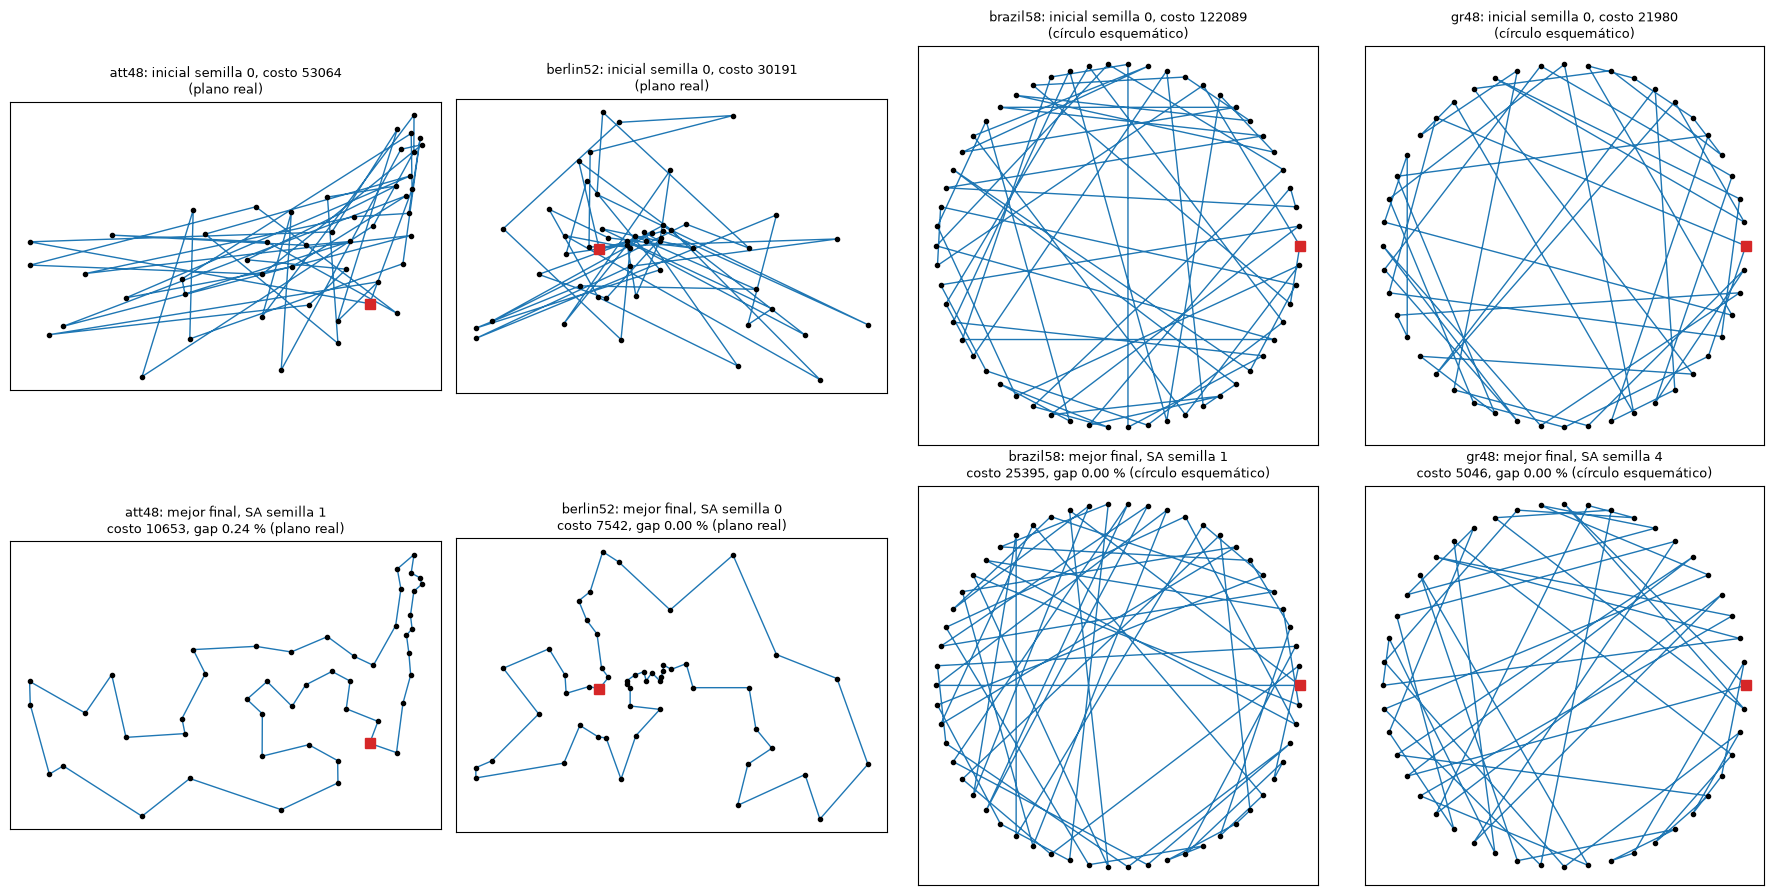

In [40]:
def layout(inst):
    if inst.coords is not None:
        return inst.coords
    angle = 2 * np.pi * np.arange(inst.n) / inst.n
    return np.column_stack([np.cos(angle), np.sin(angle)])


def draw_tour(ax, inst, tour, title):
    xy = layout(inst)
    closed = list(tour) + [tour[0]]
    ax.plot(xy[closed, 0], xy[closed, 1], "-", lw=1, color="tab:blue")
    ax.plot(xy[:, 0], xy[:, 1], "o", ms=3, color="black")
    ax.plot(*xy[tour[0]], "s", ms=7, color="tab:red")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for col, name in enumerate(MANDATORY):
    inst = INSTANCES[name]
    start = initial_tour(inst, 0)
    best = min((r for r in b_runs if r.instance == name and r.parameters["budget"] == 200_000), key=lambda r: r.cost)
    kind = "plano real" if inst.coords is not None else "círculo esquemático"
    draw_tour(axes[0, col], inst, start, f"{name}: inicial semilla 0, costo {tour_cost(inst.W, start)}\n({kind})")
    draw_tour(axes[1, col], inst, best.tour, f"{name}: mejor final, {best.algorithm} semilla {best.seed}\n"
                                             f"costo {best.cost}, gap {best.gap_percent:.2f} % ({kind})")
plt.tight_layout()
plt.show()

**Figura 2. Mejor costo acumulado frente a evaluaciones y frente a tiempo** (presupuesto principal). La línea es la mediana de las 10 semillas y la banda va del mínimo al máximo. El eje vertical es el gap, para poder poner las cuatro instancias en la misma escala. Cuando una ejecución para antes del final (HC de una ruta para en su óptimo local), su último valor se **conserva**: a partir de la primera parada la línea sigue **punteada**, para que no se lea como evaluaciones ejecutadas.

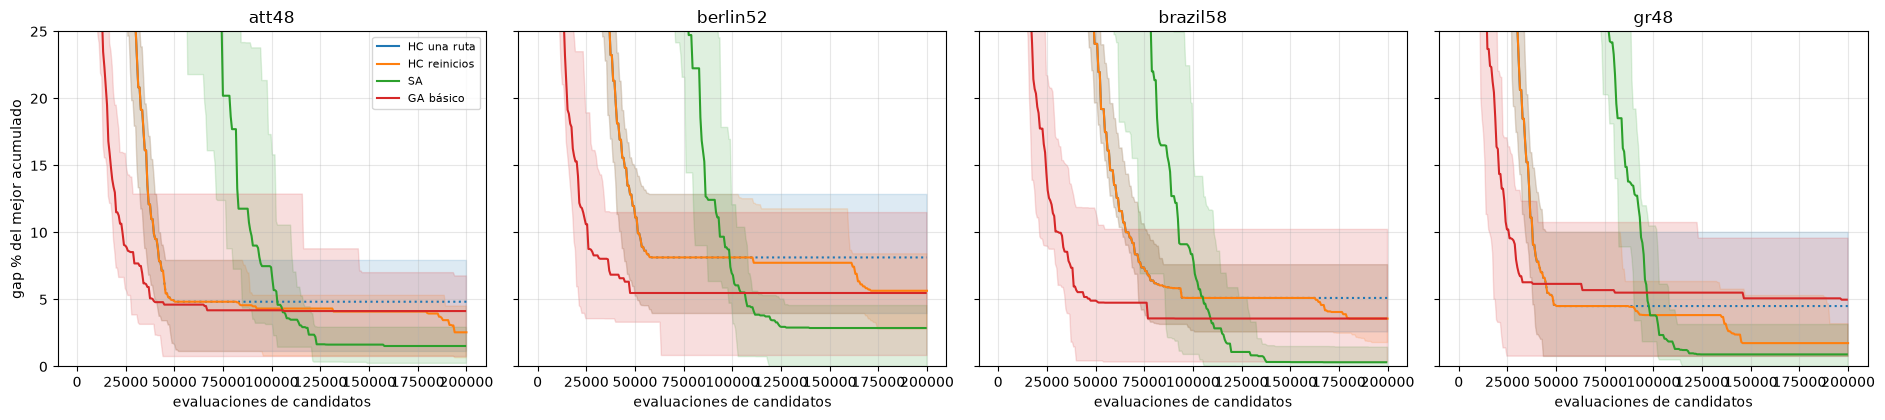

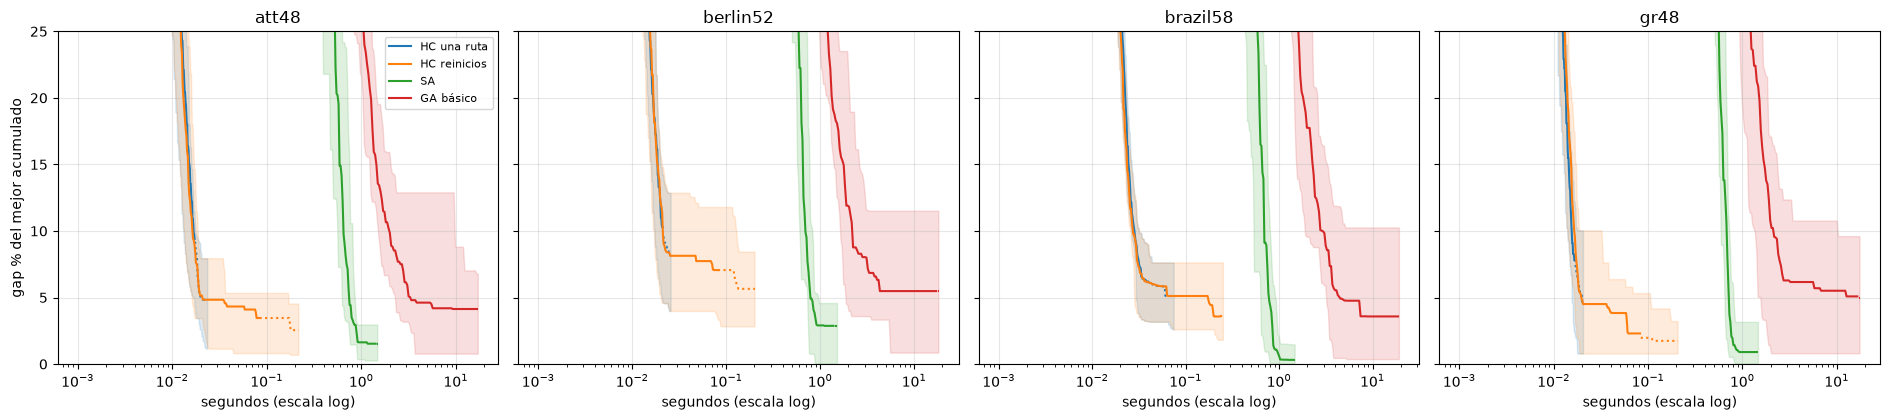

In [41]:
COLORS = dict(zip(LOCAL, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))


def curve(history, grid, axis):
    xs = np.array([h[axis] for h in history])
    ys = np.array([h[2] for h in history], dtype=float)
    return ys[np.maximum(np.searchsorted(xs, grid, side="right") - 1, 0)]


def plot_curves(axis, xlabel, grid_max, log_x):
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.3), sharey=True)
    for ax, name in zip(axes, MANDATORY):
        opt = INSTANCES[name].optimum
        for alg in LOCAL:
            rs = [runs_b[(name, alg, s, 200_000)] for s in SEEDS]
            top = grid_max(rs)
            grid = np.geomspace(1e-3 if axis else 1, top, 300) if log_x else np.linspace(1, top, 300)
            gaps = np.array([100 * (curve(r.history, grid, axis) - opt) / opt for r in rs])
            ends = [r.candidate_evaluations if axis == 0 else r.elapsed_seconds for r in rs]
            med = np.median(gaps, axis=0)
            live = grid <= min(ends)
            ax.fill_between(grid, gaps.min(axis=0), gaps.max(axis=0), color=COLORS[alg], alpha=0.15)
            ax.plot(grid[live], med[live], color=COLORS[alg], label=alg)
            ax.plot(grid[~live], med[~live], ":", color=COLORS[alg])
        ax.set_ylim(0, 25)
        ax.set_title(name)
        ax.set_xlabel(xlabel)
        if log_x:
            ax.set_xscale("log")
    axes[0].set_ylabel("gap % del mejor acumulado")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_curves(0, "evaluaciones de candidatos", lambda rs: 200_000, False)
plot_curves(1, "segundos (escala log)", lambda rs: max(r.elapsed_seconds for r in rs), True)

**Figura 3. Gap por algoritmo e instancia,** con cajas y cada semilla como un punto, en los dos presupuestos.

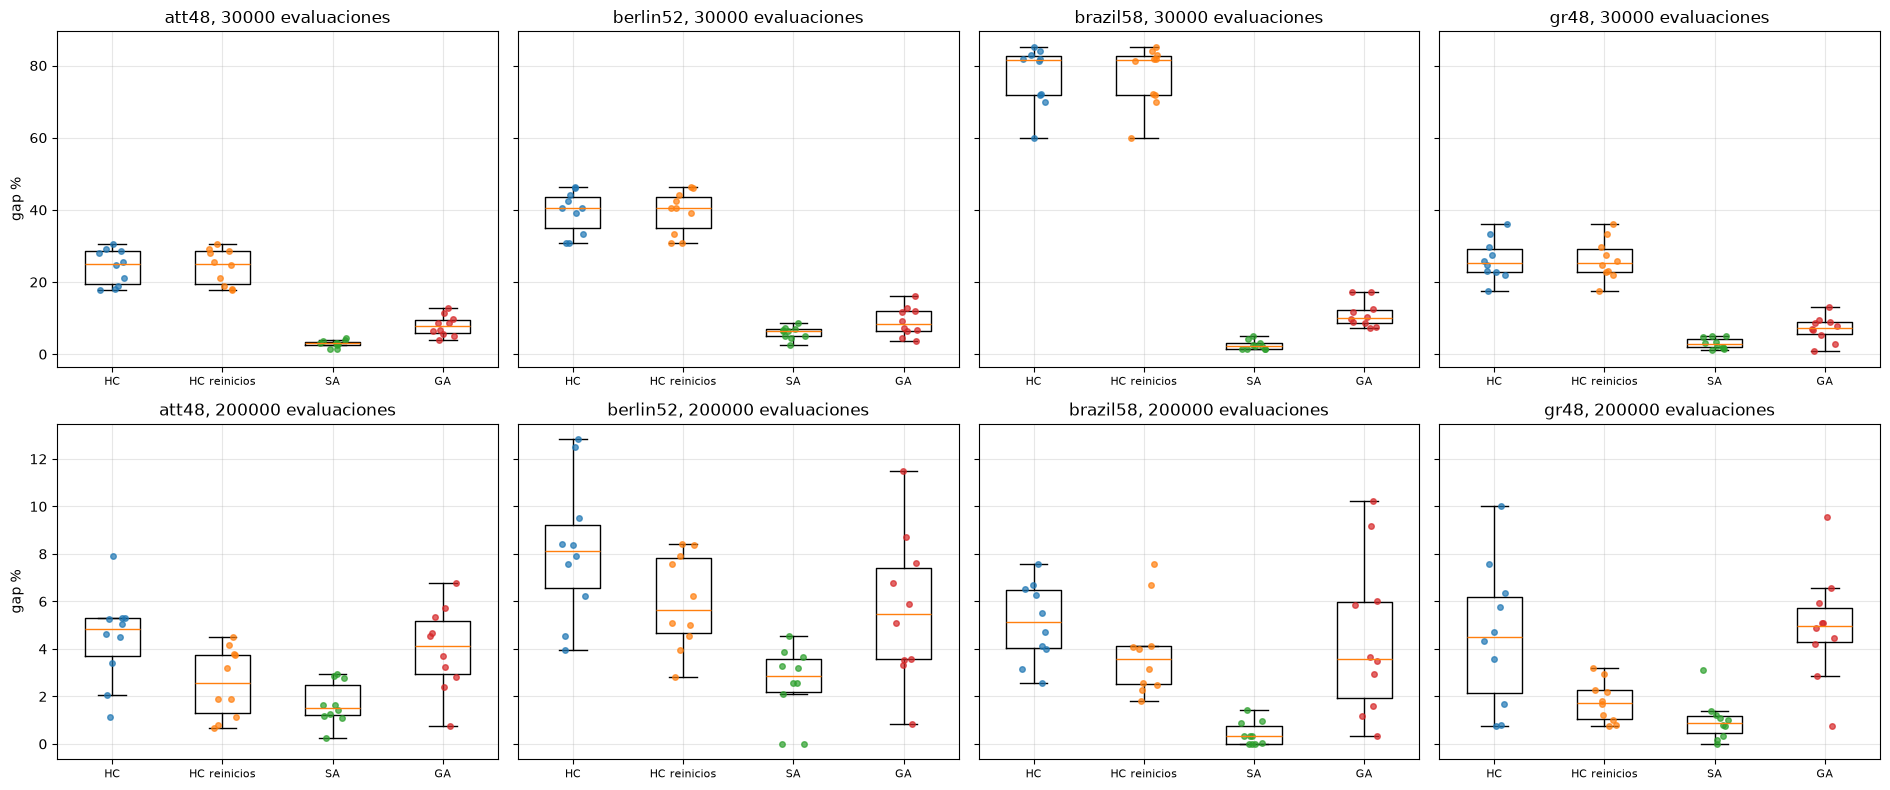

In [42]:
fig, axes = plt.subplots(2, 4, figsize=(19, 8), sharey="row")
jitter = np.random.default_rng(0)
for row, b in enumerate(BUDGETS):
    for ax, name in zip(axes[row], MANDATORY):
        data = [df_b[(df_b["instance"] == name) & (df_b["algorithm"] == alg) & (df_b["presupuesto"] == b)]["gap_percent"]
                for alg in LOCAL]
        ax.boxplot(data, widths=0.5, showfliers=False)
        for i, d in enumerate(data, start=1):
            ax.plot(i + jitter.uniform(-0.12, 0.12, len(d)), d, "o", ms=4, alpha=0.7, color=COLORS[LOCAL[i - 1]])
        ax.set_xticks(range(1, 5), ["HC", "HC reinicios", "SA", "GA"], fontsize=8)
        ax.set_title(f"{name}, {b} evaluaciones")
    axes[row, 0].set_ylabel("gap %")
plt.tight_layout()
plt.show()

**Figura 4. Tiempo y memoria de A\* y RBFS contra el tamaño de la subinstancia** (escala A, escala logarítmica). Una **x** marca una ejecución interrumpida por el presupuesto de exactos.

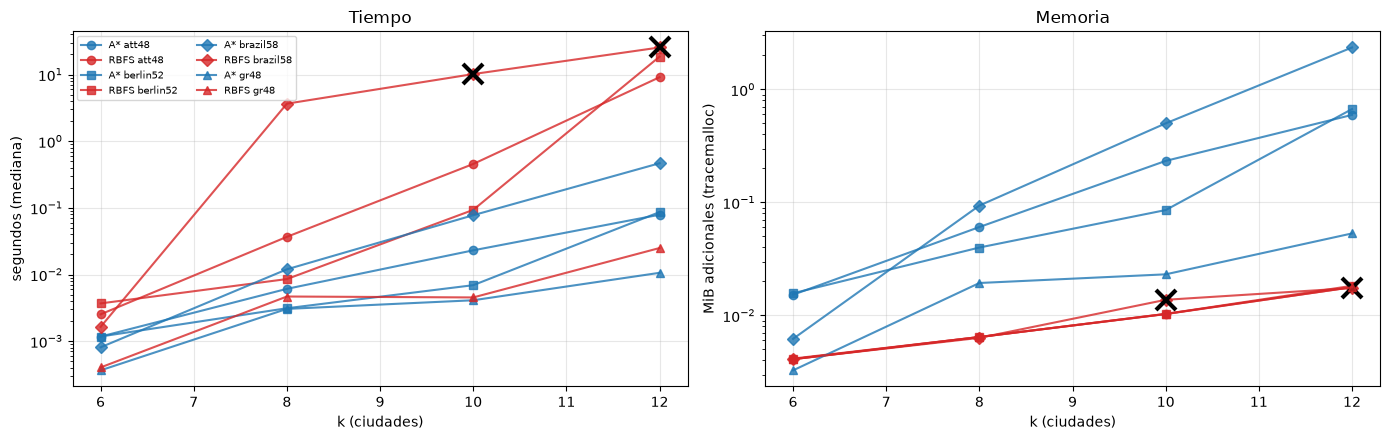

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, marker in zip(MANDATORY, "osD^"):
    d = scale_a[scale_a["instancia"] == name]
    for algo, color, col_s, col_m in (("A*", "tab:blue", "s A* (mediana)", "MiB A*"),
                                      ("RBFS", "tab:red", "s RBFS (mediana)", "MiB RBFS")):
        axes[0].plot(d["k"], d[col_s], marker=marker, color=color, alpha=0.8, label=f"{algo} {name}")
        axes[1].plot(d["k"], d[col_m].clip(lower=1e-3), marker=marker, color=color, alpha=0.8)
        if algo == "RBFS":
            cut = d[d["parada RBFS"] != "GOAL"]
            axes[0].plot(cut["k"], cut[col_s], "x", ms=14, mew=3, color="black")
            axes[1].plot(cut["k"], cut[col_m].clip(lower=1e-3), "x", ms=14, mew=3, color="black")
axes[0].set(yscale="log", xlabel="k (ciudades)", ylabel="segundos (mediana)", title="Tiempo")
axes[1].set(yscale="log", xlabel="k (ciudades)", ylabel="MiB adicionales (tracemalloc)", title="Memoria")
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

**Figura 5. SA en berlin52, semilla 0, presupuesto principal:** temperatura, costo actual y mejor costo, y tasa de aceptación de empeoramientos. La **ventana de aceptación es un nivel de temperatura**: la tasa es aceptados con $\Delta > 0$ sobre propuestos con $\Delta > 0$ dentro de ese nivel.

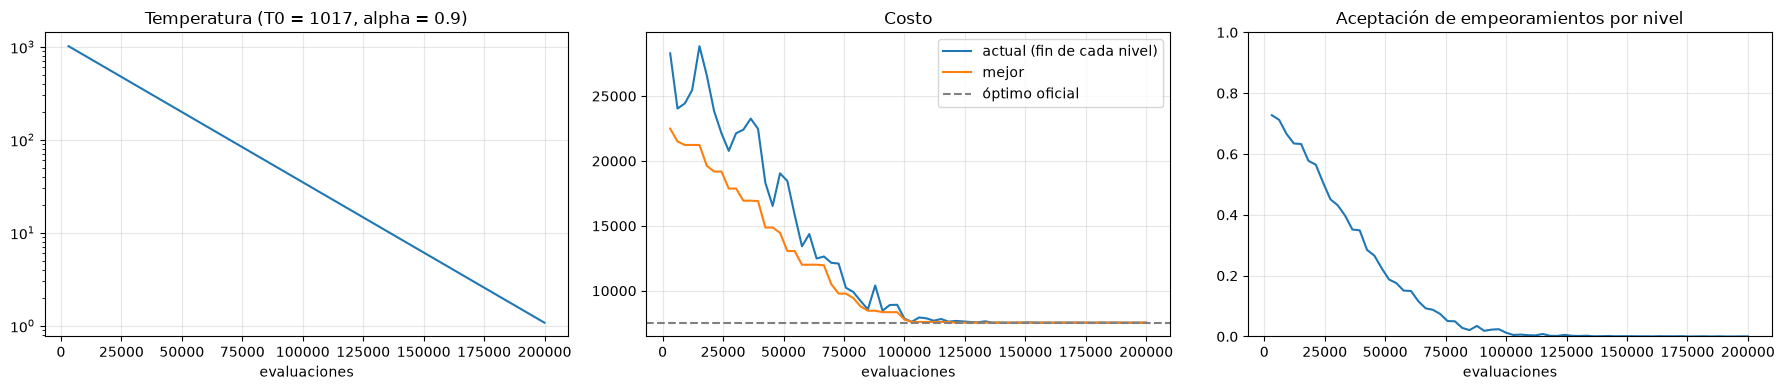

In [44]:
sa_demo = runs_b[("berlin52", "SA", 0, 200_000)]
lv = pd.DataFrame(sa_demo.extra["levels"])
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(lv["evals"], lv["T"])
axes[0].set(yscale="log", title=f"Temperatura (T0 = {sa_demo.extra['T0']:.0f}, alpha = {FROZEN['SA']['alpha']})",
            xlabel="evaluaciones")
axes[1].plot(lv["evals"], lv["current"], label="actual (fin de cada nivel)")
axes[1].plot(lv["evals"], lv["best"], label="mejor")
axes[1].axhline(INSTANCES["berlin52"].optimum, ls="--", color="gray", label="óptimo oficial")
axes[1].set(title="Costo", xlabel="evaluaciones")
axes[1].legend()
axes[2].plot(lv["evals"], lv["worse_acceptance"])
axes[2].set(title="Aceptación de empeoramientos por nivel", xlabel="evaluaciones", ylim=(0, 1))
plt.tight_layout()
plt.show()

**Figura 6. GA en berlin52, semilla 0, presupuesto principal:** mejor costo y costo mediano de la población, y las dos medidas de diversidad de F.2 por generación.

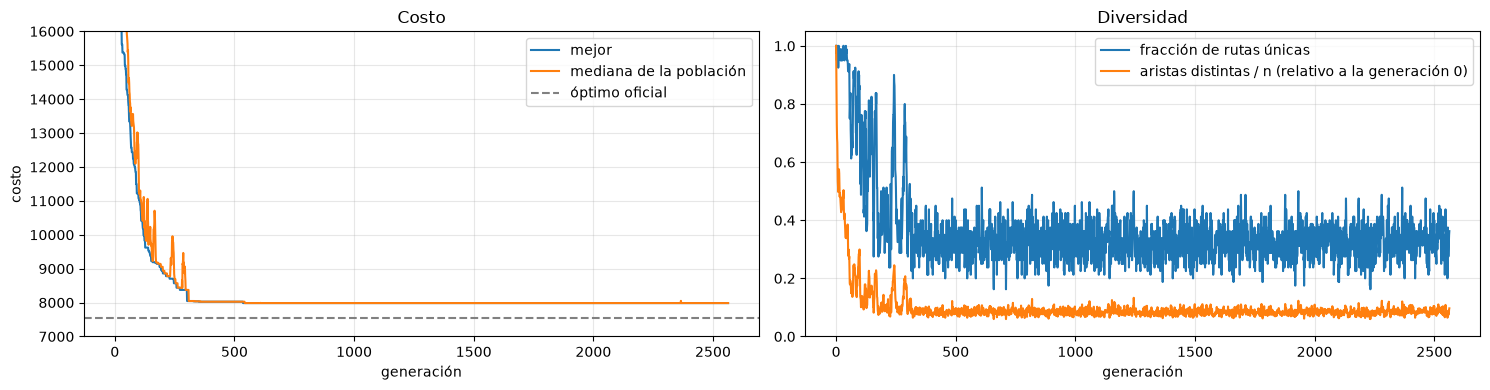

2563 generaciones; aristas distintas / n: 24.4 al inicio, 2.37 al final


In [45]:
ga_demo = runs_b[("berlin52", "GA básico", 0, 200_000)]
gl = pd.DataFrame(ga_demo.extra["gen_log"])
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(gl["generation"], gl["best"], label="mejor")
axes[0].plot(gl["generation"], gl["median"], label="mediana de la población")
axes[0].axhline(INSTANCES["berlin52"].optimum, ls="--", color="gray", label="óptimo oficial")
axes[0].set(xlabel="generación", ylabel="costo", ylim=(7000, 16000), title="Costo")
axes[0].legend()
axes[1].plot(gl["generation"], gl["unique"], label="fracción de rutas únicas")
axes[1].plot(gl["generation"], gl["edge_diversity"] / gl["edge_diversity"].iloc[0],
             label="aristas distintas / n (relativo a la generación 0)")
axes[1].set(xlabel="generación", title="Diversidad", ylim=(0, 1.05))
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"{ga_demo.extra['generations']} generaciones; aristas distintas / n: {gl['edge_diversity'].iloc[0]:.1f} al inicio, "
      f"{gl['edge_diversity'].iloc[-1]:.2f} al final")

**Lo que encontramos (G.6):**

- **Figura 1.** Las mejores rutas finales de att48 y berlin52 no tienen cruces y se ven como un recorrido "razonable" por el mapa; las cuatro mejores son de SA, y en berlin52, brazil58 y gr48 tienen exactamente el costo óptimo. En brazil58 y gr48 el dibujo circular se ve igual de enredado al inicio que al final: sin coordenadas, el dibujo no dice nada de la calidad, y por eso ahí miramos solo el costo.
- **Figura 2, por evaluaciones.** Cada método tiene su propia forma. El GA es el que baja más rápido al principio: hasta unas 40 000 evaluaciones va primero. HC baja casi igual de rápido y luego se detiene en su óptimo local (la línea pasa a punteada desde que para la primera semilla). SA pasa sus primeras 80 000 evaluaciones "caliente", casi sin mejorar; entre 80 000 y 120 000 baja de golpe y termina por debajo de todos. Esto explica por qué el presupuesto cambia el orden: con poco presupuesto el GA gana a SA, y con 200 000 pasa lo contrario.
- **Figura 2, por tiempo.** El orden cambia otra vez. HC y HC con reinicios terminan en menos de 0.3 s; en ese tiempo SA ni siquiera empezó a enfriarse. SA termina hacia 1.5 s y el GA necesita varios segundos para llegar a su nivel final. Si se cortara todo a los 0.2 s, el mejor sería HC con reinicios (pregunta 9).
- **Figura 3.** Con 30 000 evaluaciones las cajas de HC y HC con reinicios son idénticas (nunca reinician) y están muy arriba. Con 200 000 la caja de SA es la más baja y la más estrecha en las cuatro instancias; en gr48 la de HC con reinicios queda cerca. Las cajas más anchas son las de HC de una ruta y del GA: en berlin52 y brazil58 las peores semillas del GA pasan del 10 %.
- **Figura 4.** El tiempo de RBFS crece mucho más rápido que el de A\*: en brazil58 ya en $k=8$ tarda más de 3 s, y las cruces marcan los cortes en $k=10$ y $k=12$. La memoria es al revés: la de RBFS es una recta baja y casi igual en las cuatro instancias, y la de A\* sube con $k$ y depende mucho de la instancia.
- **Figura 5.** La temperatura baja en línea recta en escala logarítmica, como corresponde a $T \leftarrow \alpha T$. La aceptación de empeoramientos empieza cerca de 0.73 (calibrada para 0.8) y llega a casi 0 hacia las 100 000 evaluaciones. Mientras está caliente, la ruta actual sube y baja muy por encima de la mejor; cuando la aceptación cae, las dos se juntan y desde ahí SA es un descenso que termina en el óptimo, 7542.
- **Figura 6.** El GA llega a su mejor costo hacia la generación 550 y en las casi 2000 generaciones siguientes no mejora nada: más de las tres cuartas partes del presupuesto se gastan sin efecto. Desde la generación 300 la mediana de la población es igual al mejor, la fracción de rutas únicas oscila alrededor de 0.3 y las aristas distintas quedan cerca del 10 % de las iniciales. Es la convergencia prematura de la pregunta 8: la población es casi una sola ruta con pequeñas variantes.

### G.7 Cómo medimos la memoria y cuánto cuesta medirla (secciones 4 y 14.1)

- **Sobrecosto de `tracemalloc`.** Corremos lo mismo con la medición encendida y apagada (con apagada, `Meter` solo mide el tiempo), tres veces cada una, y comparamos la mediana. Esta celda corre sola, sin otros procesos en paralelo.
- **Memoria del proceso contra memoria del solver.** `tracemalloc` solo ve las asignaciones de Python del solver. El proceso completo (intérprete, numpy, pandas, matplotlib, los datos y los resultados guardados) ocupa mucho más. Lo leemos con `resource.getrusage` (máximo de memoria residente, RSS), para este proceso y para el mayor de los procesos de trabajo.

In [46]:
class PlainMeter(Meter):
    """Same budget checks as Meter, without tracemalloc (memory reported as NaN)."""

    def __init__(self, seconds=INF, expansions=None, evaluations=None, memory_mib=None):
        self.seconds, self.expansions, self.evaluations, self.memory_mib = seconds, expansions, evaluations, memory_mib
        self._own_tracing, self.t0 = False, time.perf_counter()

    def peak_mib(self):
        return float("nan")


def timed(fn, traced):
    global Meter
    saved = Meter
    Meter = saved if traced else PlainMeter
    try:
        return statistics.median(fn().elapsed_seconds for _ in range(3))
    finally:
        Meter = saved


berlin = INSTANCES["berlin52"]
probes = {"HC una ruta (hasta óptimo local), berlin52": lambda: hill_climbing(berlin, initial_tour(berlin, 0), BIG,
                                                                               random.Random(0)),
          "SA 200 000 evaluaciones, berlin52": lambda: simulated_annealing(berlin, initial_tour(berlin, 0), BUDGET_MAIN,
                                                                           random.Random(0), **FROZEN["SA"]),
          "GA 30 000 evaluaciones, berlin52": lambda: genetic_algorithm(berlin, BUDGET_TEACHER, random.Random(0),
                                                                        **FROZEN["GA básico"]),
          "A* k=12, berlin52": lambda: astar(berlin.subproblem(12)),
          "RBFS k=10, att48": lambda: rbfs(INSTANCES["att48"].subproblem(10))}
overhead = pd.DataFrame([{"ejecución": label, "s con tracemalloc": timed(fn, True), "s sin tracemalloc": timed(fn, False)}
                         for label, fn in probes.items()])
overhead["factor"] = overhead["s con tracemalloc"] / overhead["s sin tracemalloc"]
display(overhead.round(3))

solver_peak = max([r.peak_memory_mib for r in b_runs + diag] + scale_a["MiB A*"].tolist())
display(pd.Series({
    "RSS máximo de este proceso (MiB)": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024,
    "RSS máximo del mayor proceso de trabajo (MiB)": resource.getrusage(resource.RUSAGE_CHILDREN).ru_maxrss / 1024,
    "mayor memoria adicional de un solver, tracemalloc (MiB)": solver_peak,
}, name="valor").round(1).to_frame())

,ejecución,s con tracemalloc,s sin tracemalloc,factor
0,"HC una ruta (hasta óptimo local), berlin52",0.016,0.017,0.929
1,"SA 200 000 evaluaciones, berlin52",0.941,0.106,8.914
2,"GA 30 000 evaluaciones, berlin52",1.519,0.380,3.997
3,"A* k=12, berlin52",0.057,0.014,4.118
4,"RBFS k=10, att48",0.319,0.069,4.629


,valor
RSS máximo de este proceso (MiB),491.7
RSS máximo del mayor proceso de trabajo (MiB),446.5
"mayor memoria adicional de un solver, tracemalloc (MiB)",24.7


**Lo que encontramos (G.7):**

- **Medir la memoria cuesta mucho tiempo y no afecta a todos por igual.** Con `tracemalloc` encendido, HC casi no cambia (factor cercano a 1), pero SA tarda unas 9 veces más, y RBFS, GA y A\* unas 4 veces más. `tracemalloc` cobra por cada objeto que se crea, y SA crea una lista nueva cada vez que acepta un movimiento, mientras que HC casi solo calcula deltas. Por eso **los tiempos absolutos de las tablas están inflados**, y la diferencia de tiempo entre SA y HC es en parte un efecto de la medición. Para comparar tiempos entre familias hay que tenerlo presente; los costos y las evaluaciones no cambian.
- **Memoria del proceso contra memoria del solver.** El proceso de Jupyter llega a unos 490 MiB de RSS, y el mayor proceso de trabajo a unos 450 MiB (heredan el intérprete y las bibliotecas). El solver que más memoria adicional usó, A\* en un diagnóstico, apenas pasa de 24 MiB. Casi toda la memoria del proceso es el entorno, no el algoritmo. Por eso reportamos la memoria adicional del solver y decimos que solo cubre las asignaciones de Python.

### G.8 Animación didáctica: HC mejorando una ruta de berlin52

Corremos HC de una ruta en berlin52 con la semilla 0 y guardamos la ruta en cada mejora (`snapshots`). Es una corrida aparte, que no se usa para medir. Los cuadros se dibujan **después** de la corrida. Cada cuadro muestra el algoritmo, el costo y las evaluaciones acumuladas. El GIF queda en `figuras/` y se ve aquí abajo.

47 cuadros -> figuras/hc_berlin52.gif


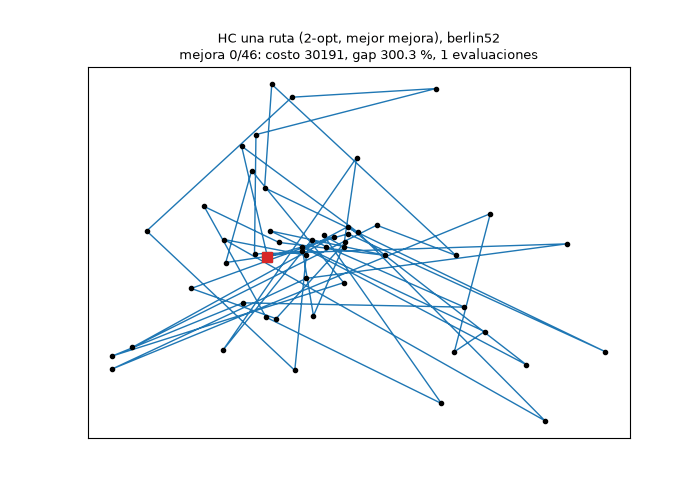

In [47]:
snaps = []
anim_run = hill_climbing(berlin, initial_tour(berlin, 0), BIG, random.Random(0), snapshots=snaps)
assert anim_run.cost == runs_b[("berlin52", "HC una ruta", 0, 200_000)].cost
frames = [(1, initial_tour(berlin, 0), anim_run.extra["initial_cost"])] + snaps
fig, ax = plt.subplots(figsize=(7, 5))


def draw_frame(i):
    ax.clear()
    evals, tour, cost = frames[i]
    draw_tour(ax, berlin, tour, f"HC una ruta (2-opt, mejor mejora), berlin52\n"
                                f"mejora {i}/{len(frames) - 1}: costo {cost}, gap {gap_percent(cost, 7542):.1f} %, "
                                f"{evals} evaluaciones")


gif_path = FIG_DIR / "hc_berlin52.gif"
animation.FuncAnimation(fig, draw_frame, frames=len(frames)).save(gif_path, writer=animation.PillowWriter(fps=4))
plt.close(fig)
print(f"{len(frames)} cuadros -> {gif_path}")
display(Image(filename=str(gif_path)))

**Lo que encontramos (G.8):** la animación tiene 47 cuadros: la ruta inicial y las 46 mejoras de HC hasta su óptimo local. Las primeras mejoras quitan cruces largos que atraviesan todo el mapa y bajan mucho el costo: con solo 3 mejoras pasa de 30 191 a 24 865. Las últimas reacomodan tramos cortos y ganan poco: las 16 últimas bajan de 9628 a 8113. Al final la ruta no tiene cruces, pero su gap sigue siendo de 7.6 % (es la misma corrida de HC de la semilla 0 de G.4): sin cruces no quiere decir óptima (E.2).

### H. Discusión y conclusiones

*Responda las preguntas y formule conclusiones respaldadas por sus resultados.*

### H.1 Resumen para la discusión

Antes de responder juntamos en una tabla lo que más usan las preguntas 7, 9 y 10: gap mediano, dispersión y tiempo mediano de cada método local en las cuatro instancias, con el presupuesto principal (200 000 evaluaciones). Sale de `df_b` (G.4), no de números copiados a mano. Las columnas de orden dicen qué puesto ocupa cada método en esa instancia por gap mediano y por tiempo mediano.

In [48]:
main = df_b[df_b["presupuesto"] == 200_000]
discussion = (main.groupby(["instance", "algorithm"], sort=False)
              .agg(gap_mediano=("gap_percent", "median"), gap_desv=("gap_percent", "std"),
                   gap_max=("gap_percent", "max"), s_mediano=("elapsed_seconds", "median"),
                   llega_al_optimo=("gap_percent", lambda g: int((g == 0).sum())))
              .round(2))
discussion["orden por gap"] = discussion.groupby(level=0)["gap_mediano"].rank(method="min").astype(int)
discussion["orden por tiempo"] = discussion.groupby(level=0)["s_mediano"].rank(method="min").astype(int)
display(discussion)
print("puesto medio por gap:", discussion.groupby(level=1, sort=False)["orden por gap"].mean().to_dict())
print("puesto medio por tiempo:", discussion.groupby(level=1, sort=False)["orden por tiempo"].mean().to_dict())

gap_mediano  gap_desv  gap_max  s_mediano  llega_al_optimo  orden por gap  orden por tiempo
instance algorithm                                                                                                
att48    HC una ruta          4.83      1.90     7.91       0.02                0              4                 1
         HC reinicios         2.55      1.47     4.51       0.14                0              2                 2
         SA                   1.53      0.88     2.93       1.44                0              1                 3
         GA básico            4.14      1.78     6.76      16.96                0              3                 4
berlin52 HC una ruta          8.13      2.94    12.83       0.02                0              4                 1
         HC reinicios         5.65      2.00     8.41       0.11                0              3                 2
         SA                   2.87      1.53     4.55       1.45                2              1                 3
         GA básico            5.48      3.10    11.48      17.84                0              2                 4
brazil58 HC una ruta          5.11      1.66     7.60       0.05                0              4                 1
         HC reinicios         3.57      1.91     7.60       0.24                0              2                 2
         SA                   0.32      0.50     1.44       1.45                3              1                 3
         GA básico            3.58      3.33    10.23      19.23                0              3                 4
gr48     HC una ruta          4.51      3.01    10.01       0.02                0              3                 1
         HC reinicios         1.74      0.86     3.19       0.13                0              2                 2
         SA                   0.90      0.88     3.13       1.45                1              1                 3
         GA básico            4.98      2.30     9.57      16.92                0              4                 4

puesto medio por gap: {'HC una ruta': 3.75, 'HC reinicios': 2.25, 'SA': 1.0, 'GA básico': 3.0}
puesto medio por tiempo: {'HC una ruta': 1.0, 'HC reinicios': 2.0, 'SA': 3.0, 'GA básico': 4.0}


### H.2 Las 12 preguntas de la sección 16

Cada respuesta dice de dónde sale: el apartado (por ejemplo, G.4) y la tabla, figura, prueba o traza.

**1. ¿Por qué A\* y RBFS trabajan con rutas parciales y HC, SA y GA con rutas completas?** Porque hacen preguntas distintas. A\* y RBFS **construyen** la ruta ciudad por ciudad y necesitan saber, antes de terminarla, si vale la pena seguir: eso lo da $f = g + h$, donde $g$ es lo ya recorrido y $h$ una cota de lo que falta (C.2, C.3). Sobre una ruta completa no queda nada por acotar. HC, SA y GA **mejoran** rutas que ya existen: necesitan un costo completo para comparar, y sus operadores (2-opt, OX, inversión) solo tienen sentido sobre una permutación entera (E.1, F.1). Por eso los exactos pueden certificar el óptimo cuando terminan (D.4) y los locales siempre tienen una ruta para devolver, aunque sea mala (G.4, 30 000 evaluaciones).

**2. ¿Por qué el MST da una cota y no una solución? ¿Qué pierde la relajación?** Lo que falta de una ruta parcial es un camino que pasa por todas las pendientes y vuelve. Si a ese camino le quitamos las dos aristas de conexión, queda un árbol que une las pendientes, y ningún árbol es más barato que el MST. Por eso la suma no se pasa del costo real (C.4). Pero el MST no exige **grado 2** ni que sea un solo camino: puede ramificarse, y las dos aristas de conexión pueden salir hacia la misma ciudad. Eso es lo que pierde. En C.8 lo medimos sobre los 13 700 prefijos de dos subproblemas de 8 ciudades: la cota nunca falla, pero cerca de la raíz deja sin contar entre una cuarta y una tercera parte de lo que falta (mínimo $h$/residual 0.76 en berlin52 y 0.64 en gr48). Ese hueco hace crecer la búsqueda: con 48 ciudades ni A\* ni RBFS terminan en 30 s (G.4).

**3. ¿Qué sucede si A\* cierra estados usando solamente la última ciudad?** Dos rutas parciales que terminan en la misma ciudad se tratan como el mismo estado, aunque les falten ciudades distintas. En D.5 A\* no devuelve **ninguna** ruta en los 5 casos (`EXHAUSTED`): el primer prefijo que llega a cada ciudad es el directo desde el origen y tiene el menor $g$, así que todo prefijo más largo se descarta. Si además se usa la profundidad (la regla de TSP Solve, C.1), aparecen rutas, pero no óptimas: 5879 contra 5715 en att48 con $k=6$. En C.7 está el par concreto: el prefijo descartado era el único que llevaba al óptimo.

**4. ¿Por qué devolver el primer nodo con pendientes vacíos, sin cobrar el retorno, puede fallar?** Porque ese nodo es el mejor **camino** abierto, no el mejor ciclo. En D.5, en att48 con $k=6$, el camino cuesta 4151, pero al cerrarlo el ciclo cuesta 6163, un 7.8 % por encima del óptimo 5715. El camino más barato puede terminar lejos del origen y el regreso se paga después. Nuestro A\* evita el error con el estado "cerrado": la meta se reconoce al sacar de la frontera un nodo que ya pagó el regreso (D.1).

**5. ¿En qué casos RBFS redujo memoria y aumentó recomputación?** En todos los subproblemas de la escala A (G.3, tabla y figura 4). En $k = 12$, RBFS nunca tiene más de 68 registros vivos ni pasa de 0.02 MiB, mientras A\* guarda entre 1296 y 4204 nodos en la frontera y usa hasta 2.35 MiB: entre 3 y 130 veces menos memoria. El precio: en berlin52 con $k=12$, de 80 651 expansiones, 80 214 son regeneraciones (99.5 %), y tarda unos 18 s contra 0.09 s de A\*. En brazil58 con $k = 10$ y $k = 12$, y en burma14 y gr17 completas (D.8), RBFS se corta por presupuesto, mientras A\* termina. La traza del caso de 6 ciudades de berlin52 (D.3) muestra el mecanismo en pequeño: la rama 23-24 falla con límite 1789, guarda el valor respaldado 1878, se olvida, y después **reaparece** y se expande otra vez.

**6. ¿Qué diferencias hay entre att48 y gr48, las dos con 48 ciudades?** No es el mismo problema con otro nombre.
- **Datos:** att48 tiene coordenadas y la distancia pseudo-euclidiana ATT; gr48 es una matriz explícita, sin coordenadas (B, fichas). En gr48 no hay "cruces" ni plano: su figura 1 es un círculo esquemático (E.2, G.6).
- **Exactos:** gr48 es mucho más fácil. En $k = 12$, A\* hace 38 expansiones en gr48 y 376 en att48; RBFS, 79 contra 32 375 (G.3). En los primeros 12 nodos de gr48 la cota MST se ajusta mejor.
- **Locales:** las dos tienen gaps de pocos puntos a 200 000 evaluaciones (H.1). gr48 es donde SA y HC con reinicios quedan más cerca: SA pierde en 3 de 10 semillas y la diferencia mediana es solo de 38 unidades, un 0.75 % (G.5). SA llega al óptimo de gr48 en 1 semilla y al de att48 en ninguna (G.4).
- **Escala del costo:** el óptimo de att48 es 10 628 y el de gr48 5046 (B.2), así que una misma diferencia absoluta pesa distinto. Por eso comparamos con el gap y no con el costo.

**7. ¿Cuánto aportaron los reinicios frente a aceptar empeoramientos?** Mirando la distribución de las 10 semillas (H.1, figura 3, G.5):
- Con 30 000 evaluaciones, los reinicios no aportan **nada**: HC nunca llega a su primer óptimo local, así que HC con reinicios da exactamente lo mismo que HC de una ruta (G.4).
- Con 200 000, los reinicios bajan el gap mediano de 4.5-8.1 % a 1.7-5.7 %. Aceptar empeoramientos (SA) lo baja más: 0.3-2.9 %. SA le gana a HC con reinicios en 35 de 40 pares con la misma ruta inicial (G.5), y es el único que llega al óptimo oficial (6 de 40 corridas).
- La dispersión está en la figura 3 y en las columnas `gap_desv` y `gap_max` de H.1: la comparación es de medianas y peores casos sobre las 10 semillas, no de la mejor corrida.

**8. ¿Qué signos de convergencia prematura hubo en el GA? ¿Cómo se relacionan con la diversidad?** En la corrida de berlin52 con el presupuesto principal (figura 6), las aristas distintas por ciudad bajan de 24.4 al inicio a 2.4 al final: casi toda la población usa las mismas aristas. Desde la generación 300 la mediana de la población es igual al mejor, y desde la 550 el mejor no vuelve a bajar en las casi 2000 generaciones que quedan. La fracción de rutas únicas sigue alta más tiempo, pero engaña: son variantes de la misma ruta que difieren en unas pocas inversiones. Con poca diversidad de aristas, el OX ya no tiene nada nuevo que combinar, y solo la mutación trae aristas nuevas. Por eso en la calibración gana la mutación alta, $p_m = 0.3$ (G.2). En las 10 semillas el GA queda cerca de HC de una ruta (gap mediano 3.6-5.5 %, H.1), lejos de SA.

**9. ¿Cambió el ranking al comparar tiempo en lugar de evaluaciones?** Sí. Por **calidad con las mismas evaluaciones**, el orden es SA, HC con reinicios, GA y al final HC de una ruta (H.1, puesto medio por gap: 1.0, 2.25, 3.0 y 3.75), aunque el GA y HC de una ruta cambian de lugar según la instancia. Por **tiempo**, HC de una ruta y HC con reinicios terminan en menos de 0.3 s, SA tarda unas 10 veces más que HC con reinicios y el GA es por mucho el más lento, 17-19 s (G.4, G.5, H.1, puesto medio por tiempo). En la figura 2 en segundos se ve que el orden de calidad **depende del corte**: a los 0.2 s el mejor es HC con reinicios, porque SA todavía no empezó a enfriarse; desde 1.5 s el mejor es SA. Dos matices: `tracemalloc` hace a SA unas 9 veces más lento y a HC casi nada (G.7), así que parte de esa diferencia es la medición; y las corridas compartían la máquina (G.1). No medimos qué pasa si HC con reinicios recibe los mismos **segundos** que SA (pregunta 12).

**10. Dos segundos para devolver una ruta, ¿qué elegimos? ¿Y para demostrar optimalidad?**
- **Dos segundos:** SA con 200 000 evaluaciones. Con medición y 8 corridas en paralelo tardó unos 1.5 s (G.4), y sin `tracemalloc` es unas 9 veces más rápido (G.7), así que cabe con margen y es el que mejor gap da (H.1). Como en otra ejecución de prueba SA tardó hasta el doble, sin margen elegiríamos HC con reinicios: termina en menos de 0.3 s con gap mediano 1.7-5.7 %. El GA no sirve aquí. Ojo: no corrimos un presupuesto de 2 s; lo deducimos de los tiempos medidos.
- **Demostrar optimalidad:** A\* con MST, que certificó todos los subproblemas de hasta 12 ciudades y burma14 y gr17 completas (G.3, D.8). En las instancias de 48 a 58 ciudades no terminó en 30 s (G.4), así que con nuestros recursos **no** podemos demostrar el óptimo ahí. Los locales nunca demuestran nada: aunque SA dé el óptimo oficial, solo lo sabemos porque TSPLIB lo publica. RBFS no es la opción: usa menos memoria pero se corta antes que A\* (D.8).

**11. ¿Qué afirmaciones de la página de referencia requieren matices?** Hay que separar lo que es del algoritmo de lo que es de su código (C.1):
- **"A\* da el óptimo".** Es verdad para A\* con una heurística admisible y el estado correcto. El código de la página usa como estado solo la ciudad (y la profundidad), y con esa regla A\* deja de ser exacto: lo reproducimos en D.5. Que la página encuentre el óptimo solo desde 8 de 48 orígenes es un síntoma de su implementación, no de A\*.
- **"RBFS usa memoria lineal".** Es una propiedad del algoritmo y la vimos: los registros vivos crecen como $k^2/2$ (G.3). Pero no implica menos tiempo: con 12 ciudades ya regenera el 99.5 % de sus expansiones (G.3). Además, en el código de la página la $f$ resta la profundidad y el `max` con la $f$ del padre se aplica a una copia, así que su RBFS no es el de la sección 8.
- **"Hill Climbing con 2-opt".** El código hace swap, no 2-opt (C.1). Son vecindades distintas: desde 6 ciudades hay swaps que cambian 4 aristas y no equivalen a ningún 2-opt (E.1).
- **Tiempos publicados.** Son de otro lenguaje, otra máquina y otro código. No sirven como meta (C.1), y nuestros propios tiempos dependen de la medición (G.7).

**12. ¿Qué conclusión no podemos sostener?**
- **"El GA es peor que SA" en general.** Probamos un GA básico (OX, inversión, torneo), calibrado en dos instancias con 5 semillas. Otro operador o una búsqueda local dentro del GA podrían cambiarlo.
- **Diferencias pequeñas entre configuraciones.** En la calibración de SA, las seis configuraciones quedan entre 1.2 % y 1.8 % (G.2); con 5 semillas y 2 instancias eso no es concluyente.
- **Significancia estadística.** Con 10 semillas contamos pares mejor/igual/peor (G.5), pero no hicimos una prueba formal. "SA gana 35 de 40" es una tendencia clara, no una probabilidad.
- **Tiempos absolutos.** Están inflados por `tracemalloc` y por correr 8 procesos a la vez (G.1, G.7). Sirven para ordenar de forma gruesa, no para afirmar "SA tarda 3 s".
- **Comportamiento de los exactos en las instancias completas.** Tenemos un solo ensayo de 30 s por instancia y algoritmo (G.4). No sabemos cuánto tardarían en terminar.
- **Instancias más grandes.** Todas tienen entre 48 y 58 ciudades. No podemos extrapolar el orden de los métodos a 500 ciudades.
- **Primera mejora contra mejor mejora en las instancias completas.** Solo lo medimos con 20 ciudades (E.3).

### H.3 Conclusiones

1. **Un A\* bien formulado es exacto, y uno mal formulado no.** El estado tiene que ser (ciudad actual, pendientes, cerrado), y la meta se reconoce después de cobrar el regreso. Con esas reglas, A\* certificó los 16 subproblemas y dos instancias completas pequeñas (D.4, G.3, D.8). Con la regla de la última ciudad, o sin cobrar el regreso, da respuestas incorrectas (D.5).
2. **La cota MST es correcta pero floja cerca de la raíz** (C.8), y eso limita los exactos a unas 12-17 ciudades con nuestro presupuesto (G.3, G.4, D.8).
3. **RBFS cambia memoria por tiempo:** usa hasta 130 veces menos memoria que A\*, pero regenera casi todo lo que expande y se corta donde A\* termina (G.3, D.8).
4. **Entre los locales, aceptar empeoramientos es lo que más aporta.** Con el mismo presupuesto y la misma ruta inicial, SA tiene el mejor gap mediano en las cuatro instancias y es el único que llega al óptimo oficial (G.4, G.5, figura 3). Los reinicios ayudan a HC, pero menos.
5. **El presupuesto decide la comparación.** Con las 30 000 evaluaciones del enunciado, HC no alcanza a terminar su primer descenso y los reinicios no se usan (G.4). Medir con un presupuesto que no deja terminar a un método mide el corte, no el método.
6. **El GA básico pierde diversidad de aristas muy rápido** (F, figura 6) y queda al nivel de HC de una ruta, con mucho más tiempo (H.1).
7. **El tiempo y la memoria hay que leerlos con su instrumento.** `tracemalloc` cambia los tiempos de forma distinta para cada algoritmo (G.7), y la memoria del proceso es casi toda del entorno, no del solver.

### H.4 Referencias

Consulta de fuentes: 17 de octubre de 2026.

1. Hamdi Altaheri. [TSP Solve](https://sites.google.com/view/tsp-solve/homepage), páginas de [A\*](https://sites.google.com/view/tsp-solve/tsp-a-algorithm), [Hill Climbing](https://sites.google.com/view/tsp-solve/tsp-hill-climbing-algorithm) y [RBFS](https://sites.google.com/view/tsp-solve/tsp-rbfs-algorithm). Objeto de la lectura crítica de C.1; no usamos sus resultados como nuestros.
2. Gerhard Reinelt. [TSPLIB95](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/), su [documentación](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf) (fórmulas ATT, GEO y EUC_2D) y la tabla de [óptimos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html). Datos, distancias y valores de referencia.
3. Stuart Russell y Peter Norvig. *Artificial Intelligence: A Modern Approach*, 4.ª edición. Capítulo 3 (A\*, heurísticas admisibles y consistentes, RBFS) y capítulo 4 (búsqueda local, Simulated Annealing, algoritmos genéticos).
4. AIMA Code. [Recursive Best First Search](https://github.com/aimacode/aima-pseudocode/blob/master/md/Recursive-Best-First-Search.md), pseudocódigo de AIMA3e. Base de nuestro RBFS (D.2).
5. Desarrolladores de `tsplib95`. [Guía de uso](https://tsplib95.readthedocs.io/en/stable/pages/usage.html). Solo para leer las instancias y comparar pesos (B).
6. Peter Norvig. [The Traveling Salesperson Problem](https://github.com/norvig/pytudes/blob/main/ipynb/TSP.ipynb) (pytudes). Lo consultamos como ejemplo de 2-opt y de cómo dibujar rutas; no copiamos su código.
7. Claude (Anthropic). Lo usamos como herramienta de apoyo para consultar conceptos y documentación, y como apoyo en la implementación, la depuración y la redacción. Revisamos y ejecutamos todo el código, y los números del cuaderno salen de nuestras corridas.

### H.5 Bitácora: lo que salió mal y cómo lo arreglamos

- **Los índices de `tsplib95` en matrices explícitas.** En gr48, brazil58 y gr17, `tsplib95` numera las ciudades desde 0, pero los archivos TSPLIB y las rutas óptimas las numeran desde 1. Pedimos `get_weight(1, 2)` en gr48 esperando 593 y salió 258, el peso entre las ciudades 2 y 3. Lo arreglamos guardando las dos numeraciones (`node_ids` oficiales y `lib_ids` de la biblioteca) y comparando con pesos calculados a mano (B).
- **La diagonal de burma14 (GEO).** La fórmula GEO da 1, no 0, de una ciudad a sí misma, por el `+ 1.0` final. Ninguna ruta usa esa arista, pero la auditoría de "diagonal cero" fallaba, así que la fijamos en 0 (B).
- **Fusionar por la última ciudad.** Lo probamos esperando una ruta peor y no salió **ninguna**: A\* agotaba la frontera (D.5). Entender por qué nos llevó al par de C.7.
- **El presupuesto de 30 000 evaluaciones.** Al medir HC vimos que no le alcanzaba para su primer óptimo local (E.2). Subimos el presupuesto principal a 200 000 evaluaciones para todos y dejamos el del enunciado como segunda comparación (G.1).
- **El GA y el tiempo.** Con 60 s el GA se cortaba por tiempo en gr48; subimos el límite a 120 s para que el corte fuera siempre por evaluaciones (G.1).
- **El costo de medir la memoria.** Esperábamos que `tracemalloc` hiciera todo un poco más lento por igual. Hace a SA unas 9 veces más lento y a HC casi nada (G.7), y eso cambió cómo leemos los tiempos (pregunta 9).

## 19. Lista de entrega

- [ ] El cuaderno se ejecuta desde un kernel reiniciado con archivos de datos locales.
- [ ] Las cuatro instancias obligatorias están auditadas y los pesos son oficiales.
- [ ] Los cinco algoritmos tienen implementación propia y pruebas pertinentes.
- [ ] El costo incluye cierre y todas las rutas entregadas son permutaciones válidas.
- [ ] Hay pruebas pequeñas de optimalidad para A* y RBFS.
- [ ] Se distinguen swap, 2-opt y mutación por inversión.
- [ ] Los registros incluyen semillas, parámetros, presupuestos y causas de parada.
- [ ] Las comparaciones estadísticas incluyen las diez semillas y resultados censurados.
- [ ] Las gráficas proceden de registros y las conclusiones remiten a evidencia.
- [ ] Se entrega el cuaderno con salidas guardadas y los datos o instrucciones de descarga.
- [ ] Los integrantes pueden explicar cualquier fragmento y hacer un cambio durante la sustentación.


### Lista de entrega revisada

- [x] **Se ejecuta desde un kernel reiniciado con datos locales.** El cuaderno guardado se ejecutó completo, de arriba abajo, con un kernel nuevo (`jupyter nbconvert --execute`). Los datos se leen de `data/` y `data/download.sh` los vuelve a bajar (B).
- [x] **Las cuatro instancias están auditadas y los pesos son oficiales.** Fichas, pesos a mano, fórmulas propias contra `tsplib95` y las rutas `.opt.tour` que dan 10628, 7542 y 5046 (B, B.1, B.2).
- [x] **Los cinco algoritmos son propios y tienen pruebas.** A\* y RBFS (D.1, D.2, D.4, D.6), HC y SA (E.2, E.4), GA (F.2). `tsplib95` solo lee archivos.
- [x] **El costo incluye el cierre y todas las rutas son permutaciones válidas.** Una sola función `tour_cost` con la arista de regreso (B.2, B.3); G.4 comprueba las 320 rutas de la escala B, y F prueba cada hijo del GA.
- [x] **Hay pruebas pequeñas de optimalidad para A\* y RBFS.** Microcaso a mano (C.5, D.3), 16 subproblemas contra fuerza bruta y Held-Karp (D.4, G.3), burma14 y gr17 completas (D.8).
- [x] **Se distinguen swap, 2-opt e inversión.** C.1 (el swap de TSP Solve), C.5 (5 ciudades), E.1 (conteo de aristas) y F (inversión como mutación).
- [x] **Los registros incluyen semillas, parámetros, presupuestos y causas de parada.** El contrato `RunResult` (A.1) y las tablas de G.2, G.3 y G.4 (`seed`, `parameters`, `stop_reason`).
- [x] **Las comparaciones incluyen las diez semillas y los resultados censurados.** Tablas por instancia con válidas/previstas y censuradas (G.4), comparación por pares (G.5), cajas con cada semilla (figura 3).
- [x] **Las gráficas salen de los registros y las conclusiones remiten a evidencia.** Las figuras 1 a 6 leen `history`, `levels`, `gen_log` y las tablas (G.6); cada respuesta de H.2 y cada conclusión de H.3 dice de qué apartado sale.
- [x] **Se entrega el cuaderno con salidas guardadas y los datos o instrucciones de descarga.** Este cuaderno con salidas, la carpeta `data/` con `download.sh` y la animación en `figuras/`.
- [x] **Los integrantes pueden explicar cualquier fragmento.** Cada apartado empieza con la idea en palabras simples y termina con lo que encontramos; las trazas a mano (C.5, D.3, F.1) son las que usaremos para explicar en la sustentación.

## 20. Referencias y alcance de las fuentes

Consulta de fuentes: **5 de octubre de 2026**.

1. Hamdi Altaheri. [TSP Solve — inicio](https://sites.google.com/view/tsp-solve/homepage), [A*](https://sites.google.com/view/tsp-solve/tsp-a-algorithm), [Hill Climbing](https://sites.google.com/view/tsp-solve/tsp-hill-climbing-algorithm) y [RBFS](https://sites.google.com/view/tsp-solve/tsp-rbfs-algorithm). Referencia inicial y objeto de lectura crítica; sus resultados no se presentan como resultados de este taller.
2. Gerhard Reinelt. [TSPLIB95](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/), [documentación](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf), [archivos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/tspindex.html), [óptimos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html) y [FAQ](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSPFAQ.html). Fuente de datos, tipos de distancia y valores de referencia.
3. Russell y Norvig. *Artificial Intelligence: A Modern Approach*, cuarta edición. Capítulo 3: búsqueda informada y memoria limitada; capítulo 4: búsqueda local y optimización. Consulte su ejemplar para el tratamiento teórico.
4. AIMA Code. [Recursive Best First Search](https://github.com/aimacode/aima-pseudocode/blob/master/md/Recursive-Best-First-Search.md). El repositorio identifica ese pseudocódigo como AIMA3e; se usa como apoyo algorítmico, no como reproducción de una figura de la cuarta edición.
5. Desarrolladores de `tsplib95`. [Guía de uso](https://tsplib95.readthedocs.io/en/stable/pages/usage.html). Referencia para lectura y consulta de pesos, sin implementación de los algoritmos solicitados.

Las tablas de resultados están vacías intencionalmente. Este es un enunciado para estudiantes; no incluye soluciones en Python, resultados experimentales inventados ni ejecución de las instancias completas.
